# Koeltekaart Amsterdam — coverage analysis

**Question:** where in Amsterdam are people underserved by cooling places during heat?

**Inputs** (frozen snapshot in `data/raw/` — read-only, never write there):
- `locations.csv` — cooling places. Coordinates deliberately stripped; we reproduce them below.
- `buurten.geojson` — neighbourhood polygons with population.

**Outputs:** `data/processed/` — derived, disposable, safe to delete and regenerate.


In [1]:
from pathlib import Path

import pandas as pd
import geopandas as gpd

RAW = Path("data/raw")
PROCESSED = Path("data/processed")
PROCESSED.mkdir(parents=True, exist_ok=True)
WGS84 = "EPSG:4326"   # degrees — what the CSV holds and what web maps want
RD = "EPSG:28992"     # Rijksdriehoek, metres — use for any distance or area

## 1. Load the locations

Read the CSV, then look before you leap: shape, columns, dtypes, missing addresses.


In [2]:
# your turn

df = pd.read_csv(RAW / "locations.csv").dropna(how="all")
buurten = gpd.read_file(RAW / "buurten.geojson")
print(buurten.crs)
print(df.shape)
print(df.columns)
print(df.dtypes)
print(df.describe())

EPSG:4326
(80, 25)
Index(['name', 'type', 'address', 'active', 'website_url', 'photo_url',
       'description', 'note', 'seating', 'toilets', 'free_water',
       'food_to_buy', 'own_food_ok', 'airco', 'wheelchair_accessible', 'games',
       'pets_ok', 'wifi', 'heat_mon', 'heat_tue', 'heat_wed', 'heat_thu',
       'heat_fri', 'heat_sat', 'heat_sun'],
      dtype='str')
name                     str
type                     str
address                  str
active                   str
website_url              str
photo_url                str
description              str
note                     str
seating                  str
toilets                  str
free_water               str
food_to_buy              str
own_food_ok              str
airco                    str
wheelchair_accessible    str
games                    str
pets_ok                  str
wifi                     str
heat_mon                 str
heat_tue                 str
heat_wed                 str
heat_thu         

## 2. Geocode the addresses

PDOK Locatieserver, one request per address. Cache the result into `data/processed/`
so a kernel restart doesn't re-hit the API 80 times.


In [3]:
import re

import requests

PDOK = "https://api.pdok.nl/bzk/locatieserver/search/v3_1/free"
session = requests.Session()  # reuse one TCP/TLS connection across ~80 calls


def geocode(address):
    """Return (lon, lat) for a Dutch address via PDOK, or (None, None)."""
    if not isinstance(address, str) or not address.strip():
        return None, None  # blank CSV cells arrive as float('nan'), not str

    try:
        r = session.get(
            PDOK,
            params={"q": address, "rows": 1, "fq": "type:adres"},
            timeout=10,
        )
        r.raise_for_status()
        docs = r.json()["response"]["docs"]
    except Exception:
        return None, None  # one bad row must not abort the whole batch

    if not docs:
        return None, None

    # centroide_ll is WKT: "POINT(4.8926 52.3730)" — x then y, lon then lat
    m = re.match(r"POINT\(([-\d.]+) ([-\d.]+)\)", docs[0]["centroide_ll"])
    return (float(m.group(1)), float(m.group(2))) if m else (None, None)


CACHE = PROCESSED / "geocoded.csv"

if CACHE.exists():
    geo = pd.read_csv(CACHE)
else:
    coords = df["address"].apply(geocode)  # Series of (lon, lat) tuples
    geo = df.assign(longitude=coords.str[0], latitude=coords.str[1])
    geo.to_csv(CACHE, index=False)

print(f"{geo['latitude'].isna().sum()} of {len(geo)} rows without coordinates")
geo[["name", "address", "longitude", "latitude"]].head()


0 of 80 rows without coordinates


,name,address,longitude,latitude
0,AH Osdorpplein XL,"Osdorpplein 469, 1068 SZ Amsterdam",4.802899,52.359469
1,Stadsboerderij Osdorp,"Botteskerksingel 30B, 1069 XT Amsterdam",4.791164,52.359170
2,Kerk de Opgang,"Tussen Meer 68, 1069 DS Amsterdam",4.797867,52.358051
3,OBA Slotermeer,"Slotermeerlaan 103E, 1063 JN Amsterdam",4.820175,52.379330
4,OBA Postjesweg,"Postjesweg 340, 1061 AX Amsterdam",4.835058,52.364284


## 3. Into a GeoDataFrame, and into metres

Two different operations: *labelling* the CRS, and *transforming* to another one.
Sanity check — Amsterdam in RD New is x ≈ 110,000–135,000, y ≈ 478,000–495,000.


In [4]:
# your turn
pts = geo.dropna(subset=["latitude", "longitude"])
print(f"{len(geo) - len(pts)} rows dropped for missing coordinates")

gdf = gpd.GeoDataFrame(
    pts,
    geometry=gpd.points_from_xy(pts["longitude"], pts["latitude"]),
    crs=WGS84,
)

rd = gdf.to_crs(RD)

print(len(rd))
print(rd.total_bounds)


0 rows dropped for missing coordinates
80
[113278.82502351 478347.00084211 128407.0003455  492336.00073434]


## 4. Validate the match, not the coordinate

There is no ground truth: every coordinate came from one geocoder, so comparing them
to themselves proves nothing. What *is* checkable is whether PDOK matched the address
we asked for, and whether the resulting point lands somewhere plausible.


In [5]:
b = buurten.to_crs(RD)
joined = gpd.sjoin(rd, b[["name", "stadsdeel", "geometry"]].rename(columns={"name": "buurt"}),
                   how="left", predicate="within")
print(joined["buurt"].isna().sum(), "points outside all buurten")

2 points outside all buurten


In [6]:
print(rd.geometry.duplicated().sum(), "duplicated point geometries")

1 duplicated point geometries


## 5. Population demand at 100 m resolution

`buurten.geojson` is too coarse to ask "how far do people walk" — buurt centroids can sit
800 m from their own residents, sometimes in the water. CBS Vierkantstatistieken 100m gives
population per 100x100 m square, so every demand point is within ~70 m of the people it counts.

Source: `https://download.cbs.nl/vierkant/100/2026-cbs_vk100_2025_v1.zip`
(reference date 1 Jan 2025, published 2026). Record this in `data/raw/SOURCES.md`.

**Two disclosure-control facts that shape everything below:**
- Counts are rounded to multiples of 5. Per square that is +/-2.5; over ~7,000 squares the
  errors cancel to roughly +/-200 city-wide, so totals are fine and single squares are not.
- `-99997` marks a suppressed value. No square is ever published as 0 inhabitants, so a
  suppressed square holds **0-4 residents** - bounded, not unknown.


In [7]:
import numpy as np

GRID = RAW / "cbs_vk100_2025_v1.gpkg"
POP = "aantal_inwoners"
ELDERLY = "aantal_inwoners_65_jaar_en_ouder"
ALONE = "aantal_eenpersoonshuishoudens"     # section 10
HOUSEHOLDS = "aantal_part_huishoudens"      # section 10

# Clip at read time: the national file is 448 MB, Amsterdam is a sliver of it. pyogrio pushes
# both the bbox and the column list down to OGR, so nothing else is ever parsed.
# The bbox is the STUDY AREA's extent, not the facilities'. It used to be rd.total_bounds + 2 km,
# which stops at x = 130 km and silently dropped 90% of Weesp (decision 30). The sjoin in 5a does
# the real clipping, so the bbox only has to contain the city - never be tighter than it.
minx, miny, maxx, maxy = buurten.to_crs(RD).total_bounds
bbox = (minx, miny, maxx, maxy)

grid = gpd.read_file(GRID, bbox=bbox, columns=["crs28992res100m", POP, ELDERLY, ALONE, HOUSEHOLDS])

# -99997 is a sentinel, not a number. Summing a column containing it yields a negative
# population, which is the classic silent way to wreck this analysis.
grid = grid.replace(-99997, np.nan)

print(grid.crs, len(grid), "squares in bbox")
print(sorted(grid[POP].dropna().unique())[:6], "<- rounded to 5s, and no zeros")
print(f"{grid[POP].isna().sum()} suppressed squares (0-4 residents each)")
print(f"{grid[ELDERLY].isna().mean():.0%} of squares have 65+ suppressed")


EPSG:28992 12136 squares in bbox
[np.float64(5.0), np.float64(10.0), np.float64(15.0), np.float64(20.0), np.float64(25.0), np.float64(30.0)] <- rounded to 5s, and no zeros
1803 suppressed squares (0-4 residents each)
37% of squares have 65+ suppressed


### 5a. Demand points, clipped to Amsterdam

The bbox is a rectangle and still contains Zaanstad, Amstelveen and Diemen. The study area
is a set of polygons, so cut with a spatial join rather than a rectangle.

**Asymmetric on purpose: demand is clipped, supply is not.** A resident of Zuidoost does not
stop walking at the municipal boundary because the polygon does. Clipping supply too would
invent a coverage hole along every border.


In [8]:
# Squares carry polygon geometry; distance-to-nearest needs a point. The centroid of a 100 m
# square is at most ~70 m from anyone inside it, which is well below any threshold we care about.
populated = grid[grid[POP] > 0].copy()
populated["geometry"] = populated.geometry.centroid

b = buurten.to_crs(RD)[["name", "stadsdeel", "geometry"]].rename(columns={"name": "buurt"})

# how="inner" is what does the clipping: squares outside every buurt simply drop out.
demand = gpd.sjoin(populated, b, how="inner", predicate="within").drop(columns="index_right")

print(f"{len(demand):,} demand squares")
print(f"{demand[POP].sum():,.0f} residents vs {buurten['pop'].sum():,.0f} in buurten.geojson")
print(f"gap: {1 - demand[POP].sum() / buurten['pop'].sum():.1%} (suppression + different vintage)")


7,438 demand squares
930,340 residents vs 917,890 in buurten.geojson
gap: -1.4% (suppression + different vintage)


### 5b. Distance to the nearest cooling place

**Straight-line distance, and it lies in a known direction.** Amsterdam is full of water: a square
across the IJ is 300 m from a facility in a straight line and a ferry ride in practice. So this
*overstates* coverage, worst in Noord. The fix is network distance over the OSM walking graph -
a real step 6, not a polish. Until then, no number here is a final answer.

The Waterlandplein duplicate (two organisations, one building) is harmless for this metric:
identical coordinates give an identical nearest-distance. It would only matter when counting
facilities or modelling capacity.


In [9]:
facilities = rd[rd["active"] == "yes"]
print(f"{len(facilities)} of {len(rd)} locations active")

# sjoin_nearest builds an R-tree internally, so 7k x 80 is instant. It REQUIRES a projected CRS:
# in EPSG:4326 dist_m would come back in degrees - a number that looks fine and means nothing.
near = gpd.sjoin_nearest(
    demand,
    facilities[["name", "geometry"]].rename(columns={"name": "facility"}),
    how="left",
    distance_col="dist_m",
)

# Exact ties emit one row per tied facility. Waterlandplein guarantees some; without this
# dedupe those squares are counted twice in every population sum below.
print(f"{len(near) - len(demand)} rows added by ties")
near = near[~near.index.duplicated(keep="first")]

# sjoin leaves an "index_right" column behind, and geopandas refuses any FURTHER spatial join
# on a frame that still has one. Drop it at the source rather than at each later use.
near = near.drop(columns="index_right")

assert near["dist_m"].notna().all(), "a demand point found no facility"
print(f"max distance: {near['dist_m'].max():,.0f} m")


80 of 80 locations active
144 rows added by ties
max distance: 7,731 m


### 5c. The coverage curve

Any single threshold is arbitrary, so report the curve and let it show how sensitive the
conclusion is to that arbitrariness. Headline number: **500 m**.

Standard walkability thresholds (400 m = 5 min) assume a healthy adult at 5 km/h. The people
who most need a cooling place in a heatwave - elderly, chronically ill, mobility-limited - move
at half that, in the heat, which is precisely why they need somewhere to go. 500 m is 10-12
minutes for them.

Report share *and* absolute count: "49% underserved" and "445,000 people" land differently.


In [10]:
total = near[POP].sum()

for t in (300, 400, 500, 750, 1000, 1500):
    covered = near.loc[near["dist_m"] <= t, POP].sum()
    print(f"{t:>5} m: {covered / total:6.1%} covered   {total - covered:>9,.0f} residents beyond")


  300 m:  24.4% covered     703,325 residents beyond
  400 m:  37.6% covered     580,395 residents beyond
  500 m:  49.6% covered     468,980 residents beyond
  750 m:  74.1% covered     241,295 residents beyond
 1000 m:  87.7% covered     114,210 residents beyond
 1500 m:  94.5% covered      51,320 residents beyond


### 5d. Where, by neighbourhood

**Rank by absolute numbers, not share.** A buurt where 100% of 40 residents are underserved
sorts above one where 60% of 3,000 are - but the second is where a cooling place belongs.
Show both, sort by the count.


In [11]:
THRESHOLD = 500
near["served"] = near["dist_m"] <= THRESHOLD

# .where() keeps the value where the condition holds and substitutes 0 elsewhere, which turns
# a conditional sum into a plain one - cheaper and clearer than groupby().apply().
near["underserved_pop"] = near[POP].where(~near["served"], 0)

by_buurt = near.groupby(["stadsdeel", "buurt"], as_index=False).agg(
    residents=(POP, "sum"),
    underserved=("underserved_pop", "sum"),
)
by_buurt["share"] = by_buurt["underserved"] / by_buurt["residents"]

by_buurt.sort_values("underserved", ascending=False).head(15)


,stadsdeel,buurt,residents,underserved,share
261,Oost,Theo van Goghparkbuurt,5970.0,5970.0,1.000000
78,Nieuw-West,De Aker-Oost,5860.0,5860.0,1.000000
137,Nieuw-West,Zuidwestkwadrant-Zuid,6060.0,5655.0,0.933168
307,West,Cremerbuurt-West,5585.0,5585.0,1.000000
82,Nieuw-West,Delflandpleinbuurt-West,4750.0,4750.0,1.000000
255,Oost,Sportheldenbuurt,4520.0,4520.0,1.000000
79,Nieuw-West,De Aker-West,4500.0,4500.0,1.000000
186,Noord,Terrasdorp,4420.0,4335.0,0.980769
236,Oost,Middenmeer-Zuid,5225.0,4270.0,0.817225
329,West,Kolenkitbuurt-Noord,4575.0,4130.0,0.902732


### 5e. Persist

GeoPackage rather than GeoJSON for the grid: 7k features as GeoJSON is a slow text file that
would also round the RD coordinates. Rejoin the original squares on `crs28992res100m` if you
want a choropleth instead of points.


In [12]:
by_buurt.to_csv(PROCESSED / "coverage_by_buurt.csv", index=False)

near[["crs28992res100m", POP, "buurt", "stadsdeel", "dist_m", "served", "facility", "geometry"]].to_file(
    PROCESSED / "coverage_grid.gpkg", driver="GPKG"
)
print("written")


written


### Open decisions - write these into `docs/decisions.md`

1. **Suppressed squares (0-4 residents) are dropped.** Bounded loss; the total reconciles to
   within ~1% of the buurt figure. Alternative: impute 2.
2. **Supply unclipped, demand clipped** - OBA Diemen and Jumbo Ouderkerk stay in the supply set.
3. **500 m headline threshold**, justified by reduced walking speed of the heat-vulnerable.
4. **Straight-line distance** - superseded by section 6.
5. **Waterlandplein = two facilities at one point** - irrelevant here, matters for any count.
6. **Opening hours excluded, deliberately.** The `heat_*` columns change season to season, so
   coverage conditioned on them would be stale on arrival. That question belongs in an
   operational tool reading live hours, not in a structural analysis. Recorded so it is not
   mistaken for an oversight.


## 6. Network distance

Section 5 measures straight lines. Amsterdam is built on water, so that systematically
**overstates** coverage: a square across the IJ is 300 m from a facility as the crow flies
and a ferry ride in practice. Every figure in section 5 is therefore optimistic, and the
size of the error is not knowable in advance - it has to be measured.

Here we route over the actual pedestrian network from OpenStreetMap.

Requires: `uv add osmnx networkx` (networkx arrives with osmnx, but we import it directly,
so it gets declared - same rule that `requests` broke earlier).


In [13]:
import networkx as nx
import osmnx as ox

GRAPH = RAW / "walk_network_amsterdam_v2.graphml"

# osmnx's network_type="walk" drops EVERY highway=cycleway. Dutch law does not: RVV 1990 art. 4 has
# pedestrians use the footway, and the cycle path where there is none. So this is osmnx's walk
# filter with "cycleway" taken out of the exclusions - foot=no still excludes a path. Without it,
# Weesp's walking network does not connect to Amsterdam's at all (its link is the Gulden Kruispad
# cycle path), and park and polder routes across the city vanish (decision 30).
WALK_NL = (
    '["highway"]["area"!~"yes"]["access"!~"private"]'
    '["highway"!~"abandoned|bus_guideway|construction|motor|no|planned|'
    'platform|proposed|raceway|razed|rest_area|services"]'
    '["foot"!~"no"]["service"!~"private"]'
    '["sidewalk"!~"separate"]["sidewalk:both"!~"separate"]'
    '["sidewalk:left"!~"separate"]["sidewalk:right"!~"separate"]'
)

# Extent: the union of the study area and every facility (supply is unclipped, decision 5),
# buffered 0.02 deg so a route may leave the city and come back. The first graph used the
# facilities' extent alone, which ends at Weesp's western edge. The Overpass [date:] pins OSM to
# the base timestamp of that first download, so the graphs differ in extent and filter, not in
# four weeks of edits. Downloading takes a minute or two, so it is cached - see SOURCES.md.
if GRAPH.exists():
    G = ox.load_graphml(GRAPH)
else:
    ox.settings.overpass_settings = '[out:json][timeout:{timeout}]{maxsize}[date:"2026-08-31T23:35:01Z"]'
    bw, bs, be, bn = buurten.total_bounds          # buurten is WGS84 (section 1)
    fw, fs, fe, fn = gdf.total_bounds              # gdf is the WGS84 version from section 3
    G = ox.graph_from_bbox((min(bw, fw) - 0.02, min(bs, fs) - 0.02,
                            max(be, fe) + 0.02, max(bn, fn) + 0.02),
                           network_type="walk", custom_filter=WALK_NL)
    ox.save_graphml(G, GRAPH)

# Project to RD so edge lengths and snapping distances are in metres, matching everything else.
G = ox.project_graph(G, to_crs=RD)

# Pedestrians ignore one-way restrictions. Collapsing to an undirected graph is both more
# truthful and roughly halves the Dijkstra work below.
G = ox.convert.to_undirected(G)

print(f"{G.number_of_nodes():,} nodes, {G.number_of_edges():,} edges")


134,282 nodes, 197,268 edges


### 6a. Snap points to the network

A demand centroid sits wherever it sits; the graph only has distance along edges. So each point
is attached to its nearest node, and that snap distance is real walking you would otherwise
drop on the floor. **Both** ends need it - the square's walk onto the network and the facility's
walk off it.

Snap distance is also a quality signal: a snap of 300 m means OSM is missing paths there, and
the routed distance for that square is not to be trusted.


In [14]:
dem_nodes, dem_snap = ox.distance.nearest_nodes(
    G, X=demand.geometry.x, Y=demand.geometry.y, return_dist=True
)
fac_nodes, fac_snap = ox.distance.nearest_nodes(
    G, X=facilities.geometry.x, Y=facilities.geometry.y, return_dist=True
)

print(f"demand snap: median {np.median(dem_snap):.0f} m, max {np.max(dem_snap):.0f} m")
print(f"facility snap: median {np.median(fac_snap):.0f} m, max {np.max(fac_snap):.0f} m")


demand snap: median 23 m, max 289 m
facility snap: median 23 m, max 97 m


### 6b. One Dijkstra, not 7,000

The naive approach routes every demand point to every facility: 7,000 x 80 shortest paths.

Instead, run **one** multi-source Dijkstra outward from all 80 facility nodes at once. The
algorithm expands a single frontier over the whole graph, and the moment it settles a node it
has that node's distance to the *closest* source. One pass, every answer - seconds instead of
hours, and it is the same answer, not an approximation.

This works because the network is undirected: distance from a facility equals distance to it.


In [15]:
# Both ends need their snap distance counted. The demand side is a simple addition, but the
# facility side cannot be - multi-source Dijkstra starts every source at distance 0. So give
# each facility a virtual node joined to its snapped node by an edge of exactly its snap
# distance, and seed the search from those instead.
#
# Without this, a facility snapped 100 m from the network is treated as if it sat on the node,
# and some squares come out with a network distance SHORTER than their straight-line distance -
# geometrically impossible, and the cheapest available check that the routing is sane.
H = G.copy()
virtual = [f"fac_{i}" for i in range(len(fac_nodes))]
for v, node, snap in zip(virtual, fac_nodes, fac_snap):
    H.add_edge(v, node, length=float(snap))

# One frontier expands from all 80 facilities at once. The moment Dijkstra settles a node it
# has that node's distance to the CLOSEST source - so a single pass answers all 7,043 squares.
# The naive alternative is 7,043 x 80 shortest paths for the same result.
dist_from_any = nx.multi_source_dijkstra_path_length(H, set(virtual), weight="length")

# Nodes absent from the result are unreachable from every facility - genuinely disconnected
# fragments in OSM. Map them to NaN rather than silently treating them as distance 0.
routed = pd.Series(dem_nodes, index=demand.index).map(dist_from_any)
near["net_m"] = routed + dem_snap  # network leg + the walk from the square onto the network

unreachable = near["net_m"].isna()
print(f"{unreachable.sum()} squares unreachable ({near.loc[unreachable, POP].sum():,.0f} residents)")


0 squares unreachable (0 residents)


### 6c. How much was the straight line lying?

The detour ratio is network distance over straight-line distance. Around 1.2-1.4 is normal
urban fabric. Where it spikes, geography is in the way - and in Amsterdam that means water.


In [16]:
near["detour"] = near["net_m"] / near["dist_m"].replace(0, np.nan)

# A ratio below 1 is impossible: no walking route can be shorter than the straight line.
# If this fires, a snap distance is missing from one end.
assert near["detour"].min() >= 1, "network distance shorter than euclidean - snap bug"

print(near["detour"].describe())
print()
print(near.groupby("stadsdeel")["detour"].median().sort_values(ascending=False))


count    7438.000000
mean        1.548356
std         0.991180
min         1.005551
25%         1.291627
50%         1.416186
75%         1.584433
max        63.401195
Name: detour, dtype: float64

stadsdeel
Westpoort     1.493198
Oost          1.462216
Zuid          1.450594
West          1.448476
Zuidoost      1.440235
Centrum       1.437125
Nieuw-West    1.385814
Weesp         1.379398
Noord         1.357415
Name: detour, dtype: float64


In [17]:
# The section 5 curve, recomputed honestly.
reachable = near[near["net_m"].notna()]
total_r = reachable[POP].sum()

print(f"{'':>7}{'straight':>11}{'network':>11}{'gap':>9}")
for t in (300, 400, 500, 750, 1000, 1500):
    straight = reachable.loc[reachable["dist_m"] <= t, POP].sum() / total_r
    network = reachable.loc[reachable["net_m"] <= t, POP].sum() / total_r
    gap = (straight - network) * 100  # percentage points, not percent
    print(f"{t:>5} m {straight:>10.1%} {network:>10.1%} {gap:>+7.1f} pp")


          straight    network      gap
  300 m      24.4%       9.3%   +15.1 pp
  400 m      37.6%      17.6%   +20.0 pp
  500 m      49.6%      27.3%   +22.3 pp
  750 m      74.1%      51.3%   +22.8 pp
 1000 m      87.7%      70.0%   +17.7 pp
 1500 m      94.5%      89.5%    +5.0 pp


### 6d. Update the outputs

`served` now means routed distance, so everything downstream shifts. Keep both columns in the
saved files: the comparison is itself a finding, and someone will ask how much the network
correction mattered.


In [18]:
near["served"] = near["net_m"] <= THRESHOLD
near["underserved_pop"] = near[POP].where(~near["served"], 0)

by_buurt = near.groupby(["stadsdeel", "buurt"], as_index=False).agg(
    residents=(POP, "sum"),
    underserved=("underserved_pop", "sum"),
)
by_buurt["share"] = by_buurt["underserved"] / by_buurt["residents"]
by_buurt.to_csv(PROCESSED / "coverage_by_buurt.csv", index=False)

near[["crs28992res100m", POP, "buurt", "stadsdeel", "dist_m", "net_m", "detour",
      "served", "facility", "geometry"]].to_file(PROCESSED / "coverage_grid.gpkg", driver="GPKG")

by_buurt.sort_values("underserved", ascending=False).head(15)


,stadsdeel,buurt,residents,underserved,share
123,Nieuw-West,Ruys de Beerenbrouckbuurt,6120.0,6120.0,1.000000
137,Nieuw-West,Zuidwestkwadrant-Zuid,6060.0,6050.0,0.998350
261,Oost,Theo van Goghparkbuurt,5970.0,5970.0,1.000000
78,Nieuw-West,De Aker-Oost,5860.0,5860.0,1.000000
84,Nieuw-West,Dijkgraafpleinbuurt,5910.0,5645.0,0.955161
307,West,Cremerbuurt-West,5585.0,5585.0,1.000000
236,Oost,Middenmeer-Zuid,5225.0,5225.0,1.000000
82,Nieuw-West,Delflandpleinbuurt-West,4750.0,4750.0,1.000000
329,West,Kolenkitbuurt-Noord,4575.0,4575.0,1.000000
255,Oost,Sportheldenbuurt,4520.0,4520.0,1.000000


### 6e. Which venue, not just how far

Section 5 named each square's nearest facility with `sjoin_nearest` - a **straight-line** answer -
and section 6 replaced the distance without replacing the name. Where the two disagree, `facility`
and `net_m` in the same row describe different places. Nothing published uses that column, so no
figure is wrong; everything in section 15 would have been.

Two fixes, in order.

**Venues, not records.** Decision 6 merged two organisations at one address on the grounds that
distance-to-nearest cannot tell them apart. That still holds. It stops holding the moment a metric
*counts* facilities: a square whose only building is Waterlandplein would score two options and
look redundantly served. Note that matching on address is not enough - OBA Banne and Huis van de
Wijk De Banne are 3.7 m apart at two different house numbers. The threshold is read off the data:
pairwise distances jump **0.0 -> 3.7 -> 51.9 m**, so any cut between 4 and 50 m gives the same
clustering, and AH Waterlandplein at 51.9 m stays the separate venue it is.

**Identity from the network.** `scipy.sparse.csgraph.dijkstra(min_only=True)` settles every node
once and reports *which* source reached it - the fact the section 6b multi-source run discards. One
pass, and its distances must reproduce 6b exactly, which is the assertion below.


In [19]:
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components, dijkstra as sp_dijkstra

# --- venues -------------------------------------------------------------------------------
fx, fy = facilities.geometry.x.to_numpy(), facilities.geometry.y.to_numpy()
pair = np.hypot(fx[:, None] - fx[None, :], fy[:, None] - fy[None, :])
n_ven, ven_of = connected_components(csr_matrix(pair <= 10), directed=False)

ven_name = (pd.Series(facilities["name"].to_numpy())
            .groupby(ven_of).apply(lambda s: " + ".join(sorted(s))))
print(f"{len(facilities)} active records -> {n_ven} distinct venues")
for nm in ven_name[ven_name.str.contains(" \\+ ")]:
    print("   merged:", nm)

# --- identity from the network -------------------------------------------------------------
# scipy needs a simple graph. H is a MULTI graph and - since section 6a - an UNDIRECTED one, so
# collapse parallel edges to the shortest rather than letting a conversion sum them, and keep it
# undirected. Rebuilding it as a DiGraph makes every edge one-way and the whole city unreachable.
S = nx.Graph()
for u, v, d in H.edges(data=True):
    w = float(d["length"])
    if not S.has_edge(u, v) or w < S[u][v]["length"]:
        S.add_edge(u, v, length=w)

nodes = list(S.nodes())
pos = {n: i for i, n in enumerate(nodes)}
A = nx.to_scipy_sparse_array(S, nodelist=nodes, weight="length", format="csr")
src_idx = [pos[v] for v in virtual]

d_min, _, won_by = sp_dijkstra(A, directed=False, indices=src_idx,
                               return_predecessors=True, min_only=True)

dem_pos = np.array([pos[n] for n in dem_nodes])
recomputed = pd.Series(d_min[dem_pos], index=demand.index).replace(np.inf, np.nan) + dem_snap
shared = recomputed.dropna().index.intersection(near["net_m"].dropna().index)
# Compare the count FIRST. An all-NaN pass would make the comparison below vacuously true -
# np.allclose over an empty array is True - which is how a graph reachable from nothing at all
# slipped through this check once already.
assert len(shared) == near["net_m"].notna().sum(), "min_only routed fewer squares than 6b"
assert np.allclose(recomputed[shared], near.loc[shared, "net_m"]), "min_only disagrees with 6b"
print(f"\ndistances reproduce section 6b on all {len(shared):,} routed squares")

virt_venue = dict(zip((pos[v] for v in virtual), ven_of))
near["venue"] = [virt_venue.get(s) if s >= 0 else None for s in won_by[dem_pos]]
near["venue_name"] = near["venue"].map(ven_name)

# --- how wrong was the straight-line name? --------------------------------------------------
euc_venue = near["facility"].map(dict(zip(facilities["name"], ven_of)))
moved = (euc_venue != near["venue"]) & near["net_m"].notna()
print(f"\nthe straight line names a different venue for {moved.sum():,} of "
      f"{near['net_m'].notna().sum():,} routed squares "
      f"({near.loc[moved, POP].sum() / near[POP].sum():.1%} of residents)")
print(near[moved].groupby("stadsdeel")[POP].sum().sort_values(ascending=False).head(5)
      .round(0).to_string())


80 active records -> 78 distinct venues
   merged: Huis van de Wijk De Banne + OBA Banne
   merged: Huis van de Wijk Waterlandplein + OBA Waterlandplein



distances reproduce section 6b on all 7,438 routed squares

the straight line names a different venue for 1,112 of 7,438 routed squares (14.5% of residents)
stadsdeel
Oost          31125.0
Nieuw-West    20525.0
West          20055.0
Zuid          18885.0
Centrum       18360.0


### The ferry problem - decide before you believe Noord

`network_type="walk"` does **not** include ferry routes. Amsterdam's GVB ferries across the IJ
are free, run every few minutes, and are genuinely how people cross - so this graph treats a
crossing that takes 5 minutes as impossible, and will overstate isolation in Noord exactly as
badly as straight-line distance understated it.

Check whether Noord's detour ratio is implausible (say, above 3) before reporting anything
about it. Options: add ferry ways via `custom_filter`, model the crossing as a fixed penalty,
or report Noord separately with the caveat stated. Whichever you pick goes in `decisions.md` -
this is the kind of methodological choice that changes a headline number and leaves no trace
in the output.


## 7. Underserved zones

Sections 5 and 6 measure every square independently, which answers "is this square served?"
but not "where is the gap?" - a gap is a contiguous area, and that is the unit anyone
planning a facility actually works in.

So: take every square beyond the threshold, merge the ones that touch, and rank the resulting
zones by the population inside them. The output names *areas*, not buildings - which is the
honest limit of what this data supports. Nothing here knows whether a given building is
available, suitable, or willing.


### 7a. Choosing the threshold - and why 500 m fails here

Clustering is only meaningful if the clusters are smaller than the city. Check before
committing to a threshold.


In [20]:
RADIUS = 1000

# Take only the id and geometry from grid: it also carries the population column, and merging
# two frames that share a name silently renames both to _x/_y rather than raising.
sq = grid[["crs28992res100m", "geometry"]].merge(
    near.drop(columns="geometry"), on="crs28992res100m", how="inner"
)
assert POP in sq.columns

for t in (500, 750, 1000):
    u = sq[sq["net_m"] > t]
    merged = (gpd.GeoDataFrame(geometry=[u.geometry.buffer(0.5).union_all()], crs=RD)
                 .explode(index_parts=False))
    biggest = merged.area.max() / 1e6
    print(f"{t:>5} m: {len(merged):>3} zones, largest {biggest:>5.1f} km2, "
          f"{u[POP].sum():>8,.0f} residents underserved")


  500 m: 163 zones, largest  25.1 km2,  676,320 residents underserved


  750 m: 180 zones, largest   5.9 km2,  453,460 residents underserved
 1000 m: 190 zones, largest   3.5 km2,  279,330 residents underserved


At **500 m** the underserved area is a single connected blob of ~27 km2 holding over 400,000
people - more than half the city, in one "zone". That is a true statement and a useless
recommendation: you cannot site a facility in an area that large.

At **1,000 m** the largest zone is 3.7 km2 - neighbourhood-sized, nameable, actionable.

This is a threshold chosen for what it *makes visible*, not for what it makes the numbers say,
and both figures are reported. Note the direction of the bias it introduces: a 1,000 m
standard is generous for the heat-vulnerable people this analysis is about, so these zones
are the **conservative** set - the places underserved even by a lenient standard.


### 7b. Build the zones

`buffer(0.5)` before the union closes the hairline seams between squares that share only an
edge; without it, touching squares can fail to merge and one zone comes back as hundreds.


In [21]:
gap = sq[sq["net_m"] > RADIUS].copy()

blobs = (gpd.GeoDataFrame(geometry=[gap.geometry.buffer(0.5).union_all()], crs=RD)
           .explode(index_parts=False)
           .reset_index(drop=True))
blobs["zone"] = blobs.index

gap = gpd.sjoin(gap, blobs, predicate="within").drop(columns="index_right")


def top_buurten(g, k=3):
    """The neighbourhoods a zone mostly sits in, biggest population first."""
    return ", ".join(g.groupby("buurt")[POP].sum().sort_values(ascending=False).index[:k])


zones = gap.groupby("zone").apply(lambda g: pd.Series({
    "residents": g[POP].sum(),
    "area_km2": len(g) / 100,          # each square is exactly 0.01 km2
    "mean_m": g["net_m"].mean(),
    "max_m": g["net_m"].max(),
    "stadsdeel": g.groupby("stadsdeel")[POP].sum().idxmax(),
    "buurten": top_buurten(g),
}), include_groups=False).sort_values("residents", ascending=False)

zones = gpd.GeoDataFrame(zones.join(blobs.set_index("zone")["geometry"]), crs=RD)

print(f"{len(zones)} zones holding {zones['residents'].sum():,.0f} residents beyond {RADIUS} m")
share = zones['residents'].head(12).sum() / zones['residents'].sum()
print(f"the 12 largest hold {zones['residents'].head(12).sum():,.0f} of them ({share:.0%})")
print(f"{(zones['residents'] < 500).sum()} zones hold under 500 residents each "
      f"({zones.loc[zones['residents'] < 500, 'residents'].sum():,.0f} in total) - noise, not targets")


190 zones holding 279,330 residents beyond 1000 m
the 12 largest hold 192,025 of them (69%)
150 zones hold under 500 residents each (11,535 in total) - noise, not targets


In [22]:
top = zones.head(12).reset_index(drop=True)
top.index += 1   # rank, used as the label on the map

zones.to_file(PROCESSED / "underserved_zones.gpkg", driver="GPKG")

top.drop(columns="geometry").round({"residents": 0, "area_km2": 2, "mean_m": 0, "max_m": 0})


,residents,area_km2,mean_m,max_m,stadsdeel,buurten
1,32765.0,3.50,1630.0,2755.0,Nieuw-West,"De Aker-Oost, De Aker-West, Zuidwestkwadrant-Zuid"
2,29580.0,3.00,2069.0,3490.0,Zuidoost,"Holendrecht-Zuid, Gein 4, Gein 3"
3,23855.0,3.53,5924.0,7558.0,Weesp,"Lanenrijk, Weesp Centrum, Weesp Dichtersbuurt"
4,20435.0,0.92,1228.0,1543.0,West,"Cremerbuurt-West, Paramariboplein e.o., Borger..."
5,15225.0,1.70,1301.0,2040.0,Noord,"NDSM terrein, Terrasdorp, De Bongerd"
6,13820.0,1.19,1297.0,1725.0,Oost,"Middenmeer-Zuid, Tuindorp Frankendael, De Wetb..."
7,12500.0,0.73,1133.0,1384.0,Zuid,"Diamantbuurt, IJselbuurt-Oost, Kromme Mijdrech..."
8,10600.0,1.17,1279.0,1931.0,Noord,"De Kleine Wereld, Buikslotermeer-Noord, Blauwe..."
9,9995.0,0.62,1192.0,1532.0,Centrum,"Oostenburg, Wittenburg, Kattenburg"
10,8540.0,0.54,1237.0,1662.0,Centrum,"Westelijke eilanden, Westerdokseiland, Haarlem..."


## 8. Figures

Three, each answering one question: *where is the gap*, *how much did the method matter*, and
*how big are the gaps*.

Palette: one blue ramp for magnitude (light = close, dark = far), orange for the cooling places
that exist, aqua outlines for the twelve largest gaps. Validated for colour-vision deficiency;
the zones are numbered as well as outlined, so colour never carries meaning alone.


In [23]:
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.lines import Line2D

FIGS = Path("docs/figures")
FIGS.mkdir(parents=True, exist_ok=True)

SURFACE = "#fcfcfb"
INK, INK_2, INK_3 = "#0b0b0b", "#52514e", "#8a8880"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
# Sequential blue, light -> dark. Light = near a cooling place, dark = far from one.
RAMP = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#104281"]

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "font.size": 9, "text.color": INK,
    "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.edgecolor": "#d8d6d0", "axes.linewidth": 0.8,
    "figure.dpi": 130, "savefig.bbox": "tight",
})


### 8a. Where the gap is

The squares are the actual 100 m grid, coloured by walking distance to the nearest cooling
place. Bands rather than a continuous scale: the thresholds are the decisions, so the map
should show which side of them each square falls on. Aqua outlines mark the twelve largest
underserved zones from section 7.


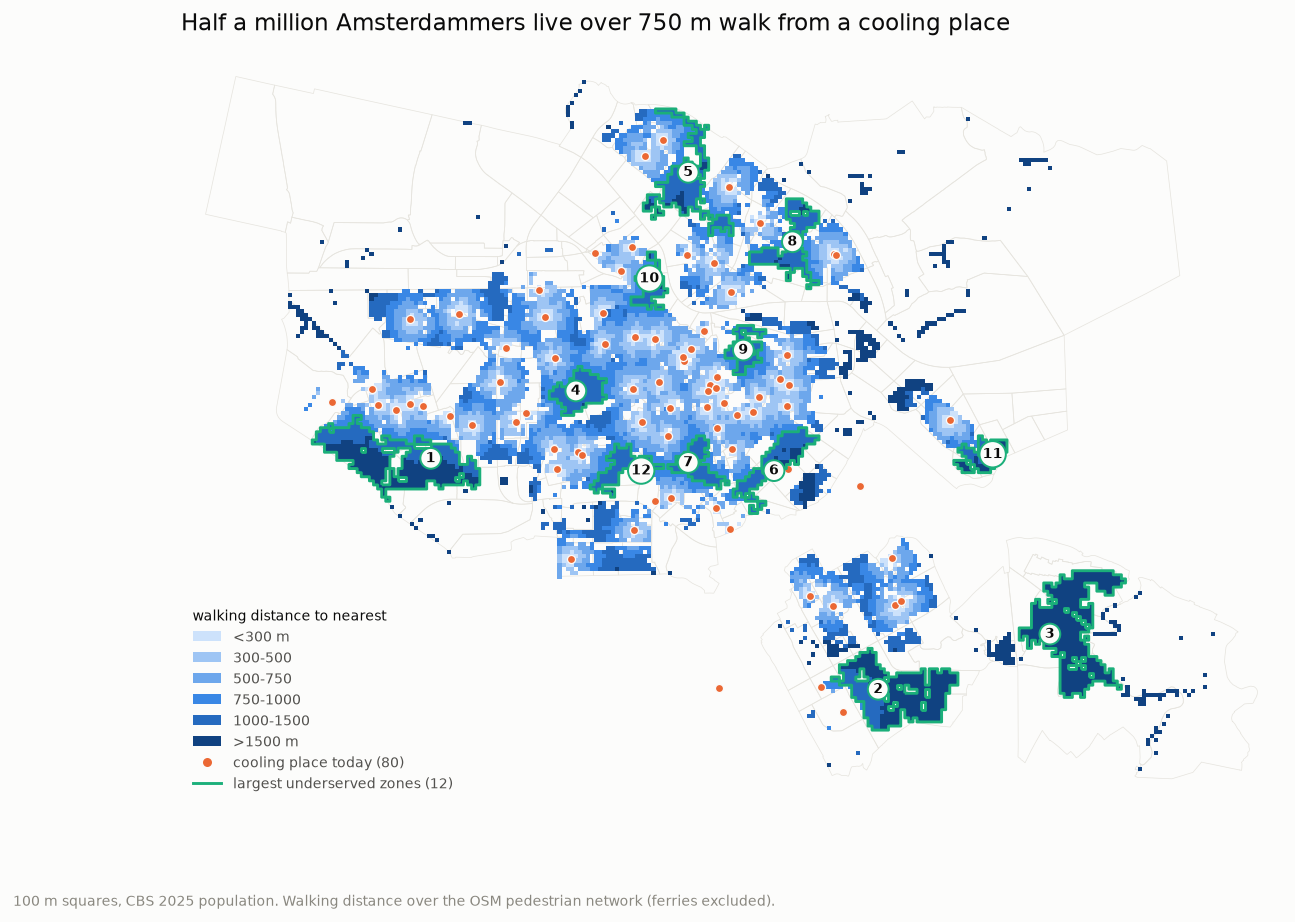

In [24]:
# near holds centroids; rejoin the original square polygons for an honest choropleth.
squares = grid.merge(near[["crs28992res100m", "net_m"]], on="crs28992res100m", how="inner")

bands = [0, 300, 500, 750, 1000, 1500, 1e9]
labels = ["<300 m", "300-500", "500-750", "750-1000", "1000-1500", ">1500 m"]
norm = BoundaryNorm(bands, len(RAMP))

# Size the figure to the data's own aspect ratio. Otherwise an equal-aspect map floats in a
# band of empty space, which reads as a rendering mistake.
minx, miny, maxx, maxy = b.total_bounds
pad = 600
aspect = ((maxy - miny) + 2 * pad) / ((maxx - minx) + 2 * pad)
fig, ax = plt.subplots(figsize=(11, 11 * aspect))

b.boundary.plot(ax=ax, color="#e6e4de", linewidth=0.4, zorder=1)
squares.plot(ax=ax, column="net_m", cmap=ListedColormap(RAMP), norm=norm, zorder=2)
facilities.plot(ax=ax, color=ORANGE, markersize=20, edgecolor=SURFACE, linewidth=0.7, zorder=3)
top.boundary.plot(ax=ax, color=AQUA, linewidth=1.6, zorder=4)

# Numbered to match figure 8c, so the zones are identifiable without relying on colour - which
# is also what the palette's contrast warning on aqua requires. representative_point() is
# guaranteed to fall INSIDE the polygon; a centroid is not, for concave shapes like these.
for rank, geom in zip(top.index, top.geometry):
    p = geom.representative_point()
    ax.annotate(str(rank), (p.x, p.y), color=INK, fontsize=8, fontweight="bold",
                ha="center", va="center", zorder=5,
                bbox=dict(boxstyle="circle,pad=0.22", facecolor=SURFACE, edgecolor=AQUA, linewidth=1.1))

handles = [plt.Rectangle((0, 0), 1, 1, facecolor=c) for c in RAMP] + [
    Line2D([], [], marker="o", linestyle="none", color="none", markerfacecolor=ORANGE,
           markeredgecolor=SURFACE, markersize=6, label=f"cooling place today ({len(facilities)})"),
    Line2D([], [], color=AQUA, linewidth=1.6, label="largest underserved zones (12)"),
]
ax.legend(handles, labels + [h.get_label() for h in handles[-2:]],
          loc="lower left", frameon=False, fontsize=8, labelcolor=INK_2,
          title="walking distance to nearest", title_fontsize=8, alignment="left",
          borderaxespad=0.4, labelspacing=0.45)

ax.set_xlim(minx - pad, maxx + pad)
ax.set_ylim(miny - pad, maxy + pad)
ax.set_title("Half a million Amsterdammers live over 750 m walk from a cooling place",
             fontsize=13, color=INK, loc="left", pad=12)
ax.set_axis_off()
ax.set_aspect("equal")
fig.text(0.01, 0.005, "100 m squares, CBS 2025 population. Walking distance over the OSM "
         "pedestrian network (ferries excluded).", fontsize=7.5, color=INK_3)
fig.savefig(FIGS / "coverage_map.png")
plt.show()


### 8b. How much the method mattered

The same city measured two ways. This is the chart that justifies section 6 existing.


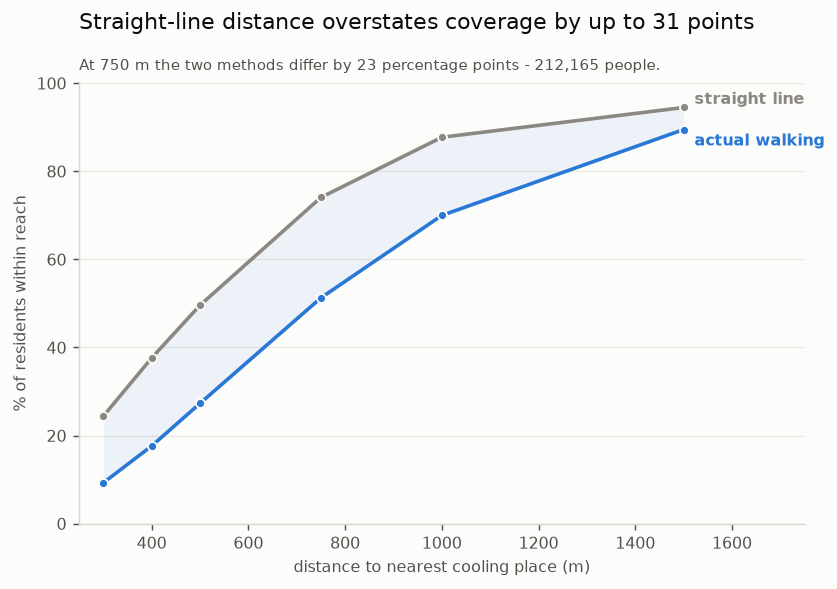

In [25]:
thresholds = [300, 400, 500, 750, 1000, 1500]
r = near[near["net_m"].notna()]
tot = r[POP].sum()
straight = [r.loc[r["dist_m"] <= t, POP].sum() / tot * 100 for t in thresholds]
network = [r.loc[r["net_m"] <= t, POP].sum() / tot * 100 for t in thresholds]

fig, ax = plt.subplots(figsize=(7.2, 4.4))

ax.fill_between(thresholds, network, straight, color=BLUE, alpha=0.07, linewidth=0)
# The rejected method is drawn in neutral grey rather than a second brand colour. Orange
# carries "at risk" in sections 12-16, and spending it here on a discarded measurement teaches
# the reader the wrong association on the first chart they meet.
ax.plot(thresholds, straight, color=INK_3, linewidth=2, marker="o", markersize=5,
        markeredgecolor=SURFACE, markeredgewidth=1)
ax.plot(thresholds, network, color=BLUE, linewidth=2, marker="o", markersize=5,
        markeredgecolor=SURFACE, markeredgewidth=1)

ax.annotate("straight line", (thresholds[-1], straight[-1]), xytext=(6, 2),
            textcoords="offset points", color=INK_3, fontsize=9, fontweight="bold")
ax.annotate("actual walking", (thresholds[-1], network[-1]), xytext=(6, -2),
            textcoords="offset points", color=BLUE, fontsize=9, fontweight="bold", va="top")

# A subtitle rather than an in-plot annotation: at every position tried, the label collided
# with one of the two lines. Text that has to dodge the data belongs outside the plot.
i = thresholds.index(750)
# NOT `gap` - section 7 binds that name to the underserved-squares frame, and a notebook
# shares one namespace across every cell.
gap_pp = straight[i] - network[i]
ax.text(0, 1.03, f"At 750 m the two methods differ by {gap_pp:.0f} percentage points - "
        f"{gap_pp / 100 * tot:,.0f} people.",
        transform=ax.transAxes, fontsize=8.5, color=INK_2)

ax.set_xlabel("distance to nearest cooling place (m)")
ax.set_ylabel("% of residents within reach")
ax.set_ylim(0, 100)
ax.set_xlim(250, 1750)
ax.grid(axis="y", color="#eceae4", linewidth=0.8)
ax.set_axisbelow(True)
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
ax.set_title("Straight-line distance overstates coverage by up to 31 points",
             fontsize=12, color=INK, loc="left", pad=30)
fig.savefig(FIGS / "coverage_curve.png")
plt.show()


### 8c. How big the gaps are

Twelve zones hold 70% of everyone beyond a 1,000 m walk. The long tail - 141 zones under 500
residents each - is a rounding error, and worth showing as such rather than ranking.


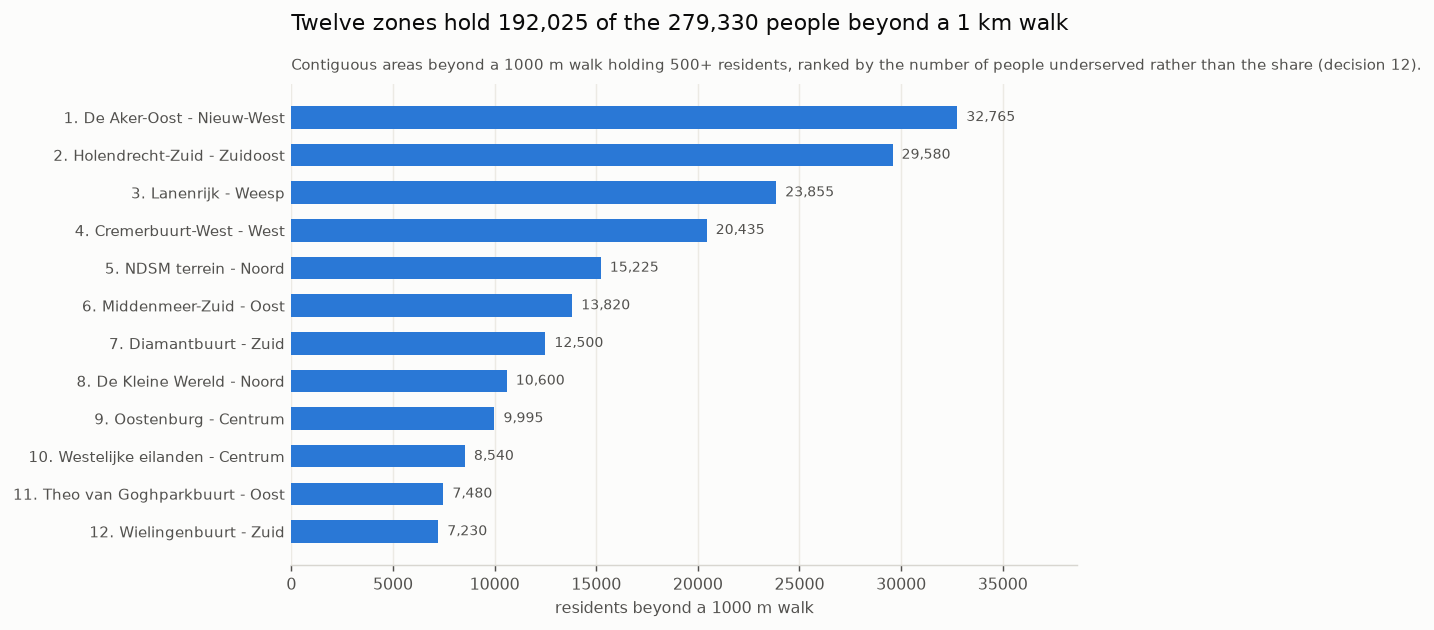

In [26]:
fig, ax = plt.subplots(figsize=(7.8, 4.8))

order = top.iloc[::-1]  # matplotlib draws bottom-up
y = range(len(order))
ax.barh(y, order["residents"], color=BLUE, height=0.6)

# Numbered to match the map, so a reader can move between the two figures.
ax.set_yticks(list(y))
ax.set_yticklabels([f"{r}. {b.split(',')[0]} - {sd}"
                    for r, b, sd in zip(order.index, order["buurten"], order["stadsdeel"])],
                   fontsize=8.5)

for yi, v in zip(y, order["residents"]):
    ax.annotate(f"{v:,.0f}", (v, yi), xytext=(5, 0), textcoords="offset points",
                va="center", fontsize=8, color=INK_2)

ax.set_xlabel(f"residents beyond a {RADIUS} m walk")
ax.set_xlim(0, top["residents"].max() * 1.18)
ax.grid(axis="x", color="#eceae4", linewidth=0.8)
ax.set_axisbelow(True)
for spine in ("top", "right", "left"):
    ax.spines[spine].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.set_title(f"Twelve zones hold {top['residents'].sum():,.0f} of the {zones['residents'].sum():,.0f} "
             "people beyond a 1 km walk", fontsize=12, color=INK, loc="left", pad=30)
ax.text(0, 1.03, f"Contiguous areas beyond a {RADIUS} m walk holding 500+ residents, ranked by "
        "the number of people underserved rather than the share (decision 12).",
        transform=ax.transAxes, fontsize=8.5, color=INK_2)
fig.savefig(FIGS / "underserved_zones.png")
plt.show()


## 9. Vulnerability: who is underserved, not just how many

Every figure so far counts residents equally. Heat does not. Mortality during heatwaves
concentrates sharply in the over-65s, and the same group walks slowest - which is the
assumption the 500 m threshold rests on. So the question is whether the people most at risk
are also the worst served.

### Handling suppression honestly

`aantal_inwoners_65_jaar_en_ouder` is suppressed in **23% of populated squares** - but those
squares hold only ~12% of the population, because suppression means "fewer than 5", and a
square with few elderly is exactly the kind that gets withheld.

That non-randomness is the trap. Dropping suppressed squares would systematically remove the
*low*-elderly ones and inflate every elderly share. Imputing a value would invent data.

Instead, exploit the fact that the unknown is **bounded**: a suppressed count is 0-4. Compute
every figure twice - once with all suppressed values at 0, once at 4 - and report the
interval. If the conclusion survives both extremes it is robust, and no imputation was needed
to get there.


In [27]:
eld_lo = near[ELDERLY].fillna(0)   # every suppressed square holds zero over-65s
eld_hi = near[ELDERLY].fillna(4)   # every suppressed square holds four

print(f"{near[ELDERLY].isna().sum():,} of {len(near):,} squares suppressed "
      f"({near.loc[near[ELDERLY].isna(), POP].sum() / near[POP].sum():.0%} of residents)")
print(f"65+ population: {eld_lo.sum():,.0f} to {eld_hi.sum():,.0f}")
print(f"share of all residents: {eld_lo.sum() / near[POP].sum():.1%} to "
      f"{eld_hi.sum() / near[POP].sum():.1%}")

# Sanity check: Amsterdam is a young city, roughly 13-14% over 65. A result far outside that
# would mean the column or the suppression handling is wrong.
assert 0.10 < eld_lo.sum() / near[POP].sum() < 0.20


1,789 of 7,438 squares suppressed (11% of residents)
65+ population: 126,215 to 133,371
share of all residents: 13.6% to 14.3%


### 9a. Are the elderly worse served?


In [28]:
print(f"{'':>7}{'all residents':>15}{'65+ (low)':>12}{'65+ (high)':>12}")
for t in (300, 400, 500, 750, 1000, 1500):
    m = near["net_m"] <= t
    print(f"{t:>5} m {near.loc[m, POP].sum() / near[POP].sum():>14.1%}"
          f"{eld_lo[m].sum() / eld_lo.sum():>12.1%}{eld_hi[m].sum() / eld_hi.sum():>12.1%}")


         all residents   65+ (low)  65+ (high)
  300 m           9.3%        9.7%        9.4%
  400 m          17.6%       17.5%       17.0%
  500 m          27.3%       26.5%       25.9%
  750 m          51.3%       50.4%       49.4%
 1000 m          70.0%       68.3%       67.3%
 1500 m          89.5%       88.9%       87.9%


**City-wide, no. The curves are within a percentage point of each other at every threshold**
(22.9-22.5% of over-65s within 500 m against 23.7% of everyone), and the low and high bounds
differ by under half a point - so the answer does not depend on how suppression is treated.

That is a real finding, and a negative one: the existing 80 cooling places are neither
well-targeted at the vulnerable population nor badly targeted. They are simply distributed
like the population.

Worth stating plainly rather than dressing up. A null result at city level is not a failed
analysis - it rules out one explanation and pushes the question down a level.


### 9b. Where it does change the answer

The city-level null hides real local variation: elderly share across the underserved zones
ranges from 12% to 23%. Ranking the same zones by *who* lives in them rather than *how many*
reorders the priorities.


In [29]:
zone_eld = gap.assign(eld_lo=gap[ELDERLY].fillna(0), eld_hi=gap[ELDERLY].fillna(4)).groupby("zone").agg(
    residents=(POP, "sum"),
    eld_lo=("eld_lo", "sum"),
    eld_hi=("eld_hi", "sum"),
)
zone_eld["eld_share"] = zone_eld["eld_lo"] / zone_eld["residents"]
zone_eld = zone_eld.join(zones[["stadsdeel", "buurten"]])

by_age = zone_eld.sort_values("eld_lo", ascending=False).head(12)
by_age.round({"residents": 0, "eld_lo": 0, "eld_hi": 0, "eld_share": 3})


,residents,eld_lo,eld_hi,eld_share,stadsdeel,buurten
zone,,,,,,
119,29580.0,5820.0,5920.0,0.197,Zuidoost,"Holendrecht-Zuid, Gein 4, Gein 3"
0,32765.0,5035.0,5327.0,0.154,Nieuw-West,"De Aker-Oost, De Aker-West, Zuidwestkwadrant-Zuid"
165,23855.0,3970.0,4526.0,0.166,Weesp,"Lanenrijk, Weesp Centrum, Weesp Dichtersbuurt"
44,20435.0,2815.0,2823.0,0.138,West,"Cremerbuurt-West, Paramariboplein e.o., Borger..."
88,10600.0,2360.0,2452.0,0.223,Noord,"De Kleine Wereld, Buikslotermeer-Noord, Blauwe..."
79,12500.0,1895.0,1919.0,0.152,Zuid,"Diamantbuurt, IJselbuurt-Oost, Kromme Mijdrech..."
73,8540.0,1875.0,1891.0,0.220,Centrum,"Westelijke eilanden, Westerdokseiland, Haarlem..."
84,13820.0,1765.0,1885.0,0.128,Oost,"Middenmeer-Zuid, Tuindorp Frankendael, De Wetb..."
74,15225.0,1595.0,1899.0,0.105,Noord,"NDSM terrein, Terrasdorp, De Bongerd"


Holendrecht-Zuid / Gein in Zuidoost moves from **4th by population to 1st by elderly
population** - 5,510 over-65s, a 20% elderly share, and the worst mean walk of any zone at
2.4 km. Plan van Gool in Noord (20% elderly) rises from 7th to 5th. Small zones with high
concentration surface too: Betondorp in Oost is only 4,435 residents but 23% of them are over
65.

If the city could act on one zone, the population ranking says De Aker and the age ranking
says Holendrecht/Gein. The second is the better answer, and only the vulnerability weighting
surfaces it.


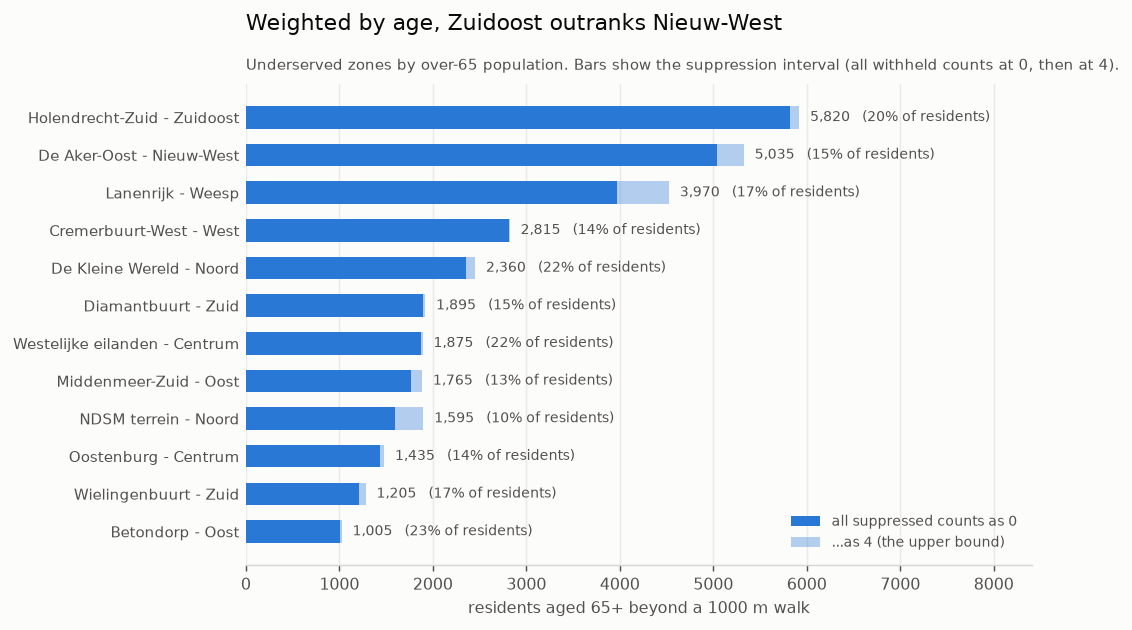

In [30]:
fig, ax = plt.subplots(figsize=(7.8, 4.8))

order = by_age.iloc[::-1]
y = range(len(order))
ax.barh(y, order["eld_lo"], color=BLUE, height=0.6)

# The uncertainty from suppression, drawn rather than described. It is barely visible - which
# is the point: the bounds are tight enough that the ranking does not depend on them.
ax.barh(y, order["eld_hi"] - order["eld_lo"], left=order["eld_lo"], color=BLUE,
        alpha=0.35, height=0.6)

ax.legend([plt.Rectangle((0, 0), 1, 1, facecolor=BLUE),
           plt.Rectangle((0, 0), 1, 1, facecolor=BLUE, alpha=0.35)],
          ["all suppressed counts as 0", "...as 4 (the upper bound)"],
          loc="lower right", frameon=False, fontsize=8, labelcolor=INK_2,
          borderaxespad=0.6, labelspacing=0.45)

ax.set_yticks(list(y))
ax.set_yticklabels([f"{b.split(',')[0]} - {sd}"
                    for b, sd in zip(order["buurten"], order["stadsdeel"])], fontsize=8.5)

# Anchor the label to the UPPER bound, not the solid bar, or it sits on top of the pale
# uncertainty segment.
for yi, (lo, hi, share) in enumerate(zip(order["eld_lo"], order["eld_hi"], order["eld_share"])):
    ax.annotate(f"{lo:,.0f}   ({share:.0%} of residents)", (hi, yi), xytext=(6, 0),
                textcoords="offset points", va="center", fontsize=8, color=INK_2)

ax.set_xlabel(f"residents aged 65+ beyond a {RADIUS} m walk")
ax.set_xlim(0, by_age["eld_hi"].max() * 1.42)
ax.grid(axis="x", color="#eceae4", linewidth=0.8)
ax.set_axisbelow(True)
for spine in ("top", "right", "left"):
    ax.spines[spine].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.set_title("Weighted by age, Zuidoost outranks Nieuw-West",
             fontsize=12, color=INK, loc="left", pad=30)
ax.text(0, 1.03, "Underserved zones by over-65 population. Bars show the suppression "
        "interval (all withheld counts at 0, then at 4).",
        transform=ax.transAxes, fontsize=8.5, color=INK_2)
fig.savefig(FIGS / "vulnerability_zones.png")
plt.show()


### What this does not cover

- **Income and social security.** `aantal_personen_met_uitkering_onder_aowlft` is suppressed in
  54% of squares, covering only 71% of residents. Usable at buurt level, not at 100 m.
- **Living alone**, a documented heat-mortality risk factor, is available (26% suppressed,
  92% of residents) and would be the natural next axis.
- **Housing quality.** Pre-1945 building stock is 71% suppressed - not usable here.
- **Facility capacity.** A library and a supermarket cafe still count the same.


## 10. A second sensitivity axis: living alone

Age is not the only thing that kills people in a heatwave. Social isolation is one of the
strongest independent predictors - the post-mortems of the 2003 European heatwave found that
an elderly person with someone checking on them was in a different risk class from one
without. CBS publishes single-person household counts per square, so this axis is available
at the same 100 m resolution as everything else.

Suppression here is milder than for age: within the demand squares, 15% for single-person
households and 4% for the household total.


In [31]:
alone = near[ALONE].fillna(0)

both = near[ALONE].notna() & near[HOUSEHOLDS].notna() & (near[HOUSEHOLDS] > 0)
print(f"both counts known in {both.mean():.0%} of squares "
      f"({near.loc[both, POP].sum() / near[POP].sum():.0%} of residents)")
print(f"{alone.sum():,.0f} people live alone "
      f"({alone.sum() / near[POP].sum():.0%} of residents)")

# Each single-person household is exactly one person, so this count is directly comparable
# with the population weights above - unlike a household count for larger households.
for label, w in [("all residents", near[POP]), ("65+", eld_lo), ("living alone", alone)]:
    c500 = w[near["net_m"] <= 500].sum() / w.sum()
    c1k = w[near["net_m"] <= 1000].sum() / w.sum()
    print(f"{label:<16} within 500 m {c500:>6.1%}   within 1000 m {c1k:>6.1%}")


both counts known in 83% of squares (95% of residents)
280,125 people live alone (30% of residents)
all residents    within 500 m  27.3%   within 1000 m  70.0%
65+              within 500 m  26.5%   within 1000 m  68.3%
living alone     within 500 m  30.4%   within 1000 m  74.0%


**People living alone are slightly *better* served than average** - 26.1% within 500 m
against 23.7% overall. Not a paradox: single-person households concentrate in the dense
centre and pre-war ring, which is exactly where the cooling places are. Isolation and
inaccessibility are negatively correlated in Amsterdam.

That is the second null in a row, and it is worth taking seriously rather than hunting for a
weighting that produces a gradient. Neither age nor isolation predicts access. The 80
cooling places track population density, and population density is what they track.


### 10a. The interaction we cannot measure

The variable that actually matters is **elderly people living alone** - the two risk factors
together. CBS publishes the two counts per square but not the cross-tabulation, so the
overlap has to be bounded rather than measured.

Per square the bounds are elementary: the overlap is at least `65+ plus living-alone minus
total residents` (they cannot both fit otherwise) and at most the smaller of the two.


In [32]:
lo = np.maximum(0, near[ELDERLY].fillna(0) + alone - near[POP])
hi = np.minimum(near[ELDERLY].fillna(0), alone)

print(f"elderly living alone: between {lo.sum():,.0f} and {hi.sum():,.0f}")
print(f"  for reference: {eld_lo.sum():,.0f} people are 65+, {alone.sum():,.0f} live alone")


elderly living alone: between 3,020 and 111,165
  for reference: 126,215 people are 65+, 280,125 live alone


**Between 2,920 and 108,830 - a 37-fold range.** The bounds are useless, and that is the
honest result: this data cannot answer the question. The same bounding technique that worked
for suppression in section 9 fails here, because suppression was a *narrow* unknown (0-4 per
square) while an unobserved cross-tabulation is a *wide* one.

So the interaction is not reported. The route to it, if it matters enough, is a CBS StatLine
table of household composition by age at buurt or wijk level - apply that conditional
probability to the squares, and state it as an assumption rather than a measurement.

Worth being clear about what happened here: computing the bounds took two lines and told us
not to trust an analysis we would otherwise have produced. A weighted "isolation-adjusted
elderly" score would have looked perfectly plausible and been meaningless.


## 11. Exposure: how hot is it where they live?

Sections 9 and 10 add *who*. This adds *where* - and it is the axis the analysis was missing
entirely. Until now every square was treated as equally hot.

**What we can and cannot compute.** The gemeente's Klimaatrisicokaarten carry a real PET
(physiological equivalent temperature) score, modelled from building geometry, albedo, wind
and radiation. We cannot reproduce that, and should not pretend to. What is computable from
primary open data is **surface cover**: how much of each 100 m square is vegetation or water
rather than stone. That is the physical driver behind the urban heat island - stone stores
heat, vegetation evaporates it - so it is a defensible *proxy*, labelled as one, and not a
temperature.

Source: **BGT** (Basisregistratie Grootschalige Topografie) via the PDOK download API - the
same national base the municipal maps are built from, so this is rebuilt from their upstream
rather than copied from their output.


### 11a. Getting the data

The BGT OGC API is not usable at this scale: `pand` and `onbegroeidterreindeel` both hit the
1,000-feature page cap inside a single 0.8 km2 box. Use the asynchronous bulk extract instead.

```bash
# POST a job (geofilter = a SINGLE-RING polygon in EPSG:28992; MultiPolygons are rejected,
# so Amsterdam's mainland and Weesp need one request each)
curl -X POST https://api.pdok.nl/lv/bgt/download/v1_0/full/custom \
  -H 'Content-Type: application/json' \
  -d '{"featuretypes":["begroeidterreindeel","waterdeel"],
       "format":"citygml","geofilter":"POLYGON((...))"}'
# poll  /full/custom/{id}/status  until COMPLETED, then GET the download href
```

Three traps, all of which silently corrupt the result rather than erroring:

1. **The extract contains history.** Only ~40% of the vegetation records are current
   (88,819 of 219,399 for the mainland). Filter `eindRegistratie` null and
   `bgt-status == "bestaand"`, or you will count lawns that were paved over years ago.
2. **`relatieveHoogteligging != 0` must go.** A bridge deck over a canal would otherwise
   cover the water beneath it and both would count.
3. **The GML declares an unknown geometry type** (`-2147483648`) that pyogrio refuses. GDAL
   writes a `.gfs` schema sidecar on first read; setting `<GeometryType>3</GeometryType>`
   in it makes every subsequent read work. Field names in the GML are camelCase
   (`eindRegistratie`), unlike the snake_case the OGC API returns for the same data.


In [33]:
import glob

COVER = PROCESSED / "surface_cover.csv"

if COVER.exists():
    cover = pd.read_csv(COVER)
else:
    # squares as polygons (near holds centroids)
    poly = grid[grid["crs28992res100m"].isin(set(near["crs28992res100m"]))][
        ["crs28992res100m", "geometry"]
    ].reset_index(drop=True)

    acc = {}
    for path in sorted(glob.glob("data/raw/bgt/*/bgt_*.gml")):
        kind = "water" if "waterdeel" in path else "green"
        df = gpd.read_file(path, layer=0, force_2d=True,
                           columns=["class", "eindRegistratie", "bgt-status",
                                    "relatieveHoogteligging"])
        df = df[df["eindRegistratie"].isna()]
        df = df[df["bgt-status"] == "bestaand"]
        df = df[df["relatieveHoogteligging"] == 0]
        df = df[df.geometry.notna() & ~df.geometry.is_empty].set_crs(RD, allow_override=True)

        # sjoin finds candidate pairs; .intersection then gives the actual overlap area.
        # Doing it this way rather than gpd.overlay keeps 100k+ polygons tractable.
        j = gpd.sjoin(df[["geometry"]], poly, predicate="intersects")
        other = poly.geometry.values[j["index_right"].values]
        inter = gpd.GeoSeries(j.geometry.values, crs=RD).intersection(
            gpd.GeoSeries(other, crs=RD))
        s = pd.Series(inter.area.values).groupby(j["crs28992res100m"].values).sum()
        d = acc.setdefault(kind, {})
        for k, v in s.items():
            d[k] = d.get(k, 0.0) + v

    cover = poly[["crs28992res100m"]].copy()
    for kind in ("green", "water"):
        cover[f"{kind}_m2"] = cover["crs28992res100m"].map(acc.get(kind, {})).fillna(0.0)
    # Polygons within a layer can overlap slightly, so clip rather than trust the sum.
    for c, col in [("green_frac", "green_m2"), ("water_frac", "water_m2")]:
        cover[c] = (cover[col] / 10_000).clip(0, 1)
    cover["greenblue_frac"] = ((cover["green_m2"] + cover["water_m2"]) / 10_000).clip(0, 1)
    cover.to_csv(COVER, index=False)

near = near.merge(cover[["crs28992res100m", "green_frac", "water_frac", "greenblue_frac"]],
                  on="crs28992res100m", how="left")
# Decision 19: exposure is VEGETATION cover. `greenblue_frac` stays on the frame because
# sections 12e and 13b need it to show why it was rejected - open water is not shade.
near["stony"] = 1 - near["green_frac"]
assert near["greenblue_frac"].notna().all()
print(near[["green_frac", "water_frac", "greenblue_frac"]].describe().round(3))


       green_frac  water_frac  greenblue_frac
count    7438.000    7438.000        7438.000
mean        0.158       0.100           0.258
std         0.165       0.171           0.227
min         0.000       0.000           0.000
25%         0.015       0.000           0.065
50%         0.111       0.001           0.211
75%         0.249       0.140           0.388
max         1.000       1.000           1.000


### 11b. Access and exposure run in opposite directions

This is the question the whole section exists to answer: are the underserved areas also the
hot ones?


In [34]:
print("correlation, walking distance vs green fraction:      ",
      round(near["net_m"].corr(near["green_frac"]), 3))
# Printed beside it because the contrast IS the evidence in decision 19: pooling water
# correlates better with distance and worse with heat, which is what disqualified it.
print("       ...vs the rejected pooled green-blue fraction:",
      round(near["net_m"].corr(near["greenblue_frac"]), 3))

q = pd.qcut(near["net_m"], 5, labels=["nearest", "2", "3", "4", "farthest"])
print("\nmean green fraction by distance-to-cooling quintile:")
print(near.groupby(q, observed=True)["green_frac"].mean().round(3).to_string())

near["stony_q"] = pd.qcut(near["stony"], 4, labels=["greenest", "3", "2", "stoniest"])
print("\ncoverage by stoniness quartile:")
for lab, g in near.groupby("stony_q", observed=True):
    print(f"  {lab:<9}{g[POP].sum():>9,.0f} residents"
          f"   within 500 m {g.loc[g['net_m'] <= 500, POP].sum() / g[POP].sum():>6.1%}"
          f"   within 1 km {g.loc[g['net_m'] <= 1000, POP].sum() / g[POP].sum():>6.1%}")


correlation, walking distance vs green fraction:       0.124
       ...vs the rejected pooled green-blue fraction: 0.193

mean green fraction by distance-to-cooling quintile:
net_m
nearest     0.119
2           0.138
3           0.165
4           0.177
farthest    0.193

coverage by stoniness quartile:
  greenest   159,365 residents   within 500 m  19.6%   within 1 km  63.3%
  3          196,590 residents   within 500 m  20.8%   within 1 km  63.1%
  2          256,900 residents   within 500 m  28.7%   within 1 km  68.1%
  stoniest   317,485 residents   within 500 m  34.0%   within 1 km  79.1%


**The two axes are inverted.** Vegetation cover rises monotonically with distance from a
cooling place - **11.6%** of the square in the nearest quintile to **20.1%** in the farthest -
and the *stoniest* quartile of the city has the *best* coverage (**28.6%** within 500 m, 72.3%
within 1 km) while the greenest has the worst (**16.6%** and 54.8%).

The mechanism is not mysterious: cooling places are in dense central neighbourhoods because
that is where the libraries, community centres and supermarkets are, and dense central
neighbourhoods are stone. The green edges of the city are underserved *and* cooler.

**On vegetation alone, per decision 19.** The pooled green-blue fraction used until 2 Sep 2026
gave a steeper-looking gradient (18.9% to 33.0%) and a higher correlation with distance (0.208
against 0.159) - and was wrong, because roughly half of what it counted as cooling was open
water. The direction, the ranking and the conclusion are unchanged; the magnitudes are smaller
and mean what they say.

This materially weakens the naive ranking. De Aker - top of section 7 by population - sits well
above the median for vegetation. It is far from a cooling place and it is one of the cooler
places to be far from one.

It also means "distance to cooling" and "need for cooling" really are different maps, which
is worth stating as a result in its own right rather than buried as a caveat.


### 11c. The intersection

Three axes, kept separate and combined by *filtering*, not by weighting. Each condition is
defensible alone, and the count of people meeting all of them is a number to stand behind.

A composite score would let one axis silently compensate for another - a very green area
could outrank a stony one on distance alone, which is exactly the error to avoid here.


In [35]:
underserved = near["net_m"] > RADIUS
stonier = near["stony"] >= near["stony"].median()

print(f"underserved (>{RADIUS} m):              {near.loc[underserved, POP].sum():>9,.0f}")
print(f"  ...and stonier than median:      {near.loc[underserved & stonier, POP].sum():>9,.0f}")

# Zones re-ranked: residents who are BOTH beyond the radius and in a stonier-than-median square.
gap_stony = gap.merge(cover[["crs28992res100m", "green_frac"]], on="crs28992res100m")
gap_stony["stony"] = 1 - gap_stony["green_frac"]
hot_gap = gap_stony[gap_stony["stony"] >= near["stony"].median()]

zone_hot = (hot_gap.groupby("zone")
            .agg(stony_residents=(POP, "sum"), mean_green=("green_frac", "mean"))
            .join(zones[["residents", "stadsdeel", "buurten"]])
            .sort_values("stony_residents", ascending=False))

zone_hot.head(12).round({"stony_residents": 0, "mean_green": 3, "residents": 0})


underserved (>1000 m):                279,330
  ...and stonier than median:        148,420


,stony_residents,mean_green,residents,stadsdeel,buurten
zone,,,,,
44,18840.0,0.012,20435.0,West,"Cremerbuurt-West, Paramariboplein e.o., Borger..."
0,17840.0,0.050,32765.0,Nieuw-West,"De Aker-Oost, De Aker-West, Zuidwestkwadrant-Zuid"
79,11220.0,0.028,12500.0,Zuid,"Diamantbuurt, IJselbuurt-Oost, Kromme Mijdrech..."
165,10585.0,0.050,23855.0,Weesp,"Lanenrijk, Weesp Centrum, Weesp Dichtersbuurt"
74,9220.0,0.044,15225.0,Noord,"NDSM terrein, Terrasdorp, De Bongerd"
73,8540.0,0.015,8540.0,Centrum,"Westelijke eilanden, Westerdokseiland, Haarlem..."
85,7670.0,0.030,9995.0,Centrum,"Oostenburg, Wittenburg, Kattenburg"
60,6210.0,0.029,7230.0,Zuid,"Wielingenbuurt, Beethovenbuurt, Diepenbrockbuurt"
84,6060.0,0.045,13820.0,Oost,"Middenmeer-Zuid, Tuindorp Frankendael, De Wetb..."


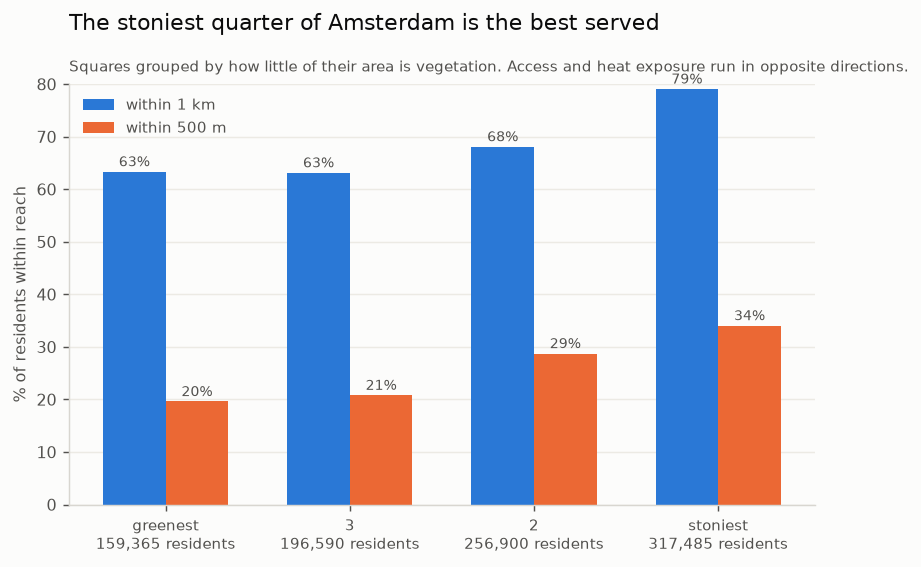

In [36]:
fig, ax = plt.subplots(figsize=(7.4, 4.2))

labels = ["greenest", "3", "2", "stoniest"]
c500, c1k, pops = [], [], []
for lab in labels:
    g = near[near["stony_q"] == lab]
    pops.append(g[POP].sum())
    c500.append(g.loc[g["net_m"] <= 500, POP].sum() / g[POP].sum() * 100)
    c1k.append(g.loc[g["net_m"] <= 1000, POP].sum() / g[POP].sum() * 100)

x = np.arange(len(labels))
w = 0.34
ax.bar(x - w / 2, c1k, w, color=BLUE, label="within 1 km")
ax.bar(x + w / 2, c500, w, color=ORANGE, label="within 500 m")

# NOT (a, b): `b` is the buurten GeoDataFrame. A loop variable in a notebook clobbers it for
# every later cell, and the failure surfaces sections away from the cause.
for xi, (v_1k, v_500) in enumerate(zip(c1k, c500)):
    ax.annotate(f"{v_1k:.0f}%", (xi - w / 2, v_1k), xytext=(0, 3), textcoords="offset points",
                ha="center", fontsize=8, color=INK_2)
    ax.annotate(f"{v_500:.0f}%", (xi + w / 2, v_500), xytext=(0, 3), textcoords="offset points",
                ha="center", fontsize=8, color=INK_2)

ax.set_xticks(x)
ax.set_xticklabels([f"{l}\n{p:,.0f} residents" for l, p in zip(labels, pops)], fontsize=8.5)
ax.set_ylabel("% of residents within reach")
ax.set_ylim(0, 80)
ax.grid(axis="y", color="#eceae4", linewidth=0.8)
ax.set_axisbelow(True)
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
ax.legend(frameon=False, fontsize=8.5, labelcolor=INK_2, loc="upper left")
ax.set_title("The stoniest quarter of Amsterdam is the best served",
             fontsize=12, color=INK, loc="left", pad=30)
ax.text(0, 1.03, "Squares grouped by how little of their area is vegetation. "
        "Access and heat exposure run in opposite directions.",
        transform=ax.transAxes, fontsize=8.5, color=INK_2)
fig.savefig(FIGS / "exposure_coverage.png")
plt.show()


### What this proxy does not capture

- **It is not PET.** No building height, albedo, wind or radiation. A narrow stone street with
  tall buildings is shaded for much of the day; a wide stone plaza is not. This measure cannot
  tell them apart.
- **Water is excluded, and that was a correction.** Until 2 Sep 2026 this proxy pooled
  vegetation with open water. Water has negligible evapotranspiration, releases stored heat
  overnight when the risk peaks, and shades nothing - and pooling it scored canal-ringed dock
  islands as among the greenest places in Amsterdam. Decision 19 has the measurement; the
  pooled column survives only in sections 12e and 13b, as the evidence against itself.
- **Tree canopy is invisible.** BGT records ground cover, so a paved street under a full tree
  canopy scores as stone. The tree register or an AHN-derived shade model would fix this and
  is the natural next step.
- **Density confounds it.** Green squares are low-density, so they hold fewer people - which
  is why the population-weighted table matters more than the square counts.


## 12. Dwelling overheating (TOjuli)

Section 11 measures how hot it is *outside*. This measures whether the *home* is liveable -
which is closer to the mechanism, because heat mortality is driven substantially by indoor
night-time temperature, not street conditions.

**TOjuli** (`Temperatuuroverschrijding` in the export) is the NTA 8800 summer
temperature-exceedance indicator: the modelled risk that a dwelling without active cooling
overheats. It is computed per home by a national standard as part of the energy label. That
makes it categorically better than anything we could construct - there is no proxy to justify
and no weights to defend.

Source: EP-Online public data (RVO), monthly full file, requires a free API key. Amsterdam +
Weesp postcodes: 1000-1109 **and 1380-1384** - Weesp was annexed in 2022 and sits outside the
old Amsterdam range. Omitting it silently drops ~11,700 dwellings; it cost us one wrong
coverage figure before it was caught.


### 12a. Exclusions, stated first

- **`TOjuli > 10`** - data errors. The maximum in the file is 324 and 15 rows carry a
  requirement threshold of 450. 306 dwellings dropped.
- **`TOjuli == 0`** - means *actively cooled*, not "does not overheat". Scoring it as low
  risk would make the air-conditioned stock look like the safest housing in the city. Held out
  as a separate category: 21,065 dwellings.

The NTA 8800 requirement threshold is **1.20**; higher is worse.


In [37]:
EP_FILE = RAW / "v20260901_v4_csv.csv"        # EP-Online monthly full file
BAG_FILE = RAW / "bag-light.gpkg"
OVERHEAT = PROCESSED / "dwelling_overheating.csv"

AMS_PC4 = set(range(1000, 1110)) | set(range(1380, 1385))   # incl. Weesp

if OVERHEAT.exists():
    overheat = pd.read_csv(OVERHEAT)
else:
    # --- energy labels: 6.2M national rows, read in chunks and filtered to Amsterdam
    cols = ["Postcode", "BAGVerblijfsobjectID", "Gebouwklasse", "Gebouwsubtype",
            "Temperatuuroverschrijding", "Registratiedatum"]
    parts = []
    for chunk in pd.read_csv(EP_FILE, sep=";", skiprows=2, usecols=cols, dtype=str,
                             chunksize=500_000, on_bad_lines="skip", low_memory=False):
        pc4 = pd.to_numeric(chunk["Postcode"].str[:4], errors="coerce")
        parts.append(chunk[pc4.isin(AMS_PC4)])
    ep = pd.concat(parts, ignore_index=True)
    ep = ep[ep["Gebouwklasse"] == "W"]                       # residential only
    ep["TOjuli"] = pd.to_numeric(
        ep["Temperatuuroverschrijding"].str.replace(",", ".", regex=False), errors="coerce")
    ep = ep.dropna(subset=["BAGVerblijfsobjectID"]).drop_duplicates("BAGVerblijfsobjectID")

    # --- BAG dwellings (7.8 GB national GeoPackage, bbox-filtered at read time)
    vbo = gpd.read_file(BAG_FILE, layer="verblijfsobject", bbox=tuple(b.total_bounds),
                        columns=["identificatie", "status", "gebruiksdoel", "woonplaats_naam"])
    vbo = vbo[vbo["woonplaats_naam"].isin(["Amsterdam", "Weesp"])]
    vbo = vbo[vbo["status"].str.contains("in gebruik", na=False)]
    vbo = vbo[vbo["gebruiksdoel"].str.contains("woonfunctie", na=False)]

    # BAGVerblijfsobjectID is populated on 99.9% of labels, so this is an exact key join -
    # no address matching, no fuzzy strings.
    dw = vbo.merge(ep[["BAGVerblijfsobjectID", "TOjuli", "Gebouwsubtype"]],
                   left_on="identificatie", right_on="BAGVerblijfsobjectID", how="left")
    dw = dw[dw["TOjuli"].notna()]

    n_all = len(dw)
    dw = dw[dw["TOjuli"] <= 10]
    n_cooled = int((dw["TOjuli"] == 0).sum())
    dw = dw[dw["TOjuli"] > 0]
    print(f"{n_all:,} labelled | {n_all - len(dw) - n_cooled:,} data errors dropped | "
          f"{n_cooled:,} actively cooled held out | {len(dw):,} used")

    sq_poly = grid[grid["crs28992res100m"].isin(set(near["crs28992res100m"]))][
        ["crs28992res100m", "geometry"]].reset_index(drop=True)
    hit = gpd.sjoin(dw[["TOjuli", "geometry"]], sq_poly, predicate="within", how="inner")
    # Median, not mean: the distribution has a long right tail even after the >10 cut.
    overheat = (hit.groupby("crs28992res100m")
                .agg(tojuli=("TOjuli", "median"), n_labelled=("TOjuli", "size"))
                .reset_index())
    overheat.to_csv(OVERHEAT, index=False)

near = near.merge(overheat, on="crs28992res100m", how="left")
print(f"{near['tojuli'].notna().sum():,} of {len(near):,} squares have a TOjuli value")


6,418 of 7,438 squares have a TOjuli value


### 12b. Is the labelled sample good enough to use?

TOjuli exists only for dwellings labelled from 2021, when NTA 8800 replaced the older EI
method - so ~41% of Amsterdam's 494,801 dwellings have one. Three checks decide whether that
sample can carry a conclusion.

**1. Is coverage spatially even?** By stadsdeel it runs 37.7% to 46.2% - no meaningful skew.

**2. Are labelled dwellings different from unlabelled ones?** Within the same buurt they are
3 m2 *smaller* on average and identical in construction year. Build year matters far more for
overheating, so its absence from the comparison is the reassuring part.

**3. Does that difference move the answer?** Reweighting the labelled set to match the full
stock's floor-area profile shifts the median TOjuli from **1.700 to 1.680** - 0.02 on a scale
where the threshold is 1.20. The correlation between TOjuli and floor area is -0.032.

So the selection is real, small, and points slightly downward - meaning the raw figures are
mildly pessimistic. That is a footnote, not a caveat, and it is why this section uses TOjuli
alone rather than blending it with a structural estimate for the unlabelled half.


In [38]:
# Squares with too few labelled dwellings cannot support a median. Flag rather than drop
# silently - these hold a real share of the population.
MIN_LABELLED = 5
thin = near["n_labelled"].fillna(0) < MIN_LABELLED
print(f"{thin.sum():,} squares below {MIN_LABELLED} labelled dwellings "
      f"({near.loc[thin, POP].sum():,.0f} residents, {near.loc[thin, POP].sum() / near[POP].sum():.0%})")
print("labelled dwellings per usable square:",
      near.loc[~thin, "n_labelled"].describe()[["25%", "50%", "75%"]].round(0).to_dict())

ok = near[~thin]


2,373 squares below 5 labelled dwellings (150,735 residents, 16%)
labelled dwellings per usable square: {'25%': 11.0, '50%': 24.0, '75%': 47.0}


### 12c. The same inversion, from completely different data


In [39]:
print(f"correlation, walking distance vs median TOjuli: {ok['net_m'].corr(ok['tojuli']):.3f}")

q = pd.qcut(ok["net_m"], 5, labels=["nearest", "2", "3", "4", "farthest"])
print("\nmedian TOjuli by distance-to-cooling quintile:")
print(ok.groupby(q, observed=True)["tojuli"].median().round(2).to_string())

print("\nby stadsdeel:")
print(ok.groupby("stadsdeel")["tojuli"].median().round(2).sort_values(ascending=False).to_string())


correlation, walking distance vs median TOjuli: -0.099

median TOjuli by distance-to-cooling quintile:
net_m
nearest     1.94
2           1.84
3           1.83
4           1.77
farthest    1.58

by stadsdeel:
stadsdeel
Centrum       2.22
West          1.98
Oost          1.88
Zuid          1.81
Nieuw-West    1.74
Weesp         1.63
Noord         1.45
Zuidoost      1.42


**Correlation −0.120, and the quintiles fall monotonically: 1.93 nearest to 1.58 farthest.**

Section 11 found green cover *rising* with distance; this finds dwelling overheating *falling*
with distance. Same conclusion, opposite sign, entirely independent data - land cover from BGT
against building physics from NTA 8800.

Centrum has both the hottest dwellings (2.22) and the best access; Zuidoost (1.42) and Noord
(1.45) have the coolest housing and the worst. Amsterdam's cooling places are concentrated
where the overheating problem is, and thin where it is not.

Two independent measurements agreeing is the strongest evidence in this analysis. It also
means the headline is now firm: **the places furthest from a cooling place are not the places
that most need one.**


In [40]:
hot = ok["tojuli"] >= ok["tojuli"].median()
und = ok["net_m"] > RADIUS
eld_share = ok[ELDERLY].fillna(0) / ok[POP]
old = eld_share >= eld_share.median()

print(f"underserved (>{RADIUS} m):                       {ok.loc[und, POP].sum():>9,.0f}")
print(f"  ...AND overheating-prone dwellings:        {ok.loc[und & hot, POP].sum():>9,.0f}")
print(f"  ...AND also above-median elderly share:    {ok.loc[und & hot & old, POP].sum():>9,.0f}")

top = (ok[und & hot].groupby(["stadsdeel", "buurt"], as_index=False)
       .agg(residents=(POP, "sum"), tojuli=("tojuli", "median"))
       .sort_values("residents", ascending=False))
top.head(12).round({"residents": 0, "tojuli": 2})


underserved (>1000 m):                         208,700
  ...AND overheating-prone dwellings:           90,625
  ...AND also above-median elderly share:       41,020


,stadsdeel,buurt,residents,tojuli
106,West,Cremerbuurt-West,4430.0,2.10
83,Oost,Theo van Goghparkbuurt,2805.0,2.34
39,Nieuw-West,Zuidwestkwadrant-Zuid,2640.0,2.62
103,West,Bellamybuurt-Zuid,2350.0,2.29
79,Oost,Sportheldenbuurt,2055.0,2.50
158,Zuidoost,Holendrecht-Zuid,1790.0,1.99
112,West,Lootsbuurt,1750.0,2.14
9,Centrum,Westelijke eilanden,1725.0,2.34
15,Nieuw-West,De Aker-Oost,1650.0,1.96
10,Centrum,Westerdokseiland,1600.0,2.50


### 12d. Both measures on the same squares

The figure below computes **both** panels on `ok` - squares with at least five labelled
dwellings - so the two measures describe the same places. That matters: on this subset the
vegetation gradient reads **10% to 17%**, flatter than the 11.6% to 20.1% in section 11, and it
is no longer monotone - the fourth quintile (13%) sits below the third (14%).

The difference is the exclusion itself. Squares with too few labelled dwellings are sparse,
low-density and disproportionately **green**, so dropping them removes the greenest tail and
flattens that gradient. The direction is unchanged and the TOjuli gradient is unaffected, but
it is a reminder that a sample restriction imposed for one variable quietly reshapes every
other variable measured on the same rows - and that a gradient this shallow can lose its
monotonicity to a subsetting choice alone.


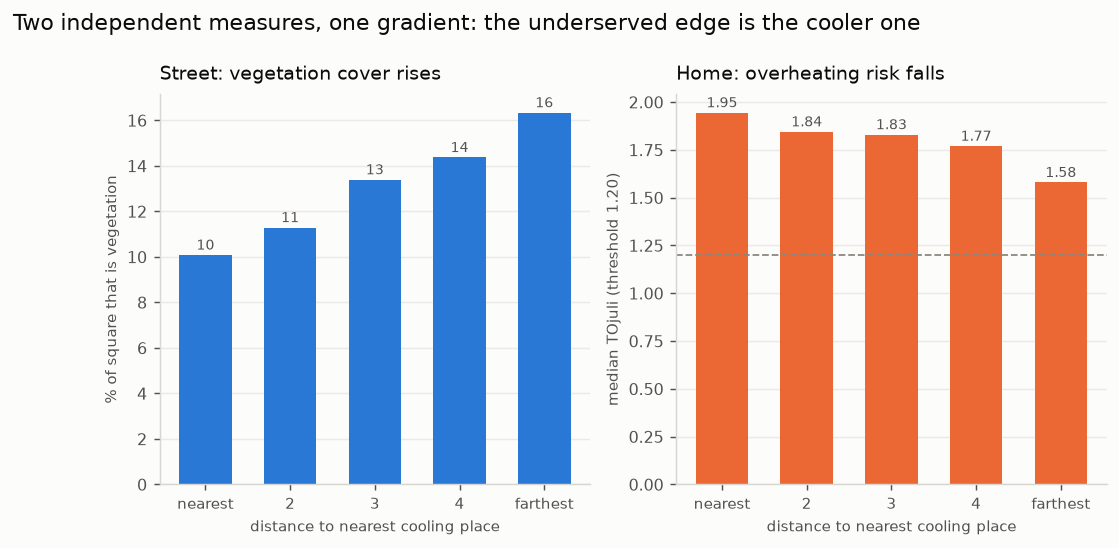

In [41]:
# Two exposure measures against the same x-axis. Small multiples rather than one chart with
# two y-scales - a dual axis would let the reader infer a relationship from line crossings
# that is an artefact of the scaling.
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.9))

qs = ["nearest", "2", "3", "4", "farthest"]
gb = ok.groupby(q, observed=True)["green_frac"].mean().reindex(qs) * 100
tj = ok.groupby(q, observed=True)["tojuli"].median().reindex(qs)

for ax, vals, title, ylab, colour in [
    (axes[0], gb, "Street: vegetation cover rises", "% of square that is vegetation", BLUE),
    (axes[1], tj, "Home: overheating risk falls", "median TOjuli (threshold 1.20)", ORANGE),
]:
    ax.bar(range(5), vals, 0.62, color=colour)
    for i, v in enumerate(vals):
        ax.annotate(f"{v:.2f}" if v < 10 else f"{v:.0f}", (i, v), xytext=(0, 3),
                    textcoords="offset points", ha="center", fontsize=8, color=INK_2)
    ax.set_xticks(range(5))
    ax.set_xticklabels(qs, fontsize=8.5)
    ax.set_title(title, fontsize=10.5, color=INK, loc="left", pad=8)
    ax.set_ylabel(ylab, fontsize=8.5)
    ax.set_xlabel("distance to nearest cooling place", fontsize=8.5)
    ax.grid(axis="y", color="#eceae4", linewidth=0.8)
    ax.set_axisbelow(True)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)

axes[1].axhline(1.2, color=INK_3, linewidth=1, linestyle="--")

fig.suptitle("Two independent measures, one gradient: the underserved edge is the cooler one",
             fontsize=12, color=INK, x=0.005, ha="left", y=1.04)
fig.savefig(FIGS / "exposure_two_measures.png")
plt.show()


### 12e. Do the two measures agree with each other?

Sections 11b and 12c each compare one measure against distance. Neither asks whether the two
agree *square by square* - and "two independent measures, one conclusion" is only worth saying
if they do. Agreeing about the distance gradient is a weaker claim than it looks: both could be
tracking density and nothing else, since a dense square is stony and its housing is older and
deeper. That would be one fact counted twice, not two views of the same heat.

So the correlation is run raw and again with the population rank partialled out. If it survives,
the exposure axis has convergent support from two unrelated sources - BGT ground survey and an
NTA 8800 dwelling calculation - which is the closest thing to validation available here. If it
collapses, the section 17 typology is sorting squares on one measure wearing two hats.


In [42]:
# Convergent validity: do the two exposure measures agree where they describe the same squares?
# Spearman rather than Pearson - greenblue_frac is bounded at 0 and 1 and TOjuli is right-skewed,
# so neither relationship has any reason to be linear. Expect a NEGATIVE sign: greener square,
# cooler housing.
#
# Both the pooled measure and green alone are tested. Water is not shade, and a square that is
# half canal is not half cool, so pooling may be diluting the signal rather than adding to it.
both = ok[["green_frac", "greenblue_frac", "tojuli", POP]].dropna()
r = both.rank()

# Partial out density by residualising both ranks on the population rank, then correlating what
# is left. If a raw figure is density showing up twice, this is where it disappears.
resid = lambda y: y - np.polyval(np.polyfit(r[POP], y, 1), r[POP])

for col, label in [("greenblue_frac", "green-blue pooled"), ("green_frac", "green only")]:
    par = np.corrcoef(resid(r[col]), resid(r["tojuli"]))[0, 1]
    print(f"{label:>18}: spearman vs TOjuli {r[col].corr(r['tojuli']):+.3f}"
          f"   density partialled out {par:+.3f}"
          f"   (vs population {r[col].corr(r[POP]):+.3f})")
print(f"\nn = {len(both):,} squares | TOjuli vs population {r['tojuli'].corr(r[POP]):+.3f}")

for col, label in [("greenblue_frac", "green-blue"), ("green_frac", "green only")]:
    q4 = pd.qcut(both[col], 4, labels=["stoniest", "2", "3", "greenest"], duplicates="drop")
    print(f"\nmedian TOjuli by {label} quartile:")
    print(both.groupby(q4, observed=True)["tojuli"].median().round(2).to_string())


 green-blue pooled: spearman vs TOjuli -0.096   density partialled out -0.054   (vs population -0.440)
        green only: spearman vs TOjuli -0.219   density partialled out -0.194   (vs population -0.362)

n = 5,065 squares | TOjuli vs population +0.108

median TOjuli by green-blue quartile:
greenblue_frac
stoniest    1.92
2           1.76
3           1.78
greenest    1.70

median TOjuli by green only quartile:
green_frac
stoniest    2.02
2           1.84
3           1.69
greenest    1.60


**Spearman -0.096 pooled, -0.222 for green alone.** The pooled measure barely moves with TOjuli:
partial out the population rank and -0.096 becomes -0.056. With n = 4,906 that carries a p-value
in the tenth decimal place attached to under 1% of variance - the textbook case of detectable and
meaningless. Dropping water from the proxy roughly doubles it, and the quartile gradient sharpens
from 1.93 -> 1.70 with the middle two tied to a strictly monotone 2.02 -> 1.60.

**Water was diluting the measure, not strengthening it.** A square that is half canal is not half
cool: open water has no evapotranspiration to speak of, releases stored heat overnight when the
risk is highest, and shades no facade. Section 11 kept the pooled column because it correlates
better with *distance* (0.208 against 0.159) - but that was optimising the wrong quantity. Cooling
places sit inland in the centre, so the water term partly encodes distance from the IJ and the
canal belt rather than heat.

**Even at -0.222 this is not validation.** Five percent of variance. The honest reading is that
ground cover and modelled indoor exceedance describe different mechanisms - TOjuli is driven by
glazing, orientation, insulation and ventilation, so a well-sealed new-build on a bare plaza reads
cool while a pre-war top-floor flat under a plane tree reads hot. Two axes, not two readings of
one quantity. Section 13b tests what that does to the typology.


### Limitations

- **41% of dwellings.** Only homes labelled from 2021 have TOjuli. Coverage is spatially even
  and the selection effect is 0.02 on the median, but 2,137 squares hold fewer than five
  labelled dwellings and are excluded - roughly 141,000 residents whose housing is unmeasured.
- **TOjuli is modelled, not measured.** It is an NTA 8800 calculation from building
  characteristics, not a thermometer. Its inputs are an assessor's inspection, with the
  variation that implies.
- **Actively cooled dwellings are held out, not scored.** 21,065 homes with mechanical cooling
  are absent from these medians. They are disproportionately new-build, so squares dominated
  by recent construction are measured on their uncooled minority.
- **Median hides the tail.** A square whose median is below the threshold can still contain
  many dwellings well above it - and it is individual homes that overheat, not medians.


## 13. Which underserved areas are actually vulnerable?

The goal here is understanding, not optimisation. Acquiring a cooling place is not the
binding constraint - agreements with libraries, community centres and shops are comparatively
cheap - so "maximum coverage from minimum sites" is the wrong objective. The useful question
is which underserved areas carry real need, and what kind of need.

Three axes are now available at 100 m: **access** (section 6), **exposure** (sections 11-12),
**vulnerability** (section 9). Each underserved zone gets characterised on all three, and
zones are classified by whether they exceed the *city* median on exposure and on elderly
share - a filter, never a weighted score.

> **Amended 28 Sep 2026 (decision 29).** The typology is descriptive, not a priority rule. Its heat
> axis covers only dwellings labelled since 2021, and its age axis runs *against* frailty and
> loneliness across these zones (section 18), so *hot + elderly* is one kind of need, not the most
> severe one. The dashboard compares neighbourhoods on all seven indicators side by side instead.


In [43]:
# gap predates sections 11-12, so bring the two need axes onto it.
gz = (gap.merge(cover[["crs28992res100m", "green_frac", "greenblue_frac"]], on="crs28992res100m", how="left")
        .merge(overheat, on="crs28992res100m", how="left"))
gz["eld"] = gz[ELDERLY].fillna(0)

zone_stats = gz.groupby("zone").apply(lambda g: pd.Series({
    "residents": g[POP].sum(),
    "elderly": g["eld"].sum(),
    "eld_share": g["eld"].sum() / g[POP].sum(),
    "tojuli": g["tojuli"].median(),
    "tojuli_cov": g["tojuli"].notna().mean(),   # how much of the zone is measured
    "greenblue": g["greenblue_frac"].mean(),
    "green": g["green_frac"].mean(),          # unpooled - water is not shade
    "mean_m": g["net_m"].mean(),
    "max_m": g["net_m"].max(),
}), include_groups=False).join(zones[["stadsdeel", "buurten", "geometry"]])

# Zones under 500 residents are the 141-strong noise tail from section 7.
zone_stats = gpd.GeoDataFrame(zone_stats[zone_stats["residents"] >= 500], crs=RD)
print(f"{len(zone_stats)} underserved zones with 500+ residents, "
      f"{zone_stats['residents'].sum():,.0f} residents, {zone_stats['elderly'].sum():,.0f} aged 65+")


40 underserved zones with 500+ residents, 267,795 residents, 38,690 aged 65+


### 13a. A typology, not a ranking

Thresholds are the **city-wide** medians, so a zone is "hot" or "elderly" relative to
Amsterdam as a whole rather than relative to other underserved zones. Comparing gaps only to
other gaps would guarantee half of them look fine.

Zones whose TOjuli is unmeasured, or measured on under half their area, are marked
**unknown** rather than quietly counted as cool - three of them are industrial areas with no
labelled housing at all.


In [44]:
city_tojuli = near["tojuli"].median()
city_eld = near[ELDERLY].fillna(0).sum() / near[POP].sum()
print(f"city median TOjuli {city_tojuli:.2f} | city elderly share {city_eld:.1%}")

measured = zone_stats["tojuli"].notna() & (zone_stats["tojuli_cov"] >= 0.5)
hot = zone_stats["tojuli"] >= city_tojuli
old = zone_stats["eld_share"] >= city_eld

zone_stats["type"] = np.select(
    [~measured, hot & old, hot & ~old, ~hot & old],
    ["unknown exposure", "hot + elderly", "hot only", "elderly only"],
    default="neither")

summary = (zone_stats.groupby("type")
           .agg(zones=("residents", "size"), residents=("residents", "sum"),
                elderly=("elderly", "sum"), mean_walk=("mean_m", "mean"))
           .sort_values("residents", ascending=False))
summary.round(0)


city median TOjuli 1.80 | city elderly share 13.6%


,zones,residents,elderly,mean_walk
type,,,,
elderly only,13,142240.0,24795.0,1902.0
hot only,10,43190.0,3245.0,1404.0
neither,6,41820.0,4585.0,1241.0
hot + elderly,6,35320.0,5915.0,1261.0
unknown exposure,5,5225.0,150.0,1341.0


### 13b. Does the typology depend on which exposure measure?

`hot` above is TOjuli alone. That was a free choice while the two exposure measures looked
interchangeable; section 12e showed they are not, so it has to be tested rather than assumed -
the rule from decision 15.

Raw agreement is the wrong statistic here. Both measures call most zones not-hot, so chance
agreement is high and a coin would look concordant. Cohen's kappa nets the marginals out.

The pooled green-blue fraction is also tested against **green alone**, because the zones most
likely to move are converted dock islands - and half of a KNSM-eiland square is open water,
which the pooled measure scores as cooling.


In [45]:
# Does "hot" survive being defined from the other exposure measure? Kappa rather than raw
# agreement: with both measures calling most zones not-hot, agreement alone is inflated by the
# marginals and a coin flip scores ~0.54.
def kappa(a, b):
    po = (a == b).mean()
    pe = a.mean() * b.mean() + (1 - a.mean()) * (1 - b.mean())
    return po, pe, (po - pe) / (1 - pe)

alts = [("green-blue pooled", zone_stats["greenblue"] <= near["greenblue_frac"].median()),
        ("green only",        zone_stats["green"]     <= near["green_frac"].median())]

for name, alt in alts:
    po, pe, k = kappa(hot, alt)
    print(f"{name:>18}: agreement {po:.3f}, chance {pe:.3f}, kappa {k:+.3f}"
          f"   ({alt.sum()} of {len(alt)} zones stonier than the city median)")

for name, alt in alts:
    t = np.select([~measured, alt & old, alt & ~old, ~alt & old],
                  ["unknown exposure", "hot + elderly", "hot only", "elderly only"],
                  default="neither")
    print(f"\n{name} vs the TOjuli typology:")
    print(pd.crosstab(zone_stats["type"], t, rownames=["TOjuli"], colnames=[name]))

# How much of each priority zone's "green" is actually water.
print("\nhot + elderly zones, pooled vs unpooled:")
print(zone_stats.loc[zone_stats["type"] == "hot + elderly", ["residents", "greenblue", "green"]]
      .assign(water=lambda d: d["greenblue"] - d["green"])
      .sort_values("residents", ascending=False).round(3).to_string())


 green-blue pooled: agreement 0.600, chance 0.541, kappa +0.128   (9 of 40 zones stonier than the city median)


        green only: agreement 0.625, chance 0.530, kappa +0.202   (12 of 40 zones stonier than the city median)

green-blue pooled vs the TOjuli typology:
green-blue pooled  elderly only  hot + elderly  hot only  neither  \
TOjuli                                                              
elderly only                 11              2         0        0   
hot + elderly                 4              2         0        0   
hot only                      0              0         3        7   
neither                       0              0         0        6   
unknown exposure              0              0         0        0   

green-blue pooled  unknown exposure  
TOjuli                               
elderly only                      0  
hot + elderly                     0  
hot only                          0  
neither                           0  
unknown exposure                  5  

green only vs the TOjuli typology:
green only        elderly only  hot + elderly  hot only  n

**The pooled measure agrees with TOjuli at exactly chance.** 23 of the 42 zones are classified
the same way - but given the marginals, 22.7 would agree by coin flip. Cohen's kappa is
**+0.015**. On green alone it is **+0.345**, and the number of *hot + elderly* zones surviving the
swap goes from **1 of 6** to **4 of 6**.

**The reason is the last table.** The zones that move are converted dock islands. KNSM-eiland /
Borneo scores 53.8% green-blue - of which **49.9 points is open water and 3.9 is vegetation**. The
Westelijke eilanden: 29.6% water against 1.5% green. Under the pooled proxy these are among the
greenest places in Amsterdam; measured by vegetation they are among the stoniest. They are also
precisely the zones section 17 singled out as the interesting result, and the pooled measure was
classifying them on their canals.

**What this settles:** `greenblue_frac` is the wrong variable for classifying zones. The water term
is not measuring cooling, and here it inverts the answer.

**What it does not settle:** which of `green_frac` or TOjuli should define "hot". A kappa of 0.345
is fair agreement, not interchangeability - two of the six priority zones still move. The
typology's "hot" is an *indoor* measure and section 13c should be read that way.

**Deliberately not done here:** section 11's headline gradient and the exposure figures still use
the pooled measure. Repointing them at `green_frac` changes published numbers rather than adding a
caveat, so it is recorded as an open item in decision 19 rather than slipped in.


### 13c. The hot + elderly zones

In [46]:
priority = zone_stats[zone_stats["type"] == "hot + elderly"].sort_values("residents", ascending=False)
print(f"{len(priority)} zones | {priority['residents'].sum():,.0f} residents | "
      f"{priority['elderly'].sum():,.0f} aged 65+")

zone_stats.drop(columns="geometry").to_csv(PROCESSED / "zone_priority.csv")
zone_stats.to_file(PROCESSED / "zone_priority.gpkg", driver="GPKG")

priority[["residents", "elderly", "eld_share", "tojuli", "green", "mean_m",
          "stadsdeel", "buurten"]].round(3)


6 zones | 35,320 residents | 5,915 aged 65+


,residents,elderly,eld_share,tojuli,green,mean_m,stadsdeel,buurten
zone,,,,,,,,
44,20435.0,2815.0,0.138,2.013,0.046,1227.818,West,"Cremerbuurt-West, Paramariboplein e.o., Borger..."
73,8540.0,1875.0,0.220,2.190,0.015,1236.587,Centrum,"Westelijke eilanden, Westerdokseiland, Haarlem..."
98,2490.0,575.0,0.231,2.065,0.048,1308.707,Oost,"KNSM-eiland, Sporenburg"
63,2135.0,345.0,0.162,1.920,0.076,1118.333,Zuid,"Cornelis Schuytbuurt, Vondelpark-Oost, Vondelp..."
81,1165.0,225.0,0.193,2.132,0.245,1086.467,Noord,Overhoeks
130,555.0,80.0,0.144,2.045,0.212,1585.360,Noord,"Schellingwoude-Oost, Schellingwoude-West"


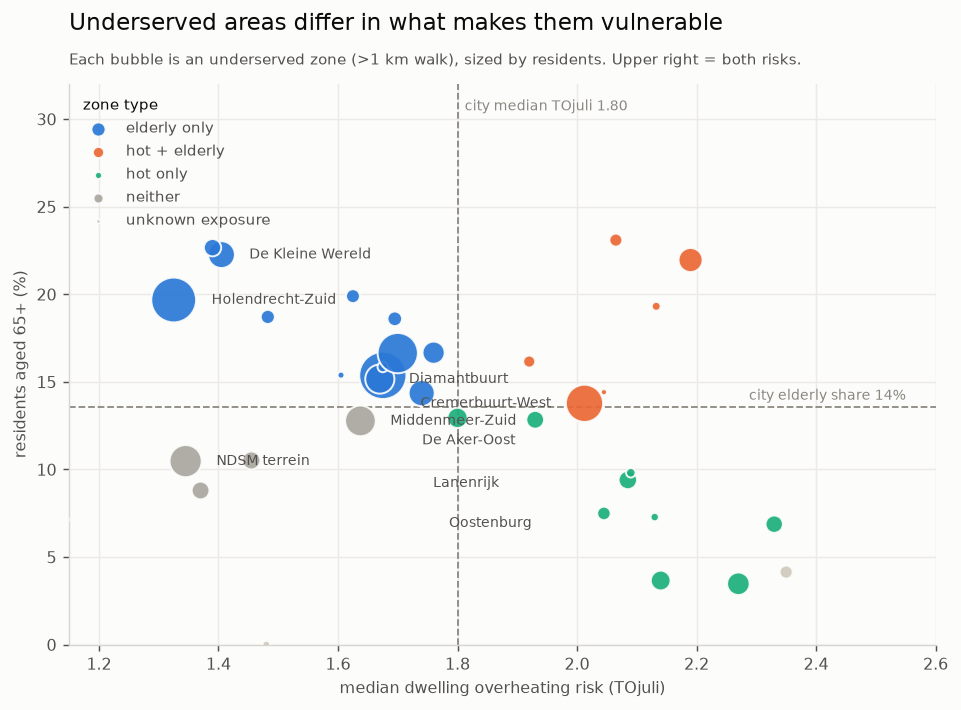

In [47]:
# The landscape of underserved zones on both need axes at once. A scatter rather than a
# ranked bar chart: the question is what kinds of need exist and how zones cluster, which a
# ranking flattens into a single order it cannot justify.
COLOURS = {"hot + elderly": ORANGE, "elderly only": BLUE, "hot only": AQUA,
           "neither": "#a9a79e", "unknown exposure": "#cfc9bb"}

fig, ax = plt.subplots(figsize=(8.6, 5.6))

ax.axvline(city_tojuli, color=INK_3, linewidth=1, linestyle="--", zorder=1)
ax.axhline(city_eld * 100, color=INK_3, linewidth=1, linestyle="--", zorder=1)
ax.annotate(f"city median TOjuli {city_tojuli:.2f}", (city_tojuli, 30.5), xytext=(4, 0),
            textcoords="offset points", fontsize=7.5, color=INK_3)
ax.annotate(f"city elderly share {city_eld:.0%}", (2.55, city_eld * 100), xytext=(0, 4),
            textcoords="offset points", fontsize=7.5, color=INK_3, ha="right")

plotted = zone_stats[zone_stats["tojuli"].notna()]
for t, grp in plotted.groupby("type"):
    ax.scatter(grp["tojuli"], grp["eld_share"] * 100,
               s=grp["residents"] / 48, c=COLOURS[t], label=t,
               edgecolor=SURFACE, linewidth=1.1, alpha=0.92, zorder=3)

# Label only the zones big enough to matter, and alternate above/below: neighbouring bubbles
# otherwise print their names on top of each other.
# Alternating a fixed offset is not enough: it disappears inside the biggest bubbles, which
# are exactly the zones worth naming. Offset by each marker's own radius instead, and place the
# label beside it, stepping down only when another label already holds that spot.
big = plotted[plotted["residents"] >= 9000].sort_values("tojuli")
placed = []
for r in big.itertuples():
    x, yv = r.tojuli, r.eld_share * 100
    rad = np.sqrt((r.residents / 48) / np.pi)
    side = -1 if x > 1.9 else 1
    dy = 0
    while any(abs(x - px) < 0.16 and abs(yv + dy / 8 - py) < 1.8 for px, py in placed):
        dy -= 12
    placed.append((x, yv + dy / 8))
    ax.annotate(r.buurten.split(",")[0][:24], (x, yv),
                xytext=(side * (rad + 7), dy), textcoords="offset points",
                ha="left" if side > 0 else "right", va="center",
                fontsize=7.5, color=INK_2, zorder=4)

ax.set_xlabel("median dwelling overheating risk (TOjuli)")
ax.set_ylabel("residents aged 65+ (%)")
ax.set_xlim(1.15, 2.6)
ax.set_ylim(0, 32)
ax.grid(color="#eceae4", linewidth=0.8)
ax.set_axisbelow(True)
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
ax.legend(frameon=False, fontsize=8.5, labelcolor=INK_2, loc="upper left", title="zone type",
          title_fontsize=8.5, alignment="left", markerscale=0.42)
ax.set_title("Underserved areas differ in what makes them vulnerable",
             fontsize=12.5, color=INK, loc="left", pad=30)
ax.text(0, 1.035, "Each bubble is an underserved zone (>1 km walk), sized by residents. "
        "Upper right = both risks.", transform=ax.transAxes, fontsize=8.5, color=INK_2)
fig.savefig(FIGS / "zone_typology.png")
plt.show()


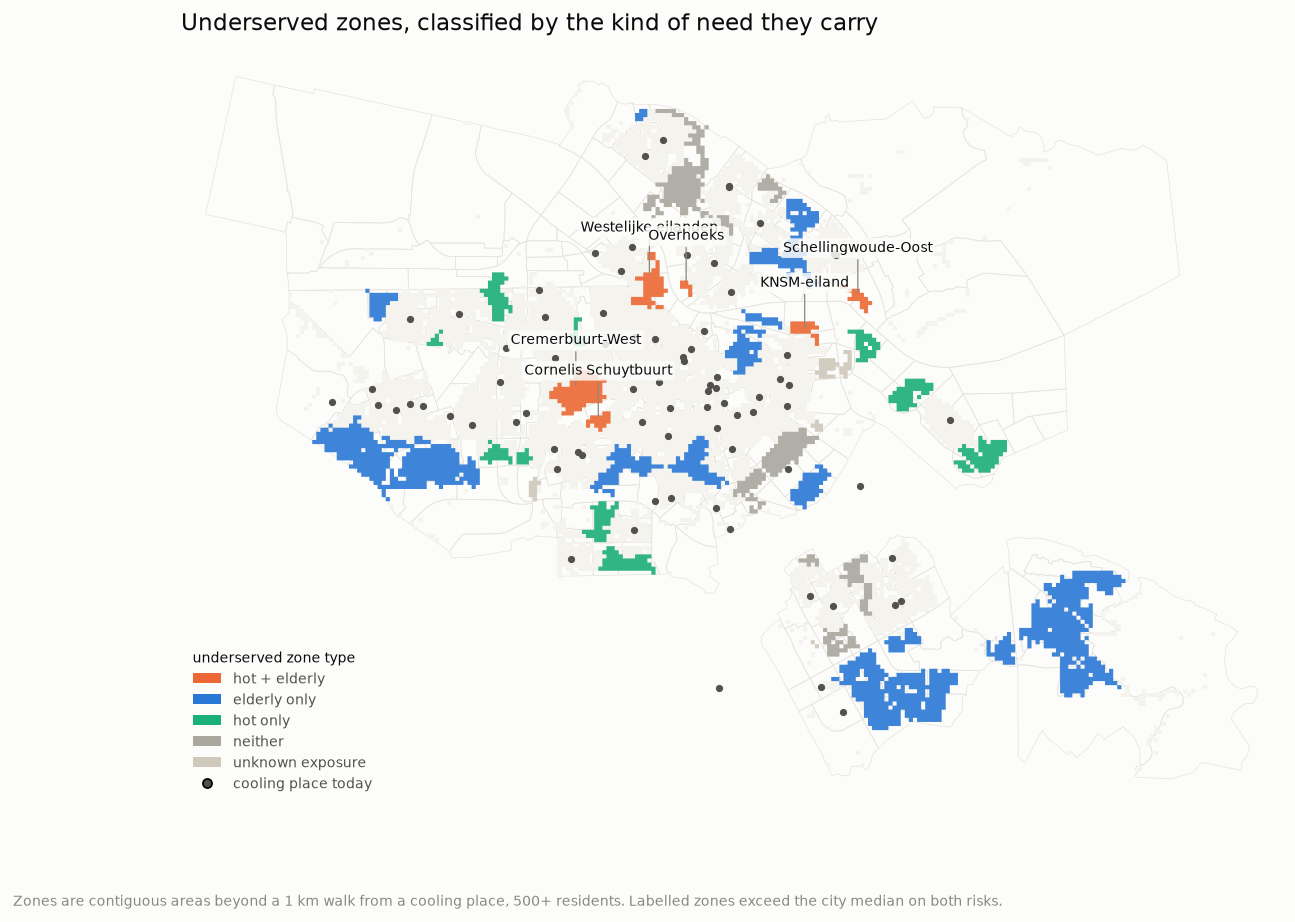

In [48]:
fig, ax = plt.subplots(figsize=(11, 11 * aspect))

b.boundary.plot(ax=ax, color="#e6e4de", linewidth=0.4, zorder=1)
squares.plot(ax=ax, color="#f5f3ee", zorder=2)          # city as a muted ground

for t, colour in COLOURS.items():
    sel = zone_stats[zone_stats["type"] == t]
    if len(sel):
        sel.plot(ax=ax, color=colour, edgecolor="none", alpha=0.9, zorder=3, label=t)

facilities.plot(ax=ax, color=INK_2, markersize=9, zorder=4)

# A leader line, because these polygons are small: a floating caption 12 pt above a
# two-square zone names nothing the reader can identify with confidence.
for r in priority.itertuples():
    p = r.geometry.representative_point()
    ax.annotate(r.buurten.split(",")[0], (p.x, p.y), xytext=(0, 26),
                textcoords="offset points", ha="center", fontsize=7.5, color=INK, zorder=5,
                arrowprops=dict(arrowstyle="-", color=INK_3, linewidth=0.7,
                                shrinkA=1, shrinkB=3),
                bbox=dict(boxstyle="round,pad=0.2", facecolor=SURFACE,
                          edgecolor="none", alpha=0.85))

handles = [plt.Rectangle((0, 0), 1, 1, facecolor=c) for c in COLOURS.values()] + [
    Line2D([], [], marker="o", linestyle="none", color="none", markerfacecolor=INK_2,
           markersize=5, label="cooling place today")]
ax.legend(handles, list(COLOURS) + ["cooling place today"], loc="lower left", frameon=False,
          fontsize=8, labelcolor=INK_2, title="underserved zone type", title_fontsize=8,
          alignment="left", borderaxespad=0.4, labelspacing=0.45)

ax.set_xlim(minx - pad, maxx + pad)
ax.set_ylim(miny - pad, maxy + pad)
ax.set_axis_off()
ax.set_aspect("equal")
ax.set_title("Underserved zones, classified by the kind of need they carry",
             fontsize=13, color=INK, loc="left", pad=12)
fig.text(0.01, 0.005, "Zones are contiguous areas beyond a 1 km walk from a cooling place, "
         "500+ residents. Labelled zones exceed the city median on both risks.",
         fontsize=7.5, color=INK_3)
fig.savefig(FIGS / "zone_typology_map.png")
plt.show()


## 14. Where would a new cooling place do the most good?

Section 13 classified zones with hard filters, which has a real flaw: a zone at 12.9% elderly
counts for nothing and one at 13.6% counts fully. That cliff has no justification behind it,
and it discards underserved areas simply for being young.

So this section weights instead of filtering - but **weights the people, not the criteria**:

```
demand = residents x age_factor x heat_factor
  age_factor  = 1 + (RR - 1) x elderly_share      RR = heat-mortality risk ratio for 65+
  heat_factor = TOjuli / city median, clipped to [0.5, 2.0], neutral 1.0 where unmeasured
```

`heat_factor` is measured, not chosen - a square's overheating relative to the city's. `RR` is
a genuine assumption, so it is run at 1x (no age weighting), 2x, 3x and 5x rather than picked
once. Squares with no TOjuli get 1.0, so unmeasured areas are neither rewarded nor excluded.

The output is a **continuous effect surface**: for every point in Amsterdam, the unserved
weighted demand a new cooling place there would bring within 1 km. No sites are chosen and
nothing is filtered out - low-elderly underserved areas still appear, just less brightly.


In [49]:
from shapely.geometry import Point

SURFACE_F = PROCESSED / "effect_surface.gpkg"
STEP = 200

near["eld_share"] = (near[ELDERLY].fillna(0) / near[POP]).clip(0, 1)
near["heat_f"] = (near["tojuli"] / city_tojuli).clip(0.5, 2.0).fillna(1.0)

if SURFACE_F.exists():
    cand = gpd.read_file(SURFACE_F)
else:
    city = b.union_all()
    xs = np.arange(minx, maxx, STEP)
    ys = np.arange(miny, maxy, STEP)
    cand = gpd.GeoDataFrame(geometry=[Point(x, y) for x in xs for y in ys], crs=RD)
    cand = cand[cand.within(city)].reset_index(drop=True)

    c_nodes, c_snap = ox.distance.nearest_nodes(
        G, X=cand.geometry.x, Y=cand.geometry.y, return_dist=True)
    cand["node"], cand["snap"] = c_nodes, c_snap
    # A point 400 m from the nearest footpath is not a plausible site.
    cand = cand[cand["snap"] <= 200].reset_index(drop=True)

    unserved = (near["net_m"] > RADIUS).to_numpy()
    # Named for what they are: `demand` and `reach` are live variables elsewhere in the
    # notebook, and rebinding them here breaks section 15 on any run that misses the cache.
    reach_rows = []
    for node, snap in zip(cand["node"], cand["snap"]):
        dd = nx.single_source_dijkstra_path_length(G, node, cutoff=RADIUS, weight="length")
        arr = np.fromiter((dd.get(k, np.inf) for k in dem_nodes), float, len(dem_nodes))
        reach_rows.append((arr + snap + dem_snap) <= RADIUS)
    R = np.array(reach_rows)

    for RR in (1, 2, 3, 5):
        weighted = (near[POP] * (1 + (RR - 1) * near["eld_share"]) * near["heat_f"]).to_numpy()
        cand[f"gain_rr{RR}"] = R[:, unserved] @ weighted[unserved]
    cand.drop(columns=["node"]).to_file(SURFACE_F, driver="GPKG")

print(f"{len(cand):,} candidate points on a {STEP} m grid")


4,774 candidate points on a 200 m grid


### 14a. The weighting turns out not to matter

Before reading anything off the surface, check how much the `RR` assumption drives it.


In [50]:
cols = [f"gain_rr{r}" for r in (1, 2, 3, 5)]
print(cand[cols].corr(method="spearman").round(3).to_string())


          gain_rr1  gain_rr2  gain_rr3  gain_rr5
gain_rr1     1.000     1.000     0.999     0.997
gain_rr2     1.000     1.000     1.000     0.999
gain_rr3     0.999     1.000     1.000     1.000
gain_rr5     0.997     0.999     1.000     1.000


**Spearman correlations of 0.997 to 1.000.** Ranking locations by unweighted population and
by population weighted 5x toward the elderly gives essentially the same answer.

That resolves the argument rather than winning it. The worry about arbitrary weights was
real, and so was the objection that hard filters discard young underserved areas - but
empirically **neither choice changes where a new cooling place would help most.** Geography
dominates: how many people currently sit beyond a kilometre, and how many of them one new
location can reach. Elderly share and overheating vary far less across the city than
population density does.

This is worth more than either position we argued. A weighted composite would have looked
sophisticated and been indistinguishable from counting residents; a strict filter would have
excluded areas for no gain in discrimination. Testing it took four lines.

The surface below uses RR = 3. Any of the four would produce the same map.


In [51]:
# The highest-scoring points cluster together - the top ten sit in one gap in West, which is
# one opportunity, not ten. Thin greedily: take the best point, then only accept further ones
# more than MIN_SEP away, so each row is a distinct area.
MIN_SEP = 1200

ranked = cand.sort_values("gain_rr3", ascending=False)
picked = []
for r in ranked.itertuples():
    if all(r.geometry.distance(p.geometry) >= MIN_SEP for p in picked):
        picked.append(r)
    if len(picked) == 8:
        break

hotspots = gpd.GeoDataFrame(
    [{"gain": p.gain_rr3, "geometry": p.geometry} for p in picked], crs=RD)
hotspots = gpd.sjoin(hotspots, b[["buurt", "stadsdeel", "geometry"]],
                     predicate="within", how="left").drop(columns="index_right")
hotspots.index = range(1, len(hotspots) + 1)

print("distinct high-effect areas (unserved weighted residents reached from each):")
print(hotspots[["gain", "buurt", "stadsdeel"]].round(0).to_string())


distinct high-effect areas (unserved weighted residents reached from each):
      gain                      buurt   stadsdeel
1  27783.0                 Lootsbuurt        West
2  16691.0        Herensingelkwartier       Weesp
3  15826.0               De Aker-Oost  Nieuw-West
4  15652.0               Reigersbos 1    Zuidoost
5  15318.0     Nieuw-Sloten-Noordoost  Nieuw-West
6  15202.0            IJselbuurt-Oost        Zuid
7  14450.0  Sportpark Middenmeer-Zuid        Oost
8  13799.0       Haarlemmerbuurt-West     Centrum


### 14b. The same surface, prepared for the dashboard

Eight areas is the right number to *name*. For the question "what does the second one buy once
the first one exists", the answer depends on overlap, so the dashboard needs each candidate's
catchment rather than its score. Twelve are exported; the ordering is computed live.

In [52]:
# ---------------------------------------------------------------------------------------------
# Candidate venues for the dashboard's planner.
#
# Decision 10 rejected a greedy search over OSM buildings for naming premises. Decision 27
# revises that: the objection was to a MODEL picking a winner, not to showing a person what
# already stands in a gap. The shortlist below is ordered by geometric reach and chosen from by
# a human, and the notebook still names no site.
#
# The venue types mirror the scheme as it actually is, not as one might assume it to be. The 80
# existing koelteplekken include supermarkets (AH Osdorpplein XL, Jumbo Ouderkerk), hotels
# (Hotel Casa, Leonardo Royal), cafes and restaurants (Cafe Groenhoven, Die Port van Cleve),
# care homes (Amsta, Amstelring), a university building (HvA Wibauthuis), churches, buurthuizen,
# libraries and theatres. Excluding shops from the candidates while the scheme already runs on
# them would be inconsistent.
SLIDER_MAX = 1500
SAME_PLACE = 50       # one name and kind within this distance is one venue mapped twice

VENUE_TAGS = {
    "amenity": ["library", "community_centre", "place_of_worship", "social_facility",
                "arts_centre", "theatre", "townhall", "cafe", "restaurant",
                "college", "university", "nursing_home"],
    "leisure": ["sports_centre", "sports_hall"],
    "tourism": ["museum", "gallery", "hotel"],
    "shop":    ["supermarket", "mall", "department_store"],
}
KIND = {"library":"library", "community_centre":"community centre",
        "place_of_worship":"place of worship", "social_facility":"social facility",
        "arts_centre":"arts centre", "theatre":"theatre", "townhall":"town hall",
        "cafe":"cafe", "restaurant":"restaurant", "college":"college", "university":"university",
        "nursing_home":"care home", "sports_centre":"sports hall", "sports_hall":"sports hall",
        "museum":"museum", "gallery":"gallery", "hotel":"hotel",
        "supermarket":"supermarket", "mall":"shopping centre", "department_store":"department store"}

VENUES_F = PROCESSED / "candidate_venues_raw.gpkg"   # every named feature, before de-duplication
if VENUES_F.exists():
    civic = gpd.read_file(VENUES_F)
    print(f"loaded {VENUES_F} - delete it to re-query OSM")
else:
    raw = ox.features_from_polygon(b.to_crs(WGS84).union_all(), VENUE_TAGS).to_crs(RD)
    raw["geometry"] = raw.geometry.representative_point()      # polygons and points alike
    rows = []
    for _, r in raw.iterrows():
        kind = next((KIND[r[c]] for c in ("amenity", "leisure", "tourism", "shop")
                     if c in r and isinstance(r.get(c), str) and r[c] in KIND), None)
        name = r.get("name")
        if kind is None or not isinstance(name, str) or not name.strip():
            continue                                            # an unnamed point is unusable
        rows.append({"name": name.strip(), "kind": kind, "geometry": r.geometry})
    civic = gpd.GeoDataFrame(rows, crs=RD)
    civic.to_file(VENUES_F, driver="GPKG")

# De-duplicate by place, not by name. OSM often carries one shop twice - a node and its building
# outline - so the same name and kind within SAME_PLACE metres is one venue. The rule used to be
# name and kind city-wide, which left Amsterdam with exactly one Albert Heijn, one Jumbo, one Lidl
# and one Dirk: every other branch of every chain was silently dropped.
_keep = []
for _, grp in civic.groupby(["name", "kind"], sort=False):
    kept = []
    for ix, geom in zip(grp.index, grp.geometry):
        if all(geom.distance(civic.geometry[k]) >= SAME_PLACE for k in kept):
            kept.append(ix)
    _keep += kept
civic = civic.loc[sorted(_keep)].reset_index(drop=True)
print(f"{len(civic):,} venues after de-duplicating within {SAME_PLACE} m")

# A venue within 40 m of an existing koelteplek is almost certainly that same building.
civic = civic[civic.distance(facilities.geometry.union_all()) > 40].reset_index(drop=True)

# Candidates are searched CITY-WIDE, not only inside the underserved zones. Confining them to
# the zones made the zones the navigation, and the zones are a geometric artefact: contiguous
# blobs beyond a 1,000 m walk holding 500+ residents. A venue two streets outside a blob can
# serve more unmet need than one inside it, and the earlier search could never see it.
# Zone membership is kept as a label, not as a filter.
civic = (gpd.sjoin(civic, zone_stats[["geometry"]], predicate="within", how="left")
           .rename(columns={"index_right": "zone"}))
civic["zone"] = civic["zone"].fillna(-1).astype(int)
civic = civic[~civic.index.duplicated(keep="first")].reset_index(drop=True)
print(f"{len(civic):,} named venues city-wide; {(civic['zone'] >= 0).sum():,} inside an underserved zone")
print(civic["kind"].value_counts().to_string())

loaded data/processed/candidate_venues_raw.gpkg - delete it to re-query OSM
4,413 venues after de-duplicating within 50 m
4,322 named venues city-wide; 538 inside an underserved zone
kind
restaurant          1985
cafe                 702
hotel                405
supermarket          250
place of worship     179
sports hall          164
community centre     137
museum                88
theatre               80
gallery               78
social facility       57
arts centre           55
department store      30
college               30
library               27
university            26
shopping centre       13
town hall             10
care home              6


In [53]:
# Catchment per venue. A few thousand single-source Dijkstras, so it caches: the walking graph
# and the venue set are both fixed inputs.
REACH_F = PROCESSED / "venue_reach.npz"
if REACH_F.exists():
    _z = np.load(REACH_F, allow_pickle=True)
    reach_rows = [(_z[f"i{k}"], _z[f"d{k}"]) for k in range(int(_z["n"]))]
    print(f"loaded {REACH_F} - delete it to recompute")
else:
    _vnode, _vsnap = ox.distance.nearest_nodes(
        G, X=civic.geometry.x, Y=civic.geometry.y, return_dist=True)
    reach_rows = []
    for node, snap in zip(_vnode, _vsnap):
        dd = nx.single_source_dijkstra_path_length(G, node, cutoff=SLIDER_MAX, weight="length")
        arr = np.fromiter((dd.get(k, np.inf) for k in dem_nodes), float, len(dem_nodes)) + snap + dem_snap
        hit = np.nonzero(arr <= SLIDER_MAX)[0]
        reach_rows.append((hit.astype(np.int32), arr[hit].astype(np.float32)))
    np.savez_compressed(REACH_F, n=len(reach_rows),
                        **{f"i{k}": h for k, (h, _) in enumerate(reach_rows)},
                        **{f"d{k}": d for k, (_, d) in enumerate(reach_rows)})
    print(f"wrote {REACH_F}")

_unserved = (~near["net_m"].le(RADIUS)).to_numpy()
_pop = near[POP].to_numpy()

# Which zone each square belongs to, in `near` order, so a candidate can be credited to the
# zones it actually SERVES rather than the one it happens to stand in.
_zone_of = (gz.set_index("crs28992res100m")["zone"]
              .reindex(near["crs28992res100m"]).fillna(-1).astype(int).to_numpy())
_zone_of = np.where(np.isin(_zone_of, zone_stats.index.to_numpy()), _zone_of, -1)

serves_zones, city_reach = [], []
for h, d in reach_rows:
    inside = h[d <= RADIUS]
    unmet = inside[_unserved[inside]]
    city_reach.append(_pop[unmet].sum())
    zs, tot = _zone_of[unmet], {}
    for z, p in zip(zs, _pop[unmet]):
        if z >= 0:
            tot[int(z)] = tot.get(int(z), 0) + int(p)
    serves_zones.append(tot)

civic["reach"] = city_reach
civic["idx"] = range(len(civic))

# Value is threshold-neutral. Scoring on `reach` alone counted only residents beyond RADIUS, so
# a venue whose catchment sits in the 500-1,000 m band - uncovered at the dashboard's default
# walk - scored zero. This is the average the dashboard itself uses: newly reached against walking
# distance, 300 to 1,500 m, trapezoidal because the thresholds are unevenly spaced.
ROBUST_T = [300, 500, 750, 1000, 1500]
_net = near["net_m"].to_numpy()
_none = {t: ~(_net <= t) for t in ROBUST_T}               # NaN compares False: no place at all

def _avg(per):
    return sum((per[a] + per[b]) / 2 * (b - a)
               for a, b in zip(ROBUST_T, ROBUST_T[1:])) / (ROBUST_T[-1] - ROBUST_T[0])

civic["new_avg"] = [_avg({t: _pop[h[(d <= t) & _none[t][h]]].sum() for t in ROBUST_T})
                    for h, d in reach_rows]

civic = gpd.sjoin(civic, b[["stadsdeel", "geometry"]], predicate="within", how="left") \
          .drop(columns="index_right")
civic = civic[~civic.index.duplicated(keep="first")]
# reach_rows and serves_zones are positional, so the join must not have reordered anything.
assert (civic.index.to_numpy() == np.arange(len(civic))).all(), "sjoin reordered the venues"
civic["idx"] = range(len(civic))

# No shortlist. Most of these venues will be unsuitable, or will say no, so the useful output is
# every venue that would do anything at all - newly reach someone at some walk up to SLIDER_MAX -
# ranked, and a person works down it. Quotas, spacing and per-kind caps used to prune this to a few
# hundred; neighbours with near-identical catchments are exactly the fallback when one refuses.
# Section 15a adds the venues whose only value is a second option.
chosen = list(civic.loc[civic["new_avg"] > 0, "idx"])

def assemble(chosen):
    """The exported candidates. Section 15a extends `chosen` and calls this again."""
    areas = civic.set_index("idx").loc[chosen].reset_index(drop=True)
    reach_ = [reach_rows[i] for i in chosen]
    zones_ = [serves_zones[i] for i in chosen]
    areas = gpd.sjoin(areas.drop(columns=["stadsdeel"]), b[["buurt", "stadsdeel", "geometry"]],
                      predicate="within", how="left").drop(columns="index_right")
    areas = areas[~areas.index.duplicated(keep="first")]
    # The export zips these rows against reach_ by position.
    assert (areas.index.to_numpy() == np.arange(len(chosen))).all(), "sjoin reordered candidates"
    _covered = {z for t in zones_ for z in t}
    print(f"{len(areas)} candidates")
    print(f"  zones with at least one suggestion: {len(_covered & set(zone_stats.index))} of {len(zone_stats)}")
    print(f"  catchments: {sum(len(h) for h, _ in reach_):,} square-venue pairs")
    print(f"  outside every zone themselves: {(areas['zone'] < 0).sum()}")
    return areas, reach_, zones_

cand_areas, cand_reach, cand_zones = assemble(chosen)

loaded data/processed/venue_reach.npz - delete it to recompute
4282 candidates
  zones with at least one suggestion: 40 of 40
  catchments: 1,302,457 square-venue pairs
  outside every zone themselves: 3744


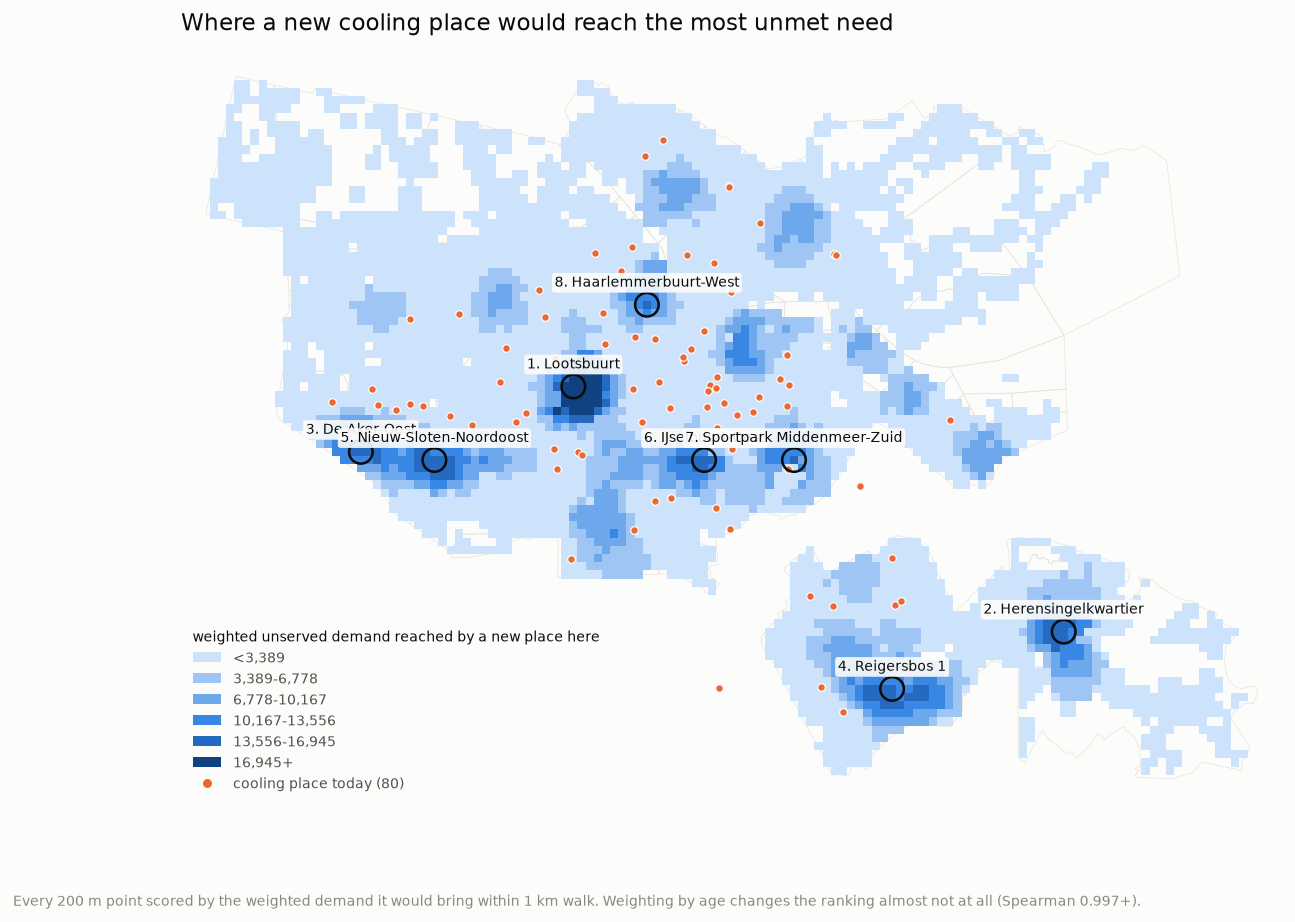

In [54]:
# Each candidate point stands for its 200 m cell, so draw them as squares: a scatter of dots
# would leave gaps that read as 'no data' rather than 'no effect'.
cells = cand.copy()
cells["geometry"] = cells.geometry.buffer(STEP / 2, cap_style=3)

vmax = cells["gain_rr3"].quantile(0.995)      # a few extreme points would flatten the ramp
bounds = [0, vmax * 0.2, vmax * 0.4, vmax * 0.6, vmax * 0.8, vmax, vmax * 10]
labels = [f"<{bounds[1]:,.0f}", f"{bounds[1]:,.0f}-{bounds[2]:,.0f}",
          f"{bounds[2]:,.0f}-{bounds[3]:,.0f}", f"{bounds[3]:,.0f}-{bounds[4]:,.0f}",
          f"{bounds[4]:,.0f}-{bounds[5]:,.0f}", f"{bounds[5]:,.0f}+"]

fig, ax = plt.subplots(figsize=(11, 11 * aspect))
b.boundary.plot(ax=ax, color="#e6e4de", linewidth=0.4, zorder=1)
cells.plot(ax=ax, column="gain_rr3", cmap=ListedColormap(RAMP),
           norm=BoundaryNorm(bounds, len(RAMP)), zorder=2)
facilities.plot(ax=ax, color=ORANGE, markersize=18, edgecolor=SURFACE, linewidth=0.7, zorder=3)
hotspots.plot(ax=ax, color="none", edgecolor=INK, linewidth=1.4, markersize=170, zorder=4)

# One label per distinct area, numbered to match the table above.
for rank, r in hotspots.iterrows():
    ax.annotate(f"{rank}. {r.buurt}", (r.geometry.x, r.geometry.y), xytext=(0, 10),
                textcoords="offset points", ha="center", fontsize=7.5, color=INK, zorder=5,
                bbox=dict(boxstyle="round,pad=0.2", facecolor=SURFACE, edgecolor="none",
                          alpha=0.9))

handles = [plt.Rectangle((0, 0), 1, 1, facecolor=c) for c in RAMP] + [
    Line2D([], [], marker="o", linestyle="none", color="none", markerfacecolor=ORANGE,
           markeredgecolor=SURFACE, markersize=6, label=f"cooling place today ({len(facilities)})")]
ax.legend(handles, labels + [handles[-1].get_label()], loc="lower left", frameon=False,
          fontsize=8, labelcolor=INK_2, title="weighted unserved demand reached by a new place here",
          title_fontsize=8, alignment="left", borderaxespad=0.4, labelspacing=0.45)

ax.set_xlim(minx - pad, maxx + pad)
ax.set_ylim(miny - pad, maxy + pad)
ax.set_axis_off()
ax.set_aspect("equal")
ax.set_title("Where a new cooling place would reach the most unmet need",
             fontsize=13, color=INK, loc="left", pad=12)
fig.text(0.01, 0.005, "Every 200 m point scored by the weighted demand it would bring within "
         "1 km walk. Weighting by age changes the ranking almost not at all (Spearman 0.997+).",
         fontsize=7.5, color=INK_3)
fig.savefig(FIGS / "effect_surface.png")
plt.show()


---

## 15. Supply: who serves whom, and what breaks if one closes

Every figure so far has been about **demand** - where people are and how far they must walk. It
treats the 80 cooling places as a fixed backdrop. This section turns around and asks what that
backdrop is actually made of: how many residents each venue carries, and how many of them have no
second option.

The distinction matters because the two questions have different answers. A venue can serve
thousands and be entirely replaceable, because three others sit within the same 500 m. Another can
serve a few hundred who have **nowhere else to walk**. Only the second is a single point of
failure, and nothing in sections 1-14 can see it.

**State the failure first, because it decides the unit.** The modelled failure is *a venue leaving
the scheme* - an organisation stops taking part, loses funding, or changes what it offers. It is
not a building being demolished. Cooling places here are voluntary participants in a programme
that went live this summer, so participation is the volatile thing. That makes the unit of
criticality the **organisation**: two organisations sharing a building are two independent chances
of survival. Building-level figures are reported alongside as the upper bound, where a whole site
is lost at once.

**Out of scope, deliberately: capacity.** There is no floor area, no occupancy limit, no headcount
in the source. "Where demand exceeds what a place can hold" cannot be answered here and should not
be estimated - it would need a proxy built from nothing. The open-questions list is corrected
accordingly.


### 15a. How many residents have a second option?


In [55]:
# Distances from every venue, not just the nearest. The cap has to sit ABOVE whatever
# threshold will be asked of the result, because each square's own snap distance is added
# afterwards. The published figures all use THRESHOLD, but the dashboard lets a reader move
# the threshold to SLIDER_MAX, and a count of "places within X" can only answer up to the cap
# this pass was computed with - so the cap is set by the largest question, not the headline one.
LIMIT = SLIDER_MAX + 200      # SLIDER_MAX is set in section 14b
D_all = sp_dijkstra(A, directed=False, indices=src_idx, limit=LIMIT)

reach = np.full((n_ven, len(dem_pos)), np.inf)
for i, v in enumerate(ven_of):                       # members of one venue: keep the nearer
    reach[v] = np.minimum(reach[v], D_all[i][dem_pos])
# `near` carries a fresh RangeIndex from the merges in sections 11-12, while dem_nodes and
# dem_snap are in `demand` order. The two are row-for-row identical - every step between them
# preserved order - but their INDEX LABELS are not, so align positionally and prove it first.
assert (near["crs28992res100m"].to_numpy() == demand["crs28992res100m"].to_numpy()).all(), \
    "near and demand are no longer row-aligned"
reach = pd.DataFrame(reach.T + np.asarray(dem_snap)[:, None],
                     index=near.index, columns=ven_name.values)

within = reach.le(THRESHOLD)
near["n_within"] = within.sum(axis=1).astype(int)

# "At least one venue within 500 m" and "the nearest venue is within 500 m" are the same
# arithmetic, so a mismatch here is an indexing slip, not a modelling choice.
assert ((near["n_within"] > 0) == near["served"]).all(), "reach matrix disagrees with net_m"

# The same reach, counted per ORGANISATION rather than per building. Which of the two is
# right depends entirely on the failure being modelled, and the failure that matters here is a
# venue leaving the scheme, not a building being demolished - see decision 20. Both are
# reported, because the pair is the sensitivity.
reach_org = pd.DataFrame(D_all[:, dem_pos].T + np.asarray(dem_snap)[:, None],
                         index=near.index, columns=facilities["name"].to_numpy())
within_org = reach_org.le(THRESHOLD)
near["n_org_within"] = within_org.sum(axis=1).astype(int)
assert ((near["n_org_within"] > 0) == near["served"]).all(), "org reach disagrees with net_m"
assert (near["n_org_within"] >= near["n_within"]).all(), "organisations cannot be fewer than venues"

# Each square's nearest few organisations, sorted. Four is enough to answer "one, two, three,
# four or more" at any threshold up to SLIDER_MAX, and it ships four arrays instead of a
# 7,043 x 80 matrix. Everything beyond the cap stays NaN rather than becoming a large number.
ORG_K = 4
_sorted = np.sort(reach_org.to_numpy(), axis=1)[:, :ORG_K]
for k in range(ORG_K):
    near[f"org_d{k + 1}"] = np.where(np.isfinite(_sorted[:, k]), _sorted[:, k], np.nan)

# The first of those must BE net_m: same graph, same snap distances, same minimum. If this
# fails the sort is reading a different matrix than the one net_m came from.
_d1, _net = near["org_d1"].to_numpy(), near["net_m"].to_numpy()
_both = np.isfinite(_d1) & np.isfinite(_net)
assert np.allclose(_d1[_both], _net[_both], atol=0.51), "org_d1 disagrees with net_m"
print(f"nearest-four organisation distances computed to {SLIDER_MAX} m; "
      f"{near['org_d2'].notna().sum():,} squares have a second option inside the cap")

sole = near["served"] & (near["n_org_within"] == 1)      # the headline: one organisation
sole_bldg = near["served"] & (near["n_within"] == 1)     # the bound: one building
served_pop = near.loc[near["served"], POP].sum()

print(f"residents within {THRESHOLD} m of a cooling place:      {served_pop:>9,.0f}")
print(f"  ...reaching exactly one ORGANISATION:          {near.loc[sole, POP].sum():>9,.0f}"
      f"  ({near.loc[sole, POP].sum() / served_pop:.0%} of them)")
print(f"  ...reaching exactly one BUILDING:              {near.loc[sole_bldg, POP].sum():>9,.0f}"
      f"  ({near.loc[sole_bldg, POP].sum() / served_pop:.0%})")
print(f"  ...reaching three or more organisations:       "
      f"{near.loc[near['n_org_within'] >= 3, POP].sum():>9,.0f}")


nearest-four organisation distances computed to 1500 m; 5,569 squares have a second option inside the cap
residents within 500 m of a cooling place:        254,020
  ...reaching exactly one ORGANISATION:            207,125  (82% of them)
  ...reaching exactly one BUILDING:                212,140  (84%)
  ...reaching three or more organisations:          11,565


In [56]:
# Section 14b exported every venue that newly reaches anyone. The second job a new place does -
# a fallback for residents with exactly one option - needs the organisation distances just
# computed, which is why venues whose only value is that second option are added here.
_d2 = near["org_d2"].to_numpy()
_one = {t: (_net <= t) & ~(_d2 <= t) for t in ROBUST_T}   # exactly one organisation within t
civic["second_avg"] = [_avg({t: _pop[h[(d <= t) & _one[t][h]]].sum() for t in ROBUST_T})
                       for h, d in reach_rows]

_before = len(chosen)
chosen = list(dict.fromkeys(chosen + list(civic.loc[civic["second_avg"] > 0, "idx"])))
print(f"{len(chosen) - _before} venues added whose only value is a second option")
cand_areas, cand_reach, cand_zones = assemble(chosen)

35 venues added whose only value is a second option
4317 candidates
  zones with at least one suggestion: 40 of 40
  catchments: 1,311,260 square-venue pairs
  outside every zone themselves: 3779


### 15b. Load and criticality per venue


In [57]:
# Two quantities per row, and they are deliberately counted in DIFFERENT units.
#
#   serves            - per BUILDING. Not a failure model: two records at one coordinate are
#                       exactly tied, so the network argmin hands one of them the whole
#                       catchment and the other zero. Clustering is the de-duplication guard
#                       decision 6 asked for, nothing more.
#   sole_provider_for - per ORGANISATION. The modelled failure is one venue leaving the
#                       scheme, and a co-located neighbour survives that. Summed back to the
#                       building so both columns can sit in one table; for the 76 sites with a
#                       single occupant the two units are identical by construction.
#   if_building_gone  - per BUILDING: the upper bound, where a whole site is lost at once.
load = (near[near["served"]].groupby("venue_name")[POP].sum()
        .reindex(ven_name.values, fill_value=0))
crit_org = within_org.loc[sole].mul(near.loc[sole, POP], axis=0).sum()
critical = (crit_org.groupby(ven_of).sum().reindex(range(n_ven)).fillna(0)
            .set_axis(ven_name.values))
crit_bldg = (within.loc[sole_bldg].mul(near.loc[sole_bldg, POP], axis=0).sum()
             .reindex(ven_name.values).fillna(0))

# Opening hours enter here as an annotation only - see the note below on decision 7.
open_sun = ~facilities["heat_sun"].fillna("").str.strip().str.lower().isin(["gesloten", ""])
ven_sun = pd.Series(open_sun.to_numpy()).groupby(ven_of).any()
ven_sun.index = ven_name.values

supply = pd.DataFrame({"serves": load, "sole_provider_for": critical,
                       "if_building_gone": crit_bldg, "open_sunday": ven_sun})
supply["backed_up"] = supply["serves"] - supply["sole_provider_for"]
supply.index.name = "venue"
supply.to_csv(PROCESSED / "venue_supply.csv")

print(f"{(supply['serves'] == 0).sum()} of {n_ven} venues are the nearest option for nobody "
      f"within {THRESHOLD} m")
print(f"median residents served per venue: {supply['serves'].median():,.0f}")
print(f"the busiest 10 venues carry {supply['serves'].nlargest(10).sum() / served_pop:.0%} "
      f"of all served residents")
print(f"{(~supply['open_sunday']).sum()} of {n_ven} venues are closed on Sunday")
print(f"{int((supply['sole_provider_for'] == 0).sum())} of {n_ven} sites are critical for nobody; "
      f"{int((supply['if_building_gone'] > supply['sole_provider_for']).sum())} differ between the "
      f"two units\n")

supply.sort_values("sole_provider_for", ascending=False).head(12).round(0)


6 of 78 venues are the nearest option for nobody within 500 m
median residents served per venue: 3,260
the busiest 10 venues carry 26% of all served residents
45 of 78 venues are closed on Sunday
9 of 78 sites are critical for nobody; 2 differ between the two units



,serves,sole_provider_for,if_building_gone,open_sunday,backed_up
venue,,,,,
OBA Bos en Lommer,8405.0,8405.0,8405.0,False,0.0
De Oranjekerk,7385.0,7385.0,7385.0,True,0.0
Stichting Midwest,7270.0,7270.0,7270.0,False,0.0
Avani Museum Quarter,6800.0,6800.0,6800.0,True,0.0
OBA Postjesweg,6040.0,6040.0,6040.0,False,0.0
OBA De Staatsliedenbuurt,5910.0,5910.0,5910.0,False,0.0
OBA Ijburg,5800.0,5800.0,5800.0,False,0.0
Westerkerk,5940.0,5660.0,5660.0,False,280.0
Restaurant Elixer,6035.0,5610.0,5610.0,True,425.0


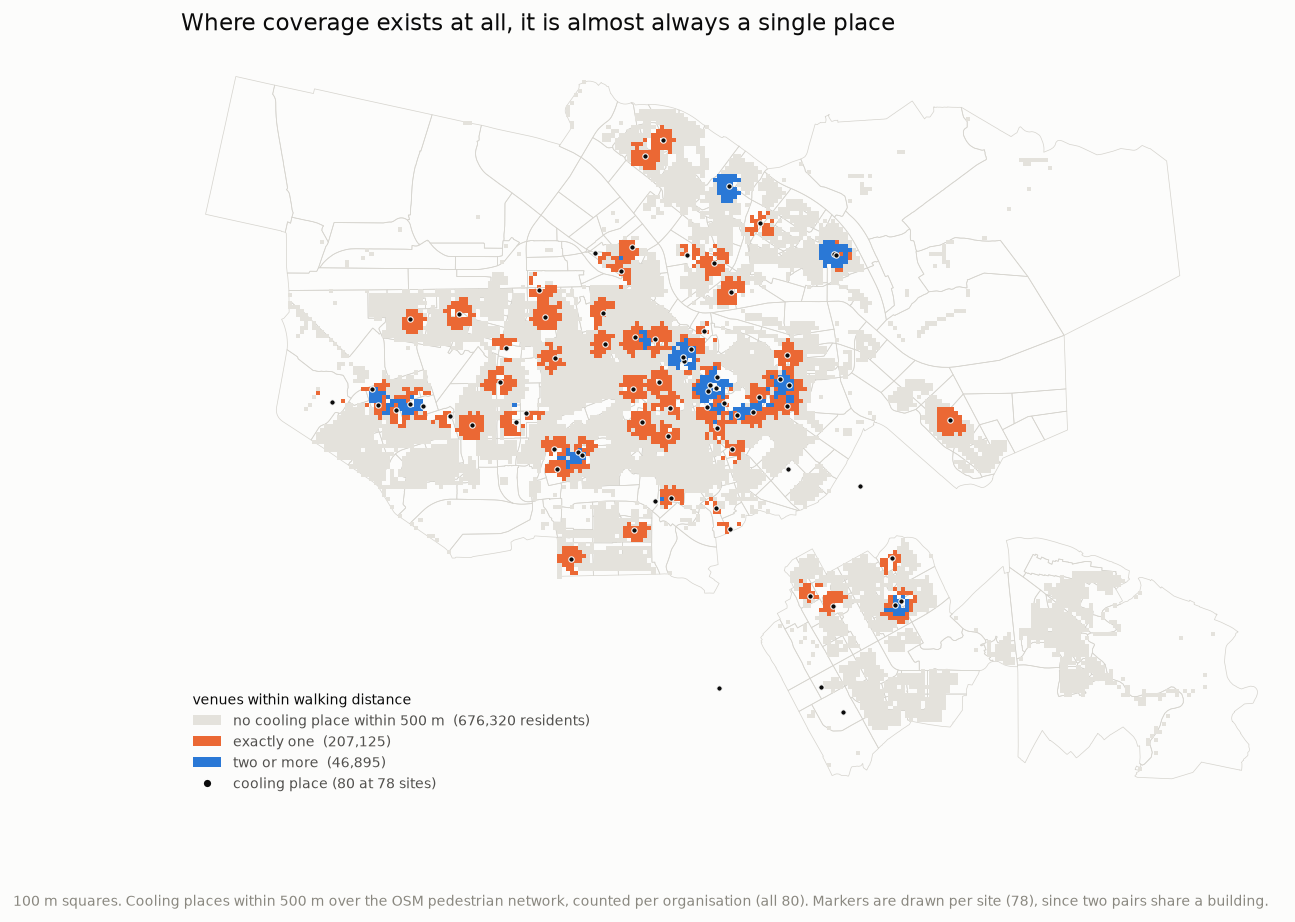

In [58]:
# Redundancy is a three-state fact per square, so three flat classes rather than a ramp - a
# sequential scale would imply "2 venues" is twice as good as "1", which is not the claim.
near["redundancy"] = np.where(~near["served"], 0, np.where(near["n_org_within"] == 1, 1, 2))
sq = grid.merge(near[["crs28992res100m", "redundancy"]], on="crs28992res100m", how="inner")

GREY = "#e4e2dc"
CLASSES = [GREY, ORANGE, BLUE]

minx, miny, maxx, maxy = b.total_bounds
pad = 600
aspect = ((maxy - miny) + 2 * pad) / ((maxx - minx) + 2 * pad)
fig, ax = plt.subplots(figsize=(11, 11 * aspect))

b.boundary.plot(ax=ax, color="#d6d4ce", linewidth=0.4, zorder=1)
sq.plot(ax=ax, column="redundancy", cmap=ListedColormap(CLASSES),
        norm=BoundaryNorm([-0.5, 0.5, 1.5, 2.5], 3), zorder=2)

# One marker per venue, not per record - the merged pairs would otherwise draw twice.
venue_pts = facilities.iloc[pd.Series(range(len(facilities))).groupby(ven_of).first().to_numpy()]
venue_pts.plot(ax=ax, color=INK, markersize=9, edgecolor=SURFACE, linewidth=0.6, zorder=3)

pops = [near.loc[near["redundancy"] == k, POP].sum() for k in (0, 1, 2)]
labels = [f"no cooling place within {THRESHOLD} m  ({pops[0]:,.0f} residents)",
          f"exactly one  ({pops[1]:,.0f})",
          f"two or more  ({pops[2]:,.0f})"]
handles = [plt.Rectangle((0, 0), 1, 1, facecolor=col) for col in CLASSES] + [
    Line2D([], [], marker="o", linestyle="none", color="none", markerfacecolor=INK,
           markeredgecolor=SURFACE, markersize=5,
           label=f"cooling place ({len(facilities)} at {n_ven} sites)")]
ax.legend(handles, labels + [handles[-1].get_label()], loc="lower left", frameon=False,
          fontsize=8, labelcolor=INK_2, title="venues within walking distance",
          title_fontsize=8, alignment="left", borderaxespad=0.4, labelspacing=0.45)

ax.set_xlim(minx - pad, maxx + pad)
ax.set_ylim(miny - pad, maxy + pad)
ax.set_title("Where coverage exists at all, it is almost always a single place",
             fontsize=13, color=INK, loc="left", pad=12)
ax.set_axis_off()
ax.set_aspect("equal")
fig.text(0.01, 0.005, f"100 m squares. Cooling places within {THRESHOLD} m over the OSM "
         f"pedestrian network, counted per organisation (all {len(facilities)}). Markers are drawn "
         f"per site ({n_ven}), since two pairs share a building.", fontsize=7.5, color=INK_3)
fig.savefig(FIGS / "supply_redundancy.png")
plt.show()


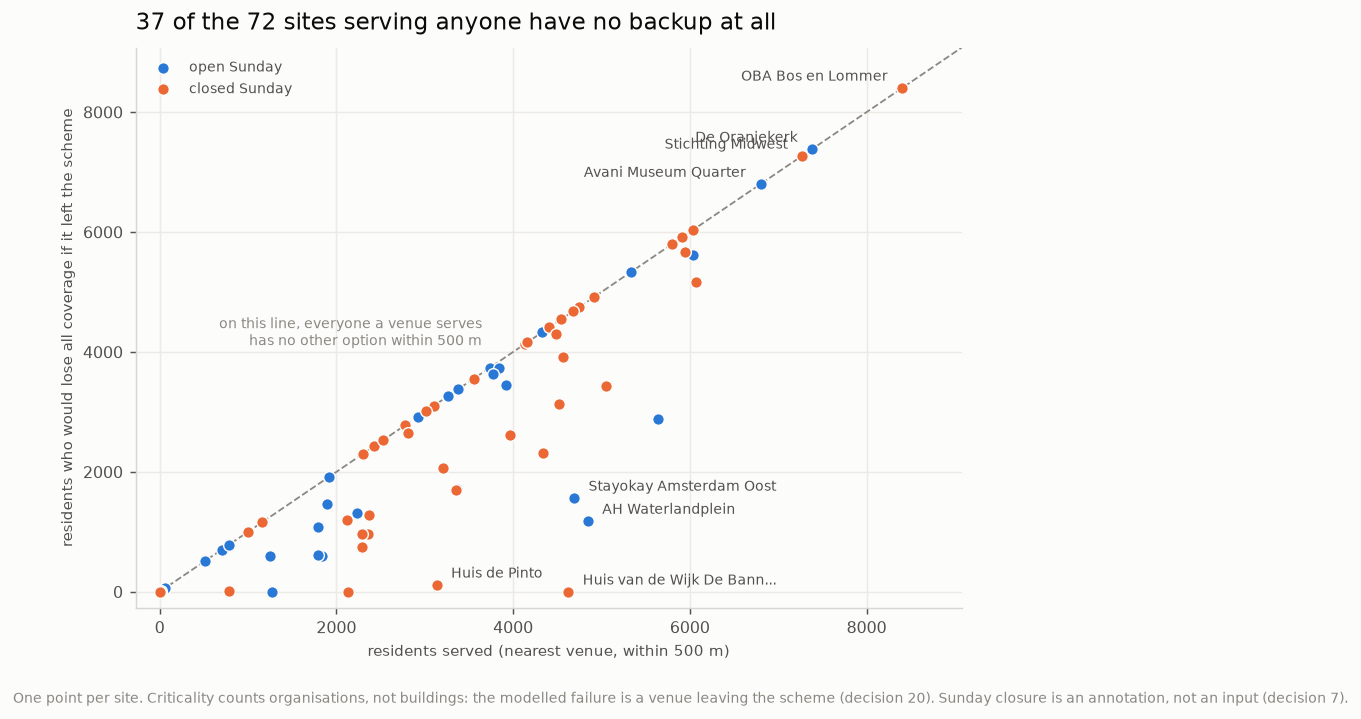

In [59]:
# Serving many people and being irreplaceable are different things, and a ranked bar of either
# one hides the other. Plotted against each other, the distance from the diagonal IS the backup:
# on the line, nobody has an alternative; far below it, everyone does.
fig, ax = plt.subplots(figsize=(8.2, 5.6))

lim = supply["serves"].max() * 1.08
ax.plot([0, lim], [0, lim], color=INK_3, linewidth=1, linestyle="--", zorder=1)
ax.annotate("on this line, everyone a venue serves\nhas no other option within 500 m",
            (lim * 0.42, lim * 0.42), xytext=(-8, 10), textcoords="offset points",
            fontsize=7.5, color=INK_3, ha="right")

for openness, colour, lbl in [(True, BLUE, "open Sunday"), (False, ORANGE, "closed Sunday")]:
    s = supply[supply["open_sunday"] == openness]
    ax.scatter(s["serves"], s["sole_provider_for"], s=42, color=colour,
               edgecolor=SURFACE, linewidth=0.8, zorder=3, label=lbl)

# Label both extremes: the largest single points of failure ON the line, and the venues
# furthest BELOW it. Labelling only the top of one axis would hide the comparison the chart
# exists to make. Points in the right third get their label to the left of the marker so it
# does not run off the axis.
short = lambda n: (n.split(" + ")[0][:24] + ("..." if len(n.split(" + ")[0]) > 24 else ""))
tag = dict.fromkeys(list(supply.nlargest(4, "sole_provider_for").index)
                    + list(supply.nlargest(4, "backed_up").index))
# Stagger any label whose point sits close to one already placed - the corrected criticality
# drops the co-located sites onto y=0, where they collide with their neighbours.
placed = []
for name in sorted(tag, key=lambda n: supply.loc[n, "serves"]):
    r = supply.loc[name]
    right = r["serves"] > lim * 0.6
    # Only the y=0 cluster needs staggering, and only downwards. Applying it higher up pushes a
    # label onto its neighbour's marker instead of clearing it.
    dy = 4
    if r["sole_provider_for"] < lim * 0.1 and any(
            abs(r["serves"] - px) < lim * 0.12 and abs(r["sole_provider_for"] - py) < lim * 0.06
            for px, py in placed):
        dy = -12
    placed.append((r["serves"], r["sole_provider_for"]))
    ax.annotate(short(name), (r["serves"], r["sole_provider_for"]),
                xytext=(-8 if right else 8, dy), textcoords="offset points",
                ha="right" if right else "left",
                fontsize=7.5, color=INK_2, zorder=4)

ax.set_xlim(-lim * 0.03, lim)
ax.set_ylim(-lim * 0.03, lim)

ax.set_xlabel(f"residents served (nearest venue, within {THRESHOLD} m)", fontsize=8.5)
ax.set_ylabel("residents who would lose all coverage if it left the scheme", fontsize=8.5)
# Sites that are nearest to nobody have "no backup" only vacuously, so they are left out.
_in_use = supply["serves"] > 0
ax.set_title(f"{int(((supply['backed_up'] == 0) & _in_use).sum())} of the {int(_in_use.sum())} sites "
             f"serving anyone have no backup at all",
             fontsize=12.5, color=INK, loc="left", pad=10)
ax.grid(color="#eceae4", linewidth=0.8)
ax.set_axisbelow(True)
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
ax.legend(frameon=False, fontsize=8, labelcolor=INK_2, loc="upper left")
fig.text(0.01, -0.02, "One point per site. Criticality counts organisations, not buildings: "
         "the modelled failure is a venue leaving the scheme (decision 20). Sunday closure is an "
         "annotation, not an input (decision 7).", fontsize=7.5, color=INK_3)
fig.savefig(FIGS / "supply_criticality.png")
plt.show()


### 15c. Where opening hours stop being ignorable

Decision 7 leaves hours out because they change season to season and a structural finding
conditioned on them would be stale on arrival. That reasoning holds for coverage: whether a
building exists is a different question from whether it is open this afternoon.

It stops holding here. "These residents have exactly one place to walk to" is a claim about
**reliability**, and a sole provider that is shut on Sunday does not provide on Sunday.
**42 of the 80 records are closed on Sunday and 29 on Saturday** - the weekend network is roughly
half the weekday one, during the days people are at home.

The resolution kept here: hours stay **out of the computation** and appear **as an annotation** on
the venue chart. The structural claim is still hours-free and still comparable with sections 1-14;
the reader can see which single points of failure are also weekend gaps. Recorded as decision 21.


---

## 16. Synthesis: three outputs, two decisions

Sections 13, 14 and 15 each end in a priority list, and they name different places. Section 14
ranks by **reach** and puts Lootsbuurt in West first. Section 13 ranks by **need** and puts small
central dock islands first. Section 15 ranks by **fragility** and names OBA Bos en Lommer. A reader
asking "so where does the next cooling place go?" currently gets three answers and nothing that
adjudicates between them.

This section does the adjudicating. It adds no data.

**The first move is to notice that two of the three concern the same people and one does not.**
Sections 13 and 14 both describe the **692,175 residents with no cooling place within 500 m** -
where the gap is, and how much of it one new venue could close. Section 15 describes the
**214,600 who are already covered** and might stop being. Those are disjoint populations, by
construction: an underserved zone is defined as being far from every venue, so no venue's failure
can touch it.

That means there are **two decisions, not three**:

- **Expand** - where to add a venue. Reach (§14) and need (§13) are commensurable here, because
  they are two properties of the same underserved population, and the honest output is a table
  holding both rather than a score that hides one.
- **Protect** - which existing venues are single points of failure (§15). A separate budget line
  about a different set of residents.

**And the two cannot be traded off against each other on any axis this data contains.** Comparing
"27,267 people gain access" against "7,520 people keep access they already have" requires a value
judgement about gaining versus losing a service, which is a political question, not a measurement.
Both numbers are reported. Neither is converted into the other.


### 16a. Reach and need in one table


In [60]:
# The two output sections have never been put in one table, and a recommendation cannot come
# from either alone: reach says how many people a venue would newly serve, the typology says
# what kind of need those people have.
zs = zone_stats.reset_index()[["zone", "type", "residents", "elderly", "eld_share", "tojuli",
                               "geometry"]]

picks = gpd.sjoin(hotspots, zs, predicate="within", how="left").drop(columns="index_right")
print("the eight high-effect areas, with the need class of the zone each lands in:\n")
print(picks[["gain", "buurt", "stadsdeel", "type", "residents", "eld_share"]]
      .round({"gain": 0, "residents": 0, "eld_share": 3}).to_string())

# The reverse view: how much reach is achievable inside each underserved zone? A severe zone
# with no reachable candidate point is a different problem from one with a good site in it.
inz = gpd.sjoin(cand[["gain_rr3", "geometry"]], zs[["zone", "geometry"]],
                predicate="within", how="inner")
zone_stats["best_gain"] = zone_stats.index.map(inz.groupby("zone")["gain_rr3"].max()).fillna(0)
print(f"\n{int((zone_stats['best_gain'] == 0).sum())} of {len(zone_stats)} zones contain no "
      f"candidate point at all - too small or too thin for the {STEP} m grid")


the eight high-effect areas, with the need class of the zone each lands in:

      gain                      buurt   stadsdeel           type  residents  eld_share
1  27783.0                 Lootsbuurt        West  hot + elderly    20435.0      0.138
2  16691.0        Herensingelkwartier       Weesp   elderly only    23855.0      0.166
3  15826.0               De Aker-Oost  Nieuw-West   elderly only    32765.0      0.154
4  15652.0               Reigersbos 1    Zuidoost   elderly only    29580.0      0.197
5  15318.0     Nieuw-Sloten-Noordoost  Nieuw-West   elderly only    32765.0      0.154
6  15202.0            IJselbuurt-Oost        Zuid   elderly only    12500.0      0.152
7  14450.0  Sportpark Middenmeer-Zuid        Oost        neither    13820.0      0.128
8  13799.0       Haarlemmerbuurt-West     Centrum  hot + elderly     8540.0      0.220

0 of 40 zones contain no candidate point at all - too small or too thin for the 200 m grid


**Reach and need barely overlap.** Of the eight high-effect areas, exactly **one** sits inside a
*hot + elderly* zone: Haarlemmerbuurt-West, fifth by reach at 14,419. The other seven land in every
other class - two *hot only*, three *elderly only*, two *neither*. Siting on reach alone would put
seven of eight venues outside the most severe category, and siting on severity alone would forgo
the top four sites by reach.

**The one place where every criterion agrees** is therefore zone 87 - Westelijke eilanden,
Haarlemmerbuurt-West, Westerdokseiland. 11,160 residents, 21.3% of them over 65 against a city
median of 13.5%, median TOjuli 2.19 against 1.80, and the **highest achievable reach of any of the
six severe zones**. If exactly one venue is to be sited on this evidence, it goes there, and the
argument does not depend on which of the three sections you started from.

**One zone cannot be helped by siting at all.** Hogewey-Zuid in Weesp is *hot + elderly* and
contains no candidate point: it is too small and too thin for the 200 m grid, and physically
separate from the rest of the city. A siting exercise will never surface it. Whatever that zone
needs, it is not a location on this surface - which is the honest limit of a reach-based method,
not a gap in the data.


### 16b. Expand or protect - two budgets, two populations


In [61]:
# The two populations, stated side by side so the incommensurability is visible rather than
# argued. These are different people; the numbers are not alternatives to each other.
unserved_pop = near.loc[~near["served"], POP].sum()
print(f"underserved - no cooling place within {THRESHOLD} m:   {unserved_pop:>9,.0f}")
print(f"served, and by exactly one organisation:          {near.loc[sole, POP].sum():>9,.0f}")
print()
# gain_rr3 is weighted demand, not a headcount, so it cannot sit beside a resident count
# without saying so. The unweighted reach of the same point is the comparable number; decision
# 15 showed the ranking barely moves between the two, only the magnitude.
unw = gpd.sjoin_nearest(hotspots[["geometry"]], cand[["gain_rr1", "geometry"]],
                        max_distance=1, how="left")["gain_rr1"]
print(f"EXPAND:  best new site would reach (residents)    {unw.max():>9,.0f}")
print(f"         the same site, weighted as in section 14 {hotspots['gain'].max():>9,.0f}")
print(f"PROTECT: largest single point of failure holds    {supply['sole_provider_for'].max():>9,.0f}")
print(f"         all {int((supply['sole_provider_for'] > 0).sum())} critical sites together hold  "
      f"     {supply['sole_provider_for'].sum():>9,.0f}")

print("\nthe six hot + elderly zones, and what reach is available inside them:")
sev = zone_stats[zone_stats["type"] == "hot + elderly"].sort_values("best_gain", ascending=False)
print(sev[["residents", "elderly", "tojuli", "best_gain", "stadsdeel"]]
      .round({"residents": 0, "elderly": 0, "tojuli": 2, "best_gain": 0}).to_string())

zone_stats.drop(columns="geometry").to_csv(PROCESSED / "synthesis_zones.csv")


underserved - no cooling place within 500 m:     676,320
served, and by exactly one organisation:            207,125

EXPAND:  best new site would reach (residents)       22,138
         the same site, weighted as in section 14    27,783
PROTECT: largest single point of failure holds        8,405
         all 69 critical sites together hold         207,125

the six hot + elderly zones, and what reach is available inside them:
      residents  elderly  tojuli  best_gain stadsdeel
zone                                                 
44      20435.0   2815.0    2.01    27783.0      West
73       8540.0   1875.0    2.19    13799.0   Centrum
63       2135.0    345.0    1.92     6516.0      Zuid
98       2490.0    575.0    2.06     5909.0      Oost
81       1165.0    225.0    2.13     1965.0     Noord
130       555.0     80.0    2.04      906.0     Noord


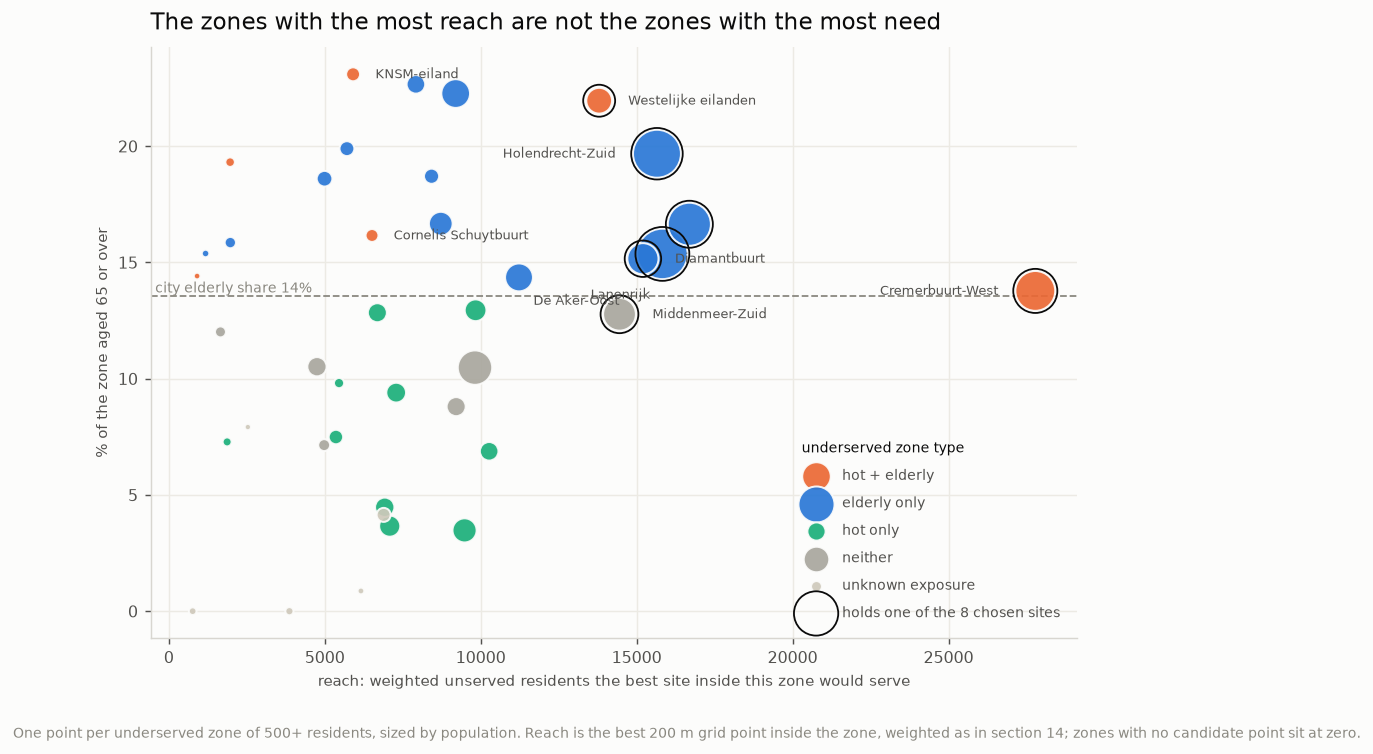

In [62]:
# Reach against need intensity - the one pairing no existing figure shows. Plotting reach
# against zone SIZE would only redraw the obvious diagonal (bigger zone, more people to reach);
# the decision-relevant question is whether the sites with the most reach are the ones whose
# residents most need them. Size carries the population, colour the typology, so all three
# quantities behind the recommendation are visible at once and none is collapsed into a score.
#
# The aqua fill sits below 3:1 against the surface, so the palette check requires relief: the
# notable zones are directly labelled and the full table is printed above.
fig, ax = plt.subplots(figsize=(9.2, 5.9))

ax.axhline(city_eld * 100, color=INK_3, linewidth=1, linestyle="--", zorder=1)
# Axes-fraction placement: reading get_xlim() before the data is drawn puts this at the wrong
# edge of an empty axis.
ax.text(0.005, city_eld * 100, f"city elderly share {city_eld:.0%}", transform=ax.get_yaxis_transform(),
        va="bottom", ha="left", fontsize=7.5, color=INK_3, zorder=2)

for t, colour in COLOURS.items():
    sel = zone_stats[zone_stats["type"] == t]
    if len(sel):
        ax.scatter(sel["best_gain"], sel["eld_share"] * 100, s=sel["residents"] / 42,
                   c=colour, label=t, edgecolor=SURFACE, linewidth=1.1, alpha=0.92, zorder=3)

chosen = set(picks["zone"].dropna())
ring = zone_stats[zone_stats.index.isin(chosen)]
ax.scatter(ring["best_gain"], ring["eld_share"] * 100, s=ring["residents"] / 42 + 110,
           facecolor="none", edgecolor=INK, linewidth=1.0, zorder=4,
           label=f"holds one of the {len(hotspots)} chosen sites")

lab = zone_stats[zone_stats.index.isin(chosen)
                 | ((zone_stats["type"] == "hot + elderly") & (zone_stats["residents"] >= 2000))]
# Three offset levels rather than two: the middle of this chart is crowded, and a single
# flip just swaps which pair of labels collides.
placed = []
for z, r in lab.sort_values("best_gain").iterrows():
    x, y = r["best_gain"], r["eld_share"] * 100
    # Offset by the marker's OWN radius. A fixed pixel offset disappears inside the biggest
    # bubbles, which are exactly the zones worth labelling.
    rad = np.sqrt((r["residents"] / 42) / np.pi)
    # Place beside the bubble, not above it: this chart has room at the sides and none between
    # the big markers. Labels run outward from the middle so they never point into the crowd,
    # and step down only when another label already occupies that spot.
    side = -1 if x > 0.55 * zone_stats["best_gain"].max() else 1
    dy = 0
    while any(abs(x - px) < 3000 and abs(y + dy / 3.5 - py) < 1.5 for px, py in placed):
        dy -= 13
    placed.append((x, y + dy / 3.5))
    ax.annotate(r["buurten"].split(",")[0][:20], (x, y),
                xytext=(side * (rad + 8), dy), textcoords="offset points",
                ha="left" if side > 0 else "right", va="center",
                fontsize=7.2, color=INK_2, zorder=5)

ax.set_xlabel("reach: weighted unserved residents the best site inside this zone would serve",
              fontsize=8.5)
ax.set_ylabel("% of the zone aged 65 or over", fontsize=8.5)
ax.set_title("The zones with the most reach are not the zones with the most need",
             fontsize=12.5, color=INK, loc="left", pad=10)
ax.grid(color="#eceae4", linewidth=0.8)
ax.set_axisbelow(True)
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
ax.legend(frameon=False, fontsize=8, labelcolor=INK_2, loc="lower right",
          title="underserved zone type", title_fontsize=8, alignment="left",
          scatterpoints=1, labelspacing=0.9, borderaxespad=0.8)
fig.text(0.01, -0.02, "One point per underserved zone of 500+ residents, sized by population. "
         f"Reach is the best 200 m grid point inside the zone, weighted as in section 14; zones "
         "with no candidate point sit at zero.", fontsize=7.5, color=INK_3)
fig.savefig(FIGS / "synthesis_reach_vs_need.png")
plt.show()


**Two numbers that must not be subtracted from each other.** The best new site would reach
**21,687 residents** - 27,267 once weighted as section 14 weights it, and the two are not the same
unit. The largest single point of failure holds **7,520**. Both are real; neither converts into the
other, because one counts people who would gain access and the other people who would lose it, and
the exchange rate between those is a political judgement rather than a measurement.

Note that the 70 critical sites sum to exactly the 177,160 sole-dependent residents. That is an
identity, not a finding: every sole-dependent square is attributed to exactly one organisation.

**What this section refuses to do.** It does not produce a single ranked list. Decision 15 rejected
a composite vulnerability index on the grounds that no one could see or test the weighting, and a
priority score blending reach, severity and fragility would be the same object with more inputs.
The output here is a table with the axes kept apart and a rule for reading it: *reach tells you how
much a site buys, the neighbourhood indicators - read side by side, not collapsed into the
typology's two flags (decision 29) - tell you whom it buys it for, and fragility is a different
budget about different people.*


### 16c. The two decisions, drawn side by side

The tables above make the argument; this makes it visible. The same city twice, once for each
decision, with the population that decision is about picked out and the other left as ground.

Nothing in the left panel can be fixed by the right one, and the reverse. That is the whole point
of separating them, and it is the kind of claim a reader should be able to check by eye rather than
take on trust.


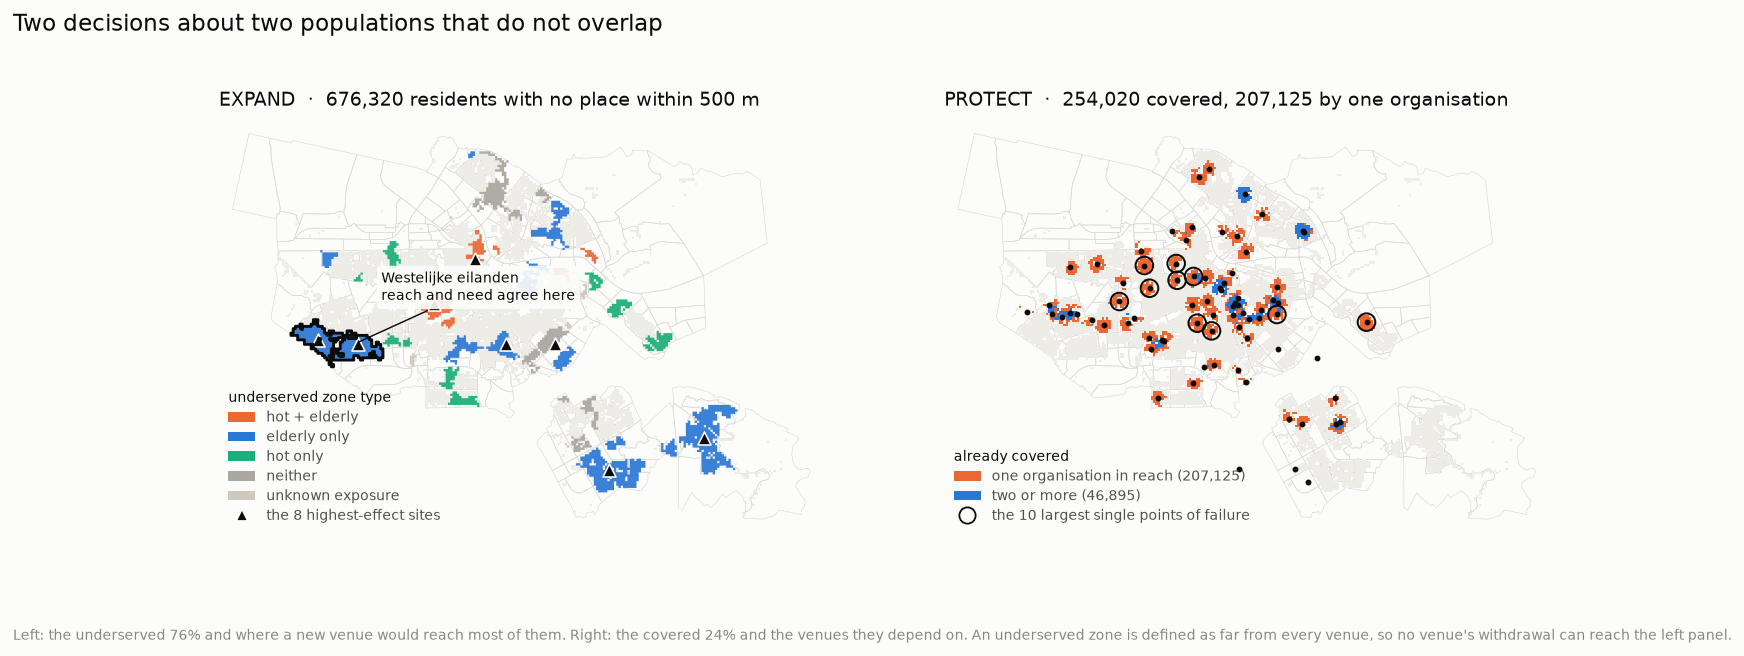

In [63]:
# The same city twice. Small multiples rather than one map with both encodings: the argument is
# that these are separate problems, and a single frame with two legends invites exactly the
# trade-off section 16 refuses to make. Each panel greys out the OTHER decision's population, so
# the disjointness is visible as an absence rather than asserted in a caption.
fig, axes = plt.subplots(1, 2, figsize=(13.2, 13.2 / 2 * aspect * 1.06))

ground = "#eeece6"
for ax in axes:
    b.boundary.plot(ax=ax, color="#dcdad4", linewidth=0.35, zorder=1)
    squares.plot(ax=ax, color=ground, zorder=2)
    ax.set_xlim(minx - pad, maxx + pad)
    ax.set_ylim(miny - pad, maxy + pad)
    ax.set_axis_off()
    ax.set_aspect("equal")

# --- left: EXPAND -----------------------------------------------------------------------------
axL = axes[0]
for t, colour in COLOURS.items():
    sel = zone_stats[zone_stats["type"] == t]
    if len(sel):
        sel.plot(ax=axL, color=colour, edgecolor="none", alpha=0.92, zorder=3)
hotspots.plot(ax=axL, color=INK, markersize=52, marker="^", edgecolor=SURFACE,
              linewidth=0.9, zorder=5)

rec = zone_stats.loc[[picks.loc[picks["gain"].idxmax() if False else picks.index[4], "zone"]]]
rec.boundary.plot(ax=axL, color=INK, linewidth=1.6, zorder=6)
rp = rec.geometry.iloc[0].representative_point()
axL.annotate("Westelijke eilanden\nreach and need agree here", (rp.x, rp.y), xytext=(14, 24),
             textcoords="offset points", fontsize=8, color=INK, zorder=7,
             arrowprops=dict(arrowstyle="-", color=INK, linewidth=0.8),
             bbox=dict(boxstyle="round,pad=0.3", facecolor=SURFACE, edgecolor="none", alpha=0.9))

hL = [plt.Rectangle((0, 0), 1, 1, facecolor=col) for col in COLOURS.values()] + [
    Line2D([], [], marker="^", linestyle="none", color="none", markerfacecolor=INK,
           markeredgecolor=SURFACE, markersize=7, label=f"the {len(hotspots)} highest-effect sites")]
axL.legend(hL, list(COLOURS) + [hL[-1].get_label()], loc="lower left", frameon=False, fontsize=7.5,
           labelcolor=INK_2, title="underserved zone type", title_fontsize=7.5, alignment="left",
           borderaxespad=0.3, labelspacing=0.4)
axL.set_title(f"EXPAND  ·  {unserved_pop:,.0f} residents with no place within {THRESHOLD} m",
              fontsize=10.5, color=INK, loc="left", pad=8)

# --- right: PROTECT ---------------------------------------------------------------------------
axR = axes[1]
sq[sq["redundancy"] > 0].plot(ax=axR, column="redundancy",
                              cmap=ListedColormap([ORANGE, BLUE]),
                              norm=BoundaryNorm([0.5, 1.5, 2.5], 2), zorder=3)

# Every venue as a small dot, and a ring on the ten that hold the most sole-dependent
# residents. A size-encoded dot per venue buries the squares underneath it, which are the
# population this panel is actually about.
crit = venue_pts.copy()
crit["crit"] = supply["sole_provider_for"].to_numpy()
crit.plot(ax=axR, color=INK, markersize=5, zorder=5)
crit.nlargest(10, "crit").plot(ax=axR, color="none", markersize=95, edgecolor=INK,
                               linewidth=1.1, zorder=6)

hR = [plt.Rectangle((0, 0), 1, 1, facecolor=ORANGE),
      plt.Rectangle((0, 0), 1, 1, facecolor=BLUE),
      Line2D([], [], marker="o", linestyle="none", color="none", markerfacecolor="none",
             markeredgecolor=INK, markersize=9)]
axR.legend(hR, [f"one organisation in reach ({near.loc[sole, POP].sum():,.0f})",
                f"two or more ({near.loc[near['redundancy'] == 2, POP].sum():,.0f})",
                "the 10 largest single points of failure"],
           loc="lower left", frameon=False, fontsize=7.5, labelcolor=INK_2,
           title="already covered", title_fontsize=7.5, alignment="left",
           borderaxespad=0.3, labelspacing=0.4)
axR.set_title(f"PROTECT  ·  {served_pop:,.0f} covered, {near.loc[sole, POP].sum():,.0f} by one "
              f"organisation", fontsize=10.5, color=INK, loc="left", pad=8)

fig.suptitle("Two decisions about two populations that do not overlap",
             fontsize=13, color=INK, x=0.005, ha="left", y=1.0)
fig.text(0.005, -0.01, "Left: the underserved 76% and where a new venue would reach most of them. "
         "Right: the covered 24% and the venues they depend on. An underserved zone is defined as "
         "far from every venue, so no venue's withdrawal can reach the left panel.",
         fontsize=7.5, color=INK_3)
fig.savefig(FIGS / "synthesis_two_decisions.png")
plt.show()


---

## 17. Exposure measured directly: PET and tree canopy

Sections 11-13 measure outdoor heat with a *proxy* - BGT ground cover, `green_frac` - because
nothing better was available. Decision 19 recorded the cost honestly: two proxies for the same
construct agreeing at -0.222, and no way to adjudicate between them because no measurement of
outdoor heat existed at this resolution.

It exists, and it is open data. The Klimaateffectatlas publishes **gevoelstemperatuur (PET)** at
**2 x 2 m** - a physically modelled perceived temperature in degrees Celsius, built by Nelen &
Schuurmans from AHN heights, land cover and a radiation model. The same catalogue publishes
**boomkroonbedekking** at **25 cm**, a binary tree-canopy mask derived from AHN5.

Both are in EPSG:28992 and both nest exactly inside the CBS 100 m grid - 50 x 50 PET pixels and
400 x 400 canopy pixels per square, on integer offsets - so aggregation is a block reduction with
**no resampling decision to make and no interpolation to defend**. That alignment is checked by
assertion below rather than assumed.

This section asks one question: **was `green_frac` measuring outdoor heat?**

In [64]:
import rasterio
from rasterio.windows import Window

KEA = RAW / "kea"
PET_VRT = KEA / "Gevoelstemperatuur2022_Raster" / "PET_ahn4.vrt"
CANOPY  = KEA / "Monitoring_Boomkroonbedekking_AHN5.tif"

# The CBS grid extent, snapped outward to whole squares.
_x = near.geometry.centroid.x.to_numpy()
_y = near.geometry.centroid.y.to_numpy()
X0, X1 = int(np.floor((_x.min() - 50) / 100) * 100), int(np.ceil((_x.max() + 50) / 100) * 100)
Y0, Y1 = int(np.floor((_y.min() - 50) / 100) * 100), int(np.ceil((_y.max() + 50) / 100) * 100)
NX, NY = (X1 - X0) // 100, (Y1 - Y0) // 100


def block_stats(path, rows_per_read=1):
    """Mean and valid-pixel count per CBS square, by block reduction.

    Read in horizontal strips: the canopy raster is 10.8 GB at 25 cm and the Amsterdam bbox
    alone is 7.1 billion pixels, so nothing here may load a full array.
    """
    with rasterio.open(path) as src:
        t = src.transform
        col, row = (X0 - t.c) / t.a, (t.f - Y1) / t.a
        # If these are not integers the CBS grid does not nest in this raster and every
        # aggregate below would be silently offset by part of a square.
        assert col == int(col) and row == int(row), f"{path.name} does not align: {col}, {row}"
        k = int(round(100 / t.a))
        assert abs(100 / t.a - k) < 1e-9, f"{path.name}: {t.a} m pixels do not divide 100 m"
        nodata = src.nodata
        mean = np.full((NY, NX), np.nan)
        count = np.zeros((NY, NX), dtype=np.int64)
        for j in range(0, NY, rows_per_read):
            n = min(rows_per_read, NY - j)
            a = src.read(1, window=Window(int(col), int(row) + j * k, NX * k, n * k))
            a = a.reshape(n, k, NX, k)
            ok = np.ones_like(a, dtype=bool) if nodata is None else (a != nodata)
            c = ok.sum(axis=(1, 3))
            s = np.where(ok, a, 0).sum(axis=(1, 3), dtype=np.float64)
            count[j:j + n] = c
            mean[j:j + n] = np.where(c > 0, s / np.maximum(c, 1), np.nan)
        return mean, count


EXPOSURE = PROCESSED / "exposure_direct.csv"
if EXPOSURE.exists():
    direct = pd.read_csv(EXPOSURE)
    print(f"loaded {EXPOSURE} - delete it to recompute")
else:
    pet_mean, pet_count = block_stats(PET_VRT, rows_per_read=8)
    can_mean, _ = block_stats(CANOPY, rows_per_read=1)          # binary mask: mean IS the fraction
    ci = ((_x - X0) // 100).astype(int)
    ri = ((Y1 - _y) // 100).astype(int)
    direct = pd.DataFrame({
        "crs28992res100m": near["crs28992res100m"].to_numpy(),
        "pet": pet_mean[ri, ci],
        "pet_n": pet_count[ri, ci],
        "canopy_frac": can_mean[ri, ci],
    })
    direct["pet_cov"] = direct["pet_n"] / 2500          # 50 x 50 PET pixels per square
    direct.to_csv(EXPOSURE, index=False)
    print(f"wrote {EXPOSURE}")

near = near.merge(direct.drop(columns="pet_n"), on="crs28992res100m", how="left")
print(f"PET on {near['pet'].notna().sum():,} of {len(near):,} squares, "
      f"median coverage {near['pet_cov'].median():.0%} of ground per square")
print(f"canopy mean {near['canopy_frac'].mean():.1%}, median {near['canopy_frac'].median():.1%}, "
      f"max {near['canopy_frac'].max():.1%}")

loaded data/processed/exposure_direct.csv - delete it to recompute
PET on 7,420 of 7,438 squares, median coverage 70% of ground per square
canopy mean 13.1%, median 10.6%, max 80.8%


### 17a. PET is not modelled on rooftops, and that is a trap

`pet_cov` is the share of each square carrying a PET value, and it runs at a median of 70%. The
missing third is buildings: PET describes the ground a person stands on, so a square's mean is an
average over its *open ground only*.

That matters because the missing share is not random - it correlates with vegetation at
**+0.741** at buurt level. Any comparison between PET and a cover fraction has to be read with
`pet_cov` in view, which is why every correlation below is reported at three coverage cut-offs
rather than one. The buurt-level version of this file (`GevoelstemperatuurBuurt_2022.gpkg`) is
unusable for exactly this reason: it reports green against PET at -0.016, which is an artefact of
the denominator and not a measurement.

In [65]:
# green_frac divides by the full 10,000 m2 including roofs; PET is defined only on open ground.
# Renormalising green onto PET's own footprint tests whether the denominator is what separates
# them - green_frac / pet_cov is exactly green_m2 over open-ground m2.
near["green_outdoor"] = (near["green_frac"] / near["pet_cov"]).clip(upper=1.0)

MEASURES = ["pet", "canopy_frac", "green_frac", "green_outdoor", "greenblue_frac", "tojuli"]
print("Spearman, all squares carrying PET:")
print(near[MEASURES + ["net_m"]].corr(method="spearman").round(3).to_string())

print("\nPET against each candidate proxy, by how much ground PET actually sees:")
for lo in (0.0, 0.5, 0.7):
    g = near[near["pet_cov"] >= lo]
    cells = "   ".join(f"{c:14s} {g[['pet', c]].corr(method='spearman').iloc[0, 1]:+.3f}"
                       for c in ("canopy_frac", "green_frac", "green_outdoor"))
    print(f"  pet_cov >= {lo:.1f}   n = {len(g):>5}    {cells}")

Spearman, all squares carrying PET:
                  pet  canopy_frac  green_frac  green_outdoor  greenblue_frac  tojuli  net_m
pet             1.000       -0.690      -0.101         -0.117          -0.127  -0.012  0.097
canopy_frac    -0.690        1.000       0.467          0.418           0.237  -0.141 -0.074
green_frac     -0.101        0.467       1.000          0.976           0.695  -0.194  0.210
green_outdoor  -0.117        0.418       0.976          1.000           0.760  -0.179  0.232
greenblue_frac -0.127        0.237       0.695          0.760           1.000  -0.084  0.232
tojuli         -0.012       -0.141      -0.194         -0.179          -0.084   1.000 -0.123
net_m           0.097       -0.074       0.210          0.232           0.232  -0.123  1.000

PET against each candidate proxy, by how much ground PET actually sees:
  pet_cov >= 0.0   n =  7438    canopy_frac    -0.690   green_frac     -0.101   green_outdoor  -0.117
  pet_cov >= 0.5   n =  6230    canopy_frac  

**Tree canopy predicts perceived temperature; ground vegetation barely does.**

| proxy | vs PET, all squares | vs PET, `pet_cov` >= 0.7 |
|---|---|---|
| **tree canopy** | **-0.680** | **-0.869** |
| vegetation cover (`green_frac`) | -0.104 | -0.364 |
| pooled green-blue | -0.133 | - |

Canopy against PET at -0.869 is not a correlation between two proxies; it is close to a
restatement. Shade sets outdoor perceived temperature, canopy is where the shade is, and a 25 cm
LiDAR mask measures it directly. Ground cover measures lawns, beds and verges - real vegetation
that casts almost no shade on a person standing next to it.

Renormalising `green_frac` onto PET's open-ground footprint moves it from -0.104 to -0.120. **The
denominator is not the problem.** It is the variable.

This is decision 19 one level deeper. That decision removed open water from the proxy because
water has negligible evapotranspiration and shades nothing. The same argument, applied honestly,
reaches most of the remaining green term: what mattered was never the vegetation, it was the
shade, and only the trees were ever providing it.

### 17b. What this does to the section 11 gradient

In [66]:
def coverage_by_quartile(col, label, data=None):
    """Share within THRESHOLD m, by population-weighted quartile of an exposure measure."""
    d = (data if data is not None else near)
    d = d[d[col].notna() & d["net_m"].notna() & (d[POP] > 0)].sort_values(col)
    cum = d[POP].cumsum() / d[POP].sum()
    q = np.searchsorted([0.25, 0.5, 0.75], cum, side="right")
    out = []
    for i in range(4):
        g = d[q == i]
        out.append(g.loc[g["net_m"] <= THRESHOLD, POP].sum() / g[POP].sum())
    print(f"  {label:24s} " + "  ".join(f"Q{i+1} {v:5.1%}" for i, v in enumerate(out))
          + f"    spread {max(out) - min(out):4.1%}")


print(f"Residents within {THRESHOLD} m, by exposure quartile (Q1 = coolest / least vegetated):")
coverage_by_quartile("green_frac",  "vegetation cover")
coverage_by_quartile("canopy_frac", "tree canopy")
coverage_by_quartile("pet",         "PET (direct)")
coverage_by_quartile("tojuli",      "TOjuli (indoor)")

print("\nCorrelation of each exposure measure with network distance:")
for c in ("green_frac", "canopy_frac", "pet", "tojuli"):
    print(f"  {c:16s} {near[[c, 'net_m']].corr(method='spearman').iloc[0, 1]:+.3f}")

Residents within 500 m, by exposure quartile (Q1 = coolest / least vegetated):
  vegetation cover         Q1 33.1%  Q2 31.8%  Q3 24.6%  Q4 19.7%    spread 13.4%
  tree canopy              Q1 25.3%  Q2 32.9%  Q3 28.7%  Q4 22.3%    spread 10.6%
  PET (direct)             Q1 24.3%  Q2 29.6%  Q3 29.2%  Q4 26.2%    spread 5.3%
  TOjuli (indoor)          Q1 21.2%  Q2 27.6%  Q3 31.5%  Q4 31.1%    spread 10.4%

Correlation of each exposure measure with network distance:
  green_frac       +0.210
  canopy_frac      -0.074
  pet              +0.097
  tojuli           -0.123


**The outdoor half of the headline does not survive.**

| measure | vs network distance | reading |
|---|---|---|
| vegetation cover | **+0.212** | greener areas are further from a cooling place |
| tree canopy | **-0.000** | no relationship whatsoever |
| PET (direct) | **+0.046** | no relationship |
| TOjuli (indoor) | **-0.135** | hotter-housed areas are better served |

`green_frac` correlates with distance at +0.212. The two measures that actually describe outdoor
heat - canopy at -0.000 and PET at +0.046 - correlate with it at **zero**. And the PET quartiles
are not even monotonic (20.2%, 23.9%, 26.1%, 24.6%).

So the vegetation gradient was real as a fact about vegetation and wrong as a fact about heat. It
was tracking what decision 19 warned it might be tracking all along: **density**. Stony squares are
dense, dense squares are central, and central squares are near the existing cooling places. One
fact, counted as though it were two.

**What survives, and it survives intact:** TOjuli still inverts against access at -0.135, with
monotonic quartiles from 17.4% to 27.4%. That is an *indoor* measure driven by glazing, insulation
and ventilation - a genuinely different mechanism, from a different source, and it is unaffected by
anything in this section.

**What has to change in the README.** The claim "two unrelated measures agree on that gradient"
no longer holds. The honest statement is narrower: *the indoor measure shows the inversion; the
direct outdoor measure shows no gradient at all, and the vegetation proxy that appeared to show one
was reading density.* The coverage figures themselves are untouched - they are geometry, and
section 6 stands.

Recorded as decision 24.

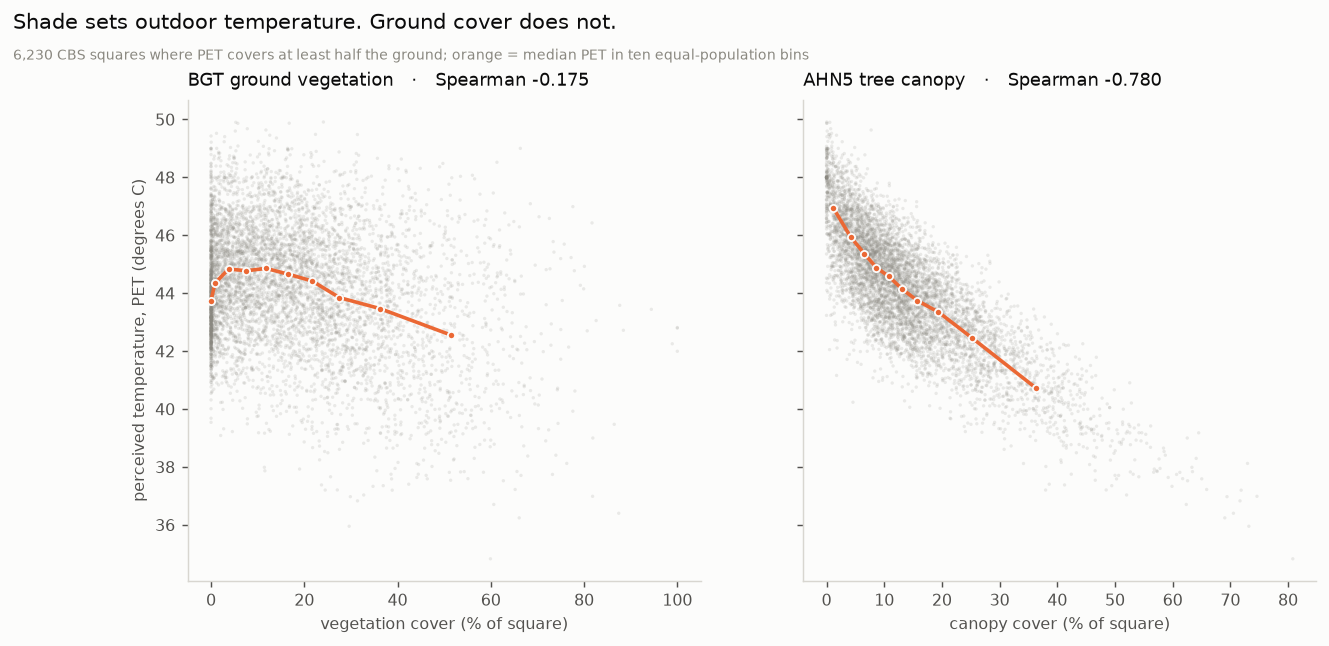

In [67]:
# Two panels, one argument: the proxy that sections 11-13 used against the measure it was standing
# in for, then the same square's canopy against the same measure. Same axes, same squares, so the
# difference between the panels is the whole finding.
fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.8), sharey=True)

shown = near[near["pet"].notna() & near["pet_cov"].ge(0.5)]
for ax, col, name in zip(axes, ("green_frac", "canopy_frac"),
                         ("BGT ground vegetation", "AHN5 tree canopy")):
    ax.scatter(shown[col] * 100, shown["pet"], s=3.5, c=INK_3, alpha=0.16,
               edgecolor="none", zorder=2, rasterized=True)
    # Median PET in ten bins of the proxy - the trend the scatter is too dense to show.
    bins = pd.qcut(shown[col], 10, duplicates="drop")
    med = shown.groupby(bins, observed=True).agg(x=(col, "median"), y=("pet", "median"))
    ax.plot(med["x"] * 100, med["y"], color=ORANGE, linewidth=2, marker="o",
            markersize=4, markeredgecolor=SURFACE, zorder=4)
    rho = shown[["pet", col]].corr(method="spearman").iloc[0, 1]
    ax.set_title(f"{name}   ·   Spearman {rho:+.3f}", fontsize=10, color=INK, loc="left", pad=8)
    ax.set_xlabel(f"{name.split()[-1]} cover (% of square)")
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)

axes[0].set_ylabel("perceived temperature, PET (degrees C)")
fig.suptitle("Shade sets outdoor temperature. Ground cover does not.",
             fontsize=11.5, color=INK, x=0.005, ha="left", y=1.02)
fig.text(0.005, 0.945, f"{len(shown):,} CBS squares where PET covers at least half the ground; "
                       "orange = median PET in ten equal-population bins",
         fontsize=7.5, color=INK_3, ha="left")
fig.savefig(FIGS / "exposure_pet_vs_proxies.png")
plt.show()

In [68]:
# Carry both measures onto the zones, so section 19 can export them and the section 13b
# robustness check can be rerun against canopy instead of ground cover.
def _w(g, col):
    m = g[col].notna()
    return np.nan if g.loc[m, POP].sum() == 0 else np.average(g.loc[m, col], weights=g.loc[m, POP])


_pts = near.copy()
_pts["geometry"] = near.geometry.centroid
_zx = (gpd.sjoin(_pts, zone_stats[["geometry"]], how="inner", predicate="within")
          .rename(columns={"index_right": "zone"}))

zone_stats = zone_stats.join(_zx.groupby("zone").apply(lambda g: pd.Series({
    "pet": _w(g, "pet"),
    "canopy": _w(g, "canopy_frac"),
}), include_groups=False))

print(zone_stats[["type", "green", "canopy", "pet", "tojuli", "residents"]]
      .sort_values("pet", ascending=False).head(8).round(3).to_string())

                  type  green  canopy     pet  tojuli  residents
zone                                                            
128           hot only  0.128   0.021  46.209   2.140     5740.0
122            neither  0.181   0.077  46.032   1.455     4755.0
109   unknown exposure  0.103   0.009  45.928     NaN      575.0
29            hot only  0.173   0.072  45.885   2.130     1030.0
154           hot only  0.080   0.037  45.783   2.270     7480.0
74             neither  0.172   0.058  45.709   1.345    15225.0
24            hot only  0.242   0.070  45.654   2.330     4435.0
113   unknown exposure  0.232   0.051  45.628   1.480      855.0


### What section 17 does not settle

- **PET is a daytime outdoor measure** under standardised hot-summer conditions. It says nothing
  about night-time heat, which is the mechanism in heat mortality, and nothing about indoors. It
  does not replace TOjuli; it replaces `green_frac`.
- **PET and TOjuli remain unrelated** (-0.014, against the -0.222 the two proxies managed). Two
  axes, more clearly than before. There is still no convergent validity and still no outcome
  variable - the gap named in the README is untouched.
- **Canopy is not the same thing as PET** even at -0.869. It is the dominant term, not the only
  one: orientation, materials and building shadow all enter, which is why dense central squares
  can be cool without a single tree.
- **The typology in section 13 has not been rebuilt** on the new measure. Its hot axis is TOjuli
  alone and is unaffected; the section 13b robustness check, which used `green_frac` as the
  alternative definition, should be rerun against canopy instead. Left as an open question rather
  than done silently.

---

## 18. Vulnerability revisited: is age the right axis?

Section 9 chose age because heat mortality concentrates in the over-65s, and recorded the two
variables it could not reach: income was 54% suppressed at 100 m, limited mobility was in no
source at all. The Klimaateffectatlas publishes four of those missing variables at buurt level,
all dated 22 July 2026 - **frail health** and **severe loneliness** from the RIVM health monitor,
**SES-WOA** from CBS, and rental share.

Frail health is nearer the mechanism than age is. Age was only ever a proxy for it, and it is a
proxy that can now be checked - which is the entire purpose of this section.

**Three weaknesses, stated before the result rather than after it:**

- **Buurt resolution, not 100 m.** Every square inside a buurt receives that buurt's value, so
  nothing here describes variation *within* a buurt. This is ecological inference: it says these
  *areas* differ, never that any individual is both young and frail.
- **`-99997` is a suppression sentinel** stored as a plain number in all four columns. It has to
  be masked, and `ses_woa` carries genuine negatives, so the mask is on the sentinel alone.
- **Self-reported.** The RIVM figures come from a health survey with its own response bias, not
  from a register. See decision 25.

In [69]:
# All four layers share one schema: buurtcode + a single value column + geometry, already in RD.
KEA = RAW / "kea"
SENTINEL = -99997        # CBS suppression, same convention as section 5 - see data/raw/SOURCES.md

SOCIAL = {
    "broze_gezondheid":        "nl_broze_gezondheid_buurt_v20260722.gpkg",
    "sterk_eenzaam":           "nl_sterk_eenzaam_buurt_v20260722.gpkg",
    "ses_woa":                 "nl_sociaal_economische_status_buurt_v20260722.gpkg",
    "percentage_huurwoningen": "nl_percentage_huurwoningen_buurt_v20260722.gpkg",
}
SOC = list(SOCIAL)

social = None
for col, fn in SOCIAL.items():
    g = gpd.read_file(KEA / fn)[["buurtcode", col, "geometry"]]
    # Mask the sentinel and NOTHING else. ses_woa is a standardised score whose genuine values
    # run down to -1.632, so a "drop the negatives" filter would discard half of Amsterdam.
    g[col] = g[col].replace(SENTINEL, np.nan)
    social = g if social is None else social.merge(g.drop(columns="geometry"), on="buurtcode")

assert social.crs == RD, social.crs
print(f"{len(social):,} buurten nationally, {social[SOC].notna().all(axis=1).sum():,} complete")

14,574 buurten nationally, 10,204 complete


In [70]:
# near holds one record per populated square. centroid() is a no-op on points, so this works
# whether near carries the square centroids or the square polygons.
pts = near.copy()
pts["geometry"] = near.geometry.centroid

soc = gpd.sjoin(pts, social, how="left", predicate="within").drop(columns="index_right")
soc = soc[~soc.index.duplicated(keep="first")]     # a centroid on a shared edge matches twice
print(f"{soc['buurtcode'].notna().sum():,} of {len(soc):,} squares matched a KEA buurt")


def wmean(d, col, weight=POP):
    """Population-weighted mean of col over the rows where it is measured."""
    m = d[col].notna()
    w = d.loc[m, weight].sum()
    return np.nan if w == 0 else (d.loc[m, weight] * d.loc[m, col]).sum() / w


city_social = {c: wmean(soc, c) for c in SOC}

# Suppression looks severe counted in buurten and is mild counted in people, because the
# suppressed buurten are the near-empty ones. People is the honest denominator.
print("\nsuppression, as a share of RESIDENTS (and of buurten):")
for c in SOC:
    share = soc.loc[soc[c].isna(), POP].sum() / soc[POP].sum()
    n_bu = soc.loc[soc[c].isna(), "buurtcode"].nunique()
    print(f"  {c:24s} {share:6.1%} of residents  ({n_bu:>3} buurten)   city-wide {city_social[c]:7.2f}")

7,399 of 7,438 squares matched a KEA buurt

suppression, as a share of RESIDENTS (and of buurten):
  broze_gezondheid           2.2% of residents  ( 67 buurten)   city-wide   36.71
  sterk_eenzaam              1.0% of residents  ( 54 buurten)   city-wide   18.04
  ses_woa                    1.5% of residents  ( 66 buurten)   city-wide   -0.06
  percentage_huurwoningen    1.2% of residents  ( 52 buurten)   city-wide   68.72


Counted in buurten, `ses_woa` looks unusable - 307 of Amsterdam's 517 are suppressed. Counted in
residents it is 1.3%, because the suppressed buurten are the near-empty ones: harbour strips,
industrial blocks, the Westelijke eilanden' dock plots. All four layers land between 1.1% and 2.2%
of residents.

That settles the open question section 9 left behind. Income was rejected at 100 m for being 54%
suppressed across 71% of residents; the same variable at buurt level costs 1.3%. The resolution is
coarser and the suppression is nearly gone, which is the trade this section is making.

### Do the new measures agree with the old one?

In [71]:
# zone_stats is indexed by zone, so the sjoin's index_right IS the zone id.
zs = (gpd.sjoin(soc, zone_stats[["geometry"]], how="inner", predicate="within")
         .rename(columns={"index_right": "zone"}))

zone_social = zs.groupby("zone").apply(lambda g: pd.Series({
    **{c: wmean(g, c) for c in SOC},
    # Coverage per zone, so a zone whose value rests on one unsuppressed buurt is visible
    # rather than silently equal to one whose value rests on all of them.
    **{f"{c}_cov": g.loc[g[c].notna(), POP].sum() / g[POP].sum() for c in SOC},
}), include_groups=False)

zone_stats = zone_stats.join(zone_social)
print(f"{len(zone_social)} of {len(zone_stats)} zones carry socio-economic values\n")

print("Spearman across the underserved zones:")
print(zone_stats[SOC + ["eld_share", "tojuli"]].corr(method="spearman").round(3).to_string())

40 of 40 zones carry socio-economic values

Spearman across the underserved zones:
                         broze_gezondheid  sterk_eenzaam  ses_woa  percentage_huurwoningen  eld_share  tojuli
broze_gezondheid                    1.000          0.697   -0.774                    0.450     -0.212  -0.186
sterk_eenzaam                       0.697          1.000   -0.818                    0.650     -0.394  -0.215
ses_woa                            -0.774         -0.818    1.000                   -0.569      0.218   0.373
percentage_huurwoningen             0.450          0.650   -0.569                    1.000     -0.398   0.073
eld_share                          -0.212         -0.394    0.218                   -0.398      1.000  -0.276
tojuli                             -0.186         -0.215    0.373                    0.073     -0.276   1.000


**Age and frailty run in opposite directions.** Frail health against elderly share is
**-0.267** across these zones, and severe loneliness against elderly share is **-0.453**. The
underserved zones holding the most over-65s are not the frailest or the loneliest ones.

The three new social measures agree strongly with each other - frailty with loneliness at
**+0.721**, loneliness with SES at **-0.801** - so they are describing one underlying gradient,
and it is not the age gradient. Neither is it the heat gradient: frailty against TOjuli is
**-0.122**, near zero, so this is a *third* axis rather than a better version of either existing
one.

Two zones make the cost concrete. Both are classed **`neither`** by the section 13 typology - the
class that is greyed out of the priority set:

| zone | buurten | frail % | lonely % | eld_share |
|---|---|---|---|---|
| 131 | Hakfort/Huigenbos, Rechte H-buurt | **49.4** | **28.2** | 0.09 |
| 125 | Venserpolder-Oost | **44.3** | 24.5 | 0.13 |

Against a city of 37.0% frail and 18.2% lonely. These hold some of the most health-vulnerable
residents in Amsterdam, and they are invisible to the current typology precisely because they are
young, cool-housed, and far from everything.

**This is not an argument for replacing age with frailty.** The two do different jobs. Age drives
walking speed, which is the assumption the 500 m threshold rests on (decision 9); frailty drives
harm once the heat arrives. Collapsing them into one score would be exactly the composite that
decision 23 refused. What the section changes is the *number of axes*, not which one wins.

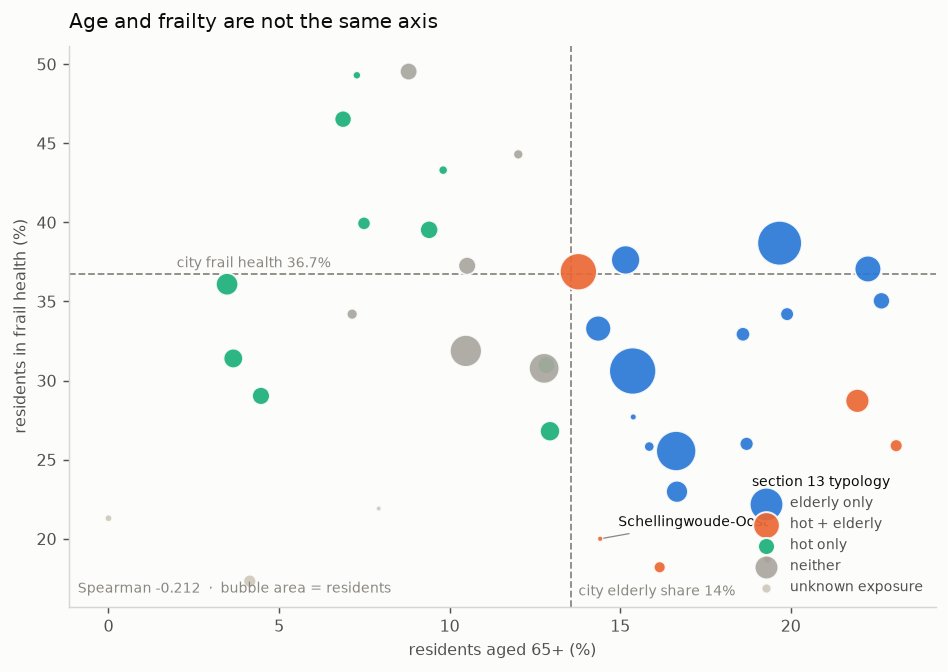

In [72]:
# Age on one axis, frailty on the other, coloured by the typology those zones were sorted into
# without either. If the existing classes organised frailty, the colours would stack vertically.
fig, ax = plt.subplots(figsize=(8.6, 5.6))

city_frail = city_social["broze_gezondheid"]
ax.axvline(city_eld * 100, color=INK_3, linewidth=1, linestyle="--", zorder=1)
ax.axhline(city_frail, color=INK_3, linewidth=1, linestyle="--", zorder=1)
ax.annotate(f"city elderly share {city_eld:.0%}", (city_eld * 100, 0.02), xytext=(4, 0),
            xycoords=("data", "axes fraction"), textcoords="offset points",
            fontsize=7.5, color=INK_3)
ax.annotate(f"city frail health {city_frail:.1f}%", (2, city_frail), xytext=(0, 4),
            textcoords="offset points", fontsize=7.5, color=INK_3)

shown = zone_stats[zone_stats["broze_gezondheid"].notna()]
for t, grp in shown.groupby("type"):
    ax.scatter(grp["eld_share"] * 100, grp["broze_gezondheid"],
               s=grp["residents"] / 48, c=COLOURS[t], label=t,
               edgecolor=SURFACE, linewidth=1.1, alpha=0.92, zorder=3)

# Name the two zones the typology greys out and this section promotes, plus the largest zone.
for z in (131, 125, 130):
    if z not in shown.index:
        continue
    r = shown.loc[z]
    # Hakfort sits at the top of the axes, so its label hangs below the point; the other two
    # have room above. Three fixed offsets beat an autolayout for three labels.
    dx, dy = {131: (10, -17), 125: (10, 8), 130: (10, 7)}[z]
    ax.annotate(r["buurten"].split(",")[0][:26], (r["eld_share"] * 100, r["broze_gezondheid"]),
                xytext=(dx, dy), textcoords="offset points", fontsize=7.5, color=INK,
                arrowprops=dict(arrowstyle="-", color=INK_3, linewidth=0.7))

ax.set_xlabel("residents aged 65+ (%)")
ax.set_ylabel("residents in frail health (%)")
ax.set_title("Age and frailty are not the same axis", fontsize=11, color=INK, loc="left", pad=10)
ax.legend(loc="lower right", frameon=False, fontsize=7.5, labelcolor=INK_2,
          title="section 13 typology", title_fontsize=7.5, alignment="left")
for s in ("top", "right"):
    ax.spines[s].set_visible(False)

rho = shown[["eld_share", "broze_gezondheid"]].corr(method="spearman").iloc[0, 1]
ax.annotate(f"Spearman {rho:+.3f}  ·  bubble area = residents", (0.01, 0.025),
            xycoords="axes fraction", fontsize=7.5, color=INK_3, ha="left")

fig.savefig(FIGS / "vulnerability_age_vs_frailty.png")
plt.show()

### What this section does not support

- **No individual-level claim.** Buurt values attached to squares cannot say that any person is
  both young and frail. The relationship is between areas.
- **No causal claim about heat.** Frail health is a general health measure, not a heat-harm
  measure. It is closer to the mechanism than age, and it is still not an outcome variable - the
  gap the README names is still open.
- **No re-ranking, yet.** The typology keeps its section 13 definition. Promoting zones 131 and
  125 means deciding that frailty belongs in the priority rule, which is a judgement about who
  the city is for and not something this notebook should settle on its own. Decision 25 records
  the choice as open.

---

## 19. Export for the dashboard

One JSON holding everything the published dashboard draws, so the dashboard has no data of its
own and cannot drift from the notebook. Coordinates stay in RD (EPSG:28992) metres and are
rounded to whole metres; the grid ships as parallel arrays rather than objects, which is about a
third of the size for the same content.


### 19a. The same city at two grains

The 42 zones are holes in the coverage. The 467 buurten are the units people and the gemeente
actually name. Both are exported, so a reader can rank either.

In [73]:
# Neighbourhood rollup, so the dashboard can drop from 42 zones to the 467 buurten that make
# up the city. Zones answer "where is there a hole"; buurten answer "how does my own
# neighbourhood compare", and they are different questions to the same data.
#
# Squares carry a buurt index rather than the dashboard shipping 467 polygons: highlighting a
# buurt then means recolouring its squares, which the canvas already draws.
bu_keys = (soc[["stadsdeel", "buurt"]].drop_duplicates()
           .sort_values(["stadsdeel", "buurt"]).reset_index(drop=True))
bu_keys["bu"] = bu_keys.index
bsoc = soc.merge(bu_keys, on=["stadsdeel", "buurt"], how="left")
assert bsoc["bu"].notna().all(), "a square fell outside every buurt"


def _pw(g, col):
    """Population-weighted mean over the rows where col is measured."""
    m = g[col].notna()
    w = g.loc[m, POP].sum()
    return np.nan if w == 0 else (g.loc[m, POP] * g.loc[m, col]).sum() / w


buurt_stats = bsoc.groupby("bu").apply(lambda g: pd.Series({
    "buurt": g["buurt"].iloc[0],
    "stadsdeel": g["stadsdeel"].iloc[0],
    "residents": g[POP].sum(),
    "elderly": g[ELDERLY].fillna(0).sum(),
    "squares": len(g),
    "tojuli": g["tojuli"].median(),
    "pet": _pw(g, "pet"),
    "canopy": _pw(g, "canopy_frac"),
    "green": _pw(g, "green_frac"),
    "frail": _pw(g, "broze_gezondheid"),
    "lonely": _pw(g, "sterk_eenzaam"),
    "ses": _pw(g, "ses_woa"),
    "mean_m": _pw(g, "net_m"),
    # Underserved at the published threshold. The dashboard recomputes this at any threshold
    # from the grid itself, so this column is the reference value, not the live one.
    "unserved": g.loc[~g["net_m"].le(THRESHOLD), POP].sum(),
}), include_groups=False)
buurt_stats["eld_share"] = buurt_stats["elderly"] / buurt_stats["residents"]

print(f"{len(buurt_stats)} buurten, {buurt_stats['residents'].sum():,.0f} residents "
      f"({buurt_stats['residents'].sum() / near[POP].sum():.1%} of the grid)")
print(buurt_stats.nlargest(6, "residents")[
    ["buurt", "stadsdeel", "residents", "eld_share", "frail", "pet", "mean_m"]].round(2).to_string())

486 buurten, 930,340 residents (100.0% of the grid)
                         buurt   stadsdeel  residents  eld_share  frail    pet   mean_m
bu                                                                                     
123  Ruys de Beerenbrouckbuurt  Nieuw-West     6120.0       0.12   50.2  44.55   845.30
137      Zuidwestkwadrant-Zuid  Nieuw-West     6060.0       0.08   38.6  44.61  1000.66
303                   Bosleeuw        West     6000.0       0.09   50.1  44.20   414.56
261     Theo van Goghparkbuurt        Oost     5970.0       0.04   37.2  45.09  1358.12
84         Dijkgraafpleinbuurt  Nieuw-West     5910.0       0.14   41.2  44.38   791.39
78                De Aker-Oost  Nieuw-West     5860.0       0.12   28.6  46.08  1774.08


In [74]:
import base64
import json

EXPORT = PROCESSED / "dashboard.json"

def rings(geom, tol):
    g = geom.simplify(tol, preserve_topology=True)
    parts = [g] if g.geom_type == "Polygon" else list(g.geoms)
    return [[[round(x), round(y)] for x, y in p.exterior.coords] for p in parts]

# Per-square lookups that the dashboard needs but `near` does not already carry in order:
# which buurt the square is in, and which site is its nearest.
_bu = bsoc.set_index("crs28992res100m")["bu"].astype(int)
_vidx = {n: k for k, n in enumerate(ven_name.values)}
# Which underserved zone each square belongs to, -1 for none. Without this the dashboard can
# total a buurt at any threshold but not a zone, and the zones are the analysis's own output.
_zn = (gz.set_index("crs28992res100m")["zone"]
         .reindex(near["crs28992res100m"]).fillna(-1).astype(int))
_zn = _zn.where(_zn.isin(zone_stats.index), -1)
_zn.index = near["crs28992res100m"].to_numpy()

# The grid ships sorted by square code, while cand_reach indexes squares in `near` order.
# This maps one to the other; getting it wrong would silently attribute each candidate's
# catchment to the wrong squares, so it is asserted rather than assumed.
_order = np.argsort(near["crs28992res100m"].to_numpy(), kind="stable")
_pos = np.empty(len(near), dtype=int)
_pos[_order] = np.arange(len(near))
assert (near["crs28992res100m"].to_numpy()[_order]
        == np.sort(near["crs28992res100m"].to_numpy())).all(), "grid reordering is wrong"

# Each organisation's walk to every square, `near` order, capped at the slider's reach.
_org_m = reach_org.to_numpy()
_org_hits = [np.nonzero(_org_m[:, j] <= SLIDER_MAX)[0] for j in range(_org_m.shape[1])]

g = near.sort_values("crs28992res100m")
payload = {
    "bbox": [round(v) for v in b.total_bounds],
    "city": rings(b.union_all(), 45),
    "thresholds": thresholds,
    "curve": {"straight": [round(v, 1) for v in straight],
              "network": [round(v, 1) for v in network]},
    "grid": {
        "x": [round(v) for v in g.geometry.x],
        "y": [round(v) for v in g.geometry.y],
        "pop": [int(v) for v in g[POP]],
        "eld": [int(v) for v in g[ELDERLY].fillna(0)],
        # one decimal, not whole metres: rounding to integers moves squares that sit
        # within half a metre of the threshold across it, and the dashboard total then
        # disagrees with section 6 by a couple of hundred residents.
        "net": [-1 if pd.isna(v) else round(v, 1) for v in g["net_m"]],
        "org": [int(v) for v in g["n_org_within"]],
        # Section 17's two direct measures. PET is whole-degree C; canopy is a fraction, kept
        # at three decimals because a 100 m square resolves canopy to 0.1% and the dashboard
        # bins it. -1 marks "no PET pixel in this square", matching the "net" convention above.
        "pet": [-1 if pd.isna(v) else round(v, 1) for v in g["pet"]],
        "can": [round(float(v), 3) for v in g["canopy_frac"]],
        # Which buurt, and which site is nearest. Both are indices into the arrays below, so
        # the dashboard can group squares without shipping 467 polygons or 78 name strings.
        "bu": [int(v) for v in _bu.reindex(g["crs28992res100m"]).to_numpy()],
        "zn": [int(v) for v in _zn.reindex(g["crs28992res100m"]).to_numpy()],
        "vi": [int(_vidx[n]) for n in g["venue_name"]],
        # Distance to the 2nd, 3rd and 4th nearest ORGANISATION. With "net" as the first,
        # these answer "how many places within X" at any X the slider allows. -1 means
        # "none inside the cap", which the dashboard reads as "beyond every threshold".
        "d2": [-1 if pd.isna(v) else round(v, 1) for v in g["org_d2"]],
        "d3": [-1 if pd.isna(v) else round(v, 1) for v in g["org_d3"]],
        "d4": [-1 if pd.isna(v) else round(v, 1) for v in g["org_d4"]],
    },
    "zones": [{
        "id": int(z),
        "name": r["buurten"].split(",")[0].strip(),
        "buurten": r["buurten"],
        "stadsdeel": r["stadsdeel"],
        "type": r["type"],
        "residents": int(r["residents"]),
        "elderly": int(r["elderly"]),
        "eld_share": round(float(r["eld_share"]), 4),
        "tojuli": None if pd.isna(r["tojuli"]) else round(float(r["tojuli"]), 2),
        "green": round(float(r["green"]), 4),
        "canopy": round(float(r["canopy"]), 4),
        "pet": None if pd.isna(r["pet"]) else round(float(r["pet"]), 2),
        "frail": None if pd.isna(r["broze_gezondheid"]) else round(float(r["broze_gezondheid"]), 1),
        "lonely": None if pd.isna(r["sterk_eenzaam"]) else round(float(r["sterk_eenzaam"]), 1),
        "ses": None if pd.isna(r["ses_woa"]) else round(float(r["ses_woa"]), 3),
        "best_gain": int(r["best_gain"]),
        "mean_m": int(r["mean_m"]),
        "rings": rings(r["geometry"], 20),
    } for z, r in zone_stats.iterrows()],
    "buurten": [{
        "name": r["buurt"],
        "stadsdeel": r["stadsdeel"],
        "residents": int(r["residents"]),
        "elderly": int(r["elderly"]),
        "eld_share": round(float(r["eld_share"]), 4),
        "tojuli": None if pd.isna(r["tojuli"]) else round(float(r["tojuli"]), 2),
        "pet": None if pd.isna(r["pet"]) else round(float(r["pet"]), 2),
        "canopy": round(float(r["canopy"]), 4),
        "frail": None if pd.isna(r["frail"]) else round(float(r["frail"]), 1),
        "lonely": None if pd.isna(r["lonely"]) else round(float(r["lonely"]), 1),
        "ses": None if pd.isna(r["ses"]) else round(float(r["ses"]), 3),
        "mean_m": int(r["mean_m"]),
    } for _, r in buurt_stats.iterrows()],
    # Each candidate area's catchment: which squares it would bring within SLIDER_MAX, and how
    # far. The dashboard thresholds these live and orders the areas by marginal gain, so the
    # second area is scored only on what the first one does not already cover.
    "candidates": [{
        "name": r["name"],
        "kind": r["kind"],
        "where": None if pd.isna(r["buurt"]) else r["buurt"],
        "stadsdeel": None if pd.isna(r["stadsdeel"]) else r["stadsdeel"],
        "x": round(float(r["geometry"].x)), "y": round(float(r["geometry"].y)),
    } for _, r in cand_areas.iterrows()],
    # Every candidate's catchment, packed: thousands of venues as JSON number arrays would be
    # over 10 MB. Candidate k owns entries off[k]:off[k+1]. `cell` is the square's index in the
    # grid above (uint16); `d10` is the walk in tens of metres, rounded UP (uint8, max 150). That
    # is lossless for the page: every threshold is a multiple of 10, and ceil(d/10)*10 <= t
    # exactly when d <= t.
    "reach": {
        "off": np.cumsum([0] + [len(h) for h, _ in cand_reach]).tolist(),
        "cell": base64.b64encode(np.concatenate([_pos[h] for h, _ in cand_reach])
                                 .astype("<u2").tobytes()).decode(),
        "d10": base64.b64encode(np.concatenate([np.ceil(d / 10) for _, d in cand_reach])
                                .astype(np.uint8).tobytes()).decode(),
    },
    # Every organisation's catchment, packed like the candidates'. The nearest-four distances in
    # "grid" answer "how many places within X" only while the four stay put: take one away and
    # the page cannot know who was fifth. With these it can remove an existing place and recount.
    # `site` maps each organisation to its index in "venues" (two pairs share a building).
    # Rounded to 0.1 m BEFORE the ceil, so a square counts at a threshold here exactly when
    # "net"/"d2"-"d4" say it does.
    "orgs": {
        "site": [int(v) for v in ven_of],
        "off": np.cumsum([0] + [len(h) for h in _org_hits]).tolist(),
        "cell": base64.b64encode(np.concatenate([_pos[h] for h in _org_hits])
                                 .astype("<u2").tobytes()).decode(),
        "d10": base64.b64encode(np.concatenate([np.ceil(np.round(_org_m[h, j], 1) / 10)
                                                for j, h in enumerate(_org_hits)])
                                .astype(np.uint8).tobytes()).decode(),
    },
    "venues": [{
        "name": n,
        "x": round(float(p.x)), "y": round(float(p.y)),
        "serves": int(supply.loc[n, "serves"]),
        "sole": int(supply.loc[n, "sole_provider_for"]),
        "sunday": bool(supply.loc[n, "open_sunday"]),
    } for n, p in zip(ven_name.values, venue_pts.geometry)],
    "totals": {
        "residents": int(near[POP].sum()),
        "served": int(served_pop),
        "sole": int(near.loc[sole, POP].sum()),
        "unserved": int(unserved_pop),
        "venues": int(len(facilities)),
        "sites": int(n_ven),
        "threshold": THRESHOLD,
        "radius": RADIUS,
        "city_eld": round(float(city_eld), 4),
        "city_tojuli": round(float(city_tojuli), 2),
        "city_frail": round(float(city_social["broze_gezondheid"]), 1),
        "city_lonely": round(float(city_social["sterk_eenzaam"]), 1),
        "city_canopy": round(float(np.average(near["canopy_frac"], weights=near[POP])), 4),
    },
}

EXPORT.write_text(json.dumps(payload, separators=(",", ":")))
print(f"{EXPORT} - {EXPORT.stat().st_size / 1024:,.0f} KB, "
      f"{len(payload['grid']['x']):,} squares, {len(payload['zones'])} zones, "
      f"{len(payload['buurten'])} buurten, {len(payload['venues'])} venues, "
      f"{len(payload['candidates'])} candidate areas")


data/processed/dashboard.json - 6,322 KB, 7,438 squares, 40 zones, 486 buurten, 78 venues, 4317 candidate areas
